In [ ]:
!pip -q install requests pandas beautifulsoup4 pypdf tqdm

In [ ]:
import os, re, json, time, hashlib, requests, pandas as pd
from pathlib import Path
from bs4 import BeautifulSoup
from pypdf import PdfReader
from io import BytesIO
from tqdm.auto import tqdm
from urllib.parse import urlparse

# ============================================================
# 1. OUTPUT LOCATIONS — all primary TXT files directly in /content
# ============================================================

ROOT = Path("/content")
PROJECT = ROOT / "crowdsourcing_msme_lda"
DATA = PROJECT / "data"
PDF_DIR = PROJECT / "downloaded_reports"
LOG_DIR = PROJECT / "retrieval_logs"

for folder in [DATA, PDF_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

WORLD_TXT = ROOT / "Crowdsourcing_Reports_Worldwide.txt"
INDIA_TXT = ROOT / "Crowdsourcing_Reports_India.txt"

# ============================================================
# 2. SEARCH TERMS
# ============================================================

WORLD_QUERIES = [
    '"crowdsourcing"',
    '"crowd sourcing"',
    '"crowdsourced innovation"',
    '"crowd-based innovation"',
    '"crowd innovation"',
    '"crowdsourcing" AND SMEs',
    '"crowdsourcing" AND MSMEs',
    '"crowdsourcing" AND entrepreneurship',
    '"crowdsourcing" AND business',
    '"crowdsourcing" AND "small enterprises"',
    '"crowdsourcing" AND "open innovation"',
    '"crowdsourcing" AND "business development"',
    '"crowdsourcing" AND "economic development"',
    '"crowdsourcing" AND "innovation policy"',
    '"crowdsourcing" AND "resource constraints"'
]

INDIA_QUERIES = [
    '"crowdsourcing" AND India',
    '"crowd sourcing" AND India',
    '"crowdsourced innovation" AND India',
    '"crowd-based innovation" AND India',
    '"crowdsourcing" AND Indian MSMEs',
    '"crowdsourcing" AND Indian SMEs',
    '"crowdsourcing" AND "small businesses" AND India',
    '"crowdsourcing" AND entrepreneurship AND India',
    '"crowdsourcing" AND "open innovation" AND India',
    '"crowdsourcing" AND "rural development" AND India',
    '"crowdsourcing" AND "digital economy" AND India'
]

HEADERS = {
    "User-Agent": "CrowdsourcingResearchCorpus/1.0 (academic research)"
}

session = requests.Session()
session.headers.update(HEADERS)

records = []
retrieval_log = []
seen = set()

# ============================================================
# 3. COMMON UTILITIES
# ============================================================

def clean_text(value):
    if not value:
        return ""
    if isinstance(value, list):
        value = " ".join(map(str, value))
    value = BeautifulSoup(str(value), "html.parser").get_text(" ", strip=True)
    return re.sub(r"\s+", " ", value).strip()


def reconstruct_openalex_abstract(inverted_index):
    if not isinstance(inverted_index, dict):
        return ""
    words = {}
    for word, positions in inverted_index.items():
        for position in positions:
            words[position] = word
    return " ".join(words[i] for i in sorted(words))


def make_id(title, doi="", url=""):
    key = (doi or "").lower().strip()
    if not key:
        key = re.sub(r"[^a-z0-9]", "", (title or "").lower())
    if not key:
        key = (url or "").lower()
    return hashlib.md5(key.encode("utf-8")).hexdigest()


def add_record(source, title, year=None, authors="", publisher="",
               doc_type="", abstract="", url="", doi="",
               geography="", query="", source_id=""):

    title = clean_text(title)
    if not title:
        return False

    abstract = clean_text(abstract)
    url = str(url or "").strip()
    doi = str(doi or "").strip()

    rid = make_id(title, doi, url)
    if rid in seen:
        return False

    seen.add(rid)

    records.append({
        "record_id": rid,
        "title": title,
        "year": year,
        "authors_or_organisation": clean_text(authors),
        "publisher": clean_text(publisher),
        "document_type": clean_text(doc_type),
        "abstract_or_description": abstract,
        "url": url,
        "doi": doi,
        "geography": clean_text(geography),
        "source_database": source,
        "search_query": query,
        "source_id": source_id,
        "full_text_status": "Not yet checked",
        "full_text": "",
        "downloaded_file": ""
    })
    return True


def log_result(source, query, status, count=0, message=""):
    retrieval_log.append({
        "source": source,
        "query": query,
        "status": status,
        "records_added": count,
        "message": str(message)[:500],
        "retrieved_at": time.strftime("%Y-%m-%d %H:%M:%S")
    })


# ============================================================
# 4. OPENALEX — scholarly publications and reports
# ============================================================

def search_openalex(query, india_only=False, max_records=150):
    endpoint = "https://api.openalex.org/works"
    cursor = "*"
    added = 0

    while cursor and added < max_records:
        params = {
            "search": query,
            "per-page": 100,
            "cursor": cursor,
            "select": (
                "id,doi,title,publication_year,authorships,"
                "primary_location,abstract_inverted_index,type"
            )
        }

        try:
            response = session.get(endpoint, params=params, timeout=45)
            response.raise_for_status()
            data = response.json()
        except Exception as e:
            log_result("OpenAlex", query, "ERROR", added, e)
            return

        for item in data.get("results", []):
            title = item.get("title", "")
            abstract = reconstruct_openalex_abstract(
                item.get("abstract_inverted_index")
            )

            authors = []
            for a in item.get("authorships", []) or []:
                name = (a.get("author") or {}).get("display_name")
                if name:
                    authors.append(name)

            location = item.get("primary_location") or {}
            source = location.get("source") or {}
            landing = location.get("landing_page_url") or ""
            pdf_url = location.get("pdf_url") or ""
            url = pdf_url or landing or item.get("doi") or ""

            countries = []
            for a in item.get("authorships", []) or []:
                for inst in a.get("institutions", []) or []:
                    country = inst.get("country_code")
                    if country:
                        countries.append(country)

            added += add_record(
                source="OpenAlex",
                title=title,
                year=item.get("publication_year"),
                authors="; ".join(authors),
                publisher=source.get("display_name", ""),
                doc_type=item.get("type", ""),
                abstract=abstract,
                url=url,
                doi=item.get("doi", ""),
                geography="; ".join(sorted(set(countries))),
                query=query,
                source_id=item.get("id", "")
            )

            if added >= max_records:
                break

        cursor = (data.get("meta") or {}).get("next_cursor")
        if not data.get("results"):
            break
        time.sleep(0.15)

    log_result("OpenAlex", query, "COMPLETED", added)


# ============================================================
# 5. CROSSREF — scholarly and institutional publications
# ============================================================

def search_crossref(query, max_records=100):
    endpoint = "https://api.crossref.org/works"
    offset = 0
    added = 0

    while added < max_records:
        params = {
            "query": query,
            "rows": min(100, max_records - added),
            "offset": offset,
            "select": (
                "DOI,title,author,published,created,abstract,"
                "publisher,type,URL,link,subject"
            )
        }

        try:
            response = session.get(endpoint, params=params, timeout=45)
            response.raise_for_status()
            items = response.json()["message"]["items"]
        except Exception as e:
            log_result("Crossref", query, "ERROR", added, e)
            return

        if not items:
            break

        for item in items:
            title = (item.get("title") or [""])[0]
            date_parts = (
                item.get("published", {}).get("date-parts")
                or item.get("created", {}).get("date-parts")
                or [[None]]
            )
            year = date_parts[0][0] if date_parts and date_parts[0] else None

            author_names = []
            for a in item.get("author", []) or []:
                name = " ".join(
                    x for x in [a.get("given"), a.get("family")] if x
                )
                if name:
                    author_names.append(name)

            links = item.get("link") or []
            pdf_link = next(
                (x.get("URL") for x in links
                 if "pdf" in str(x.get("content-type", "")).lower()),
                ""
            )

            added += add_record(
                source="Crossref",
                title=title,
                year=year,
                authors="; ".join(author_names),
                publisher=item.get("publisher", ""),
                doc_type=item.get("type", ""),
                abstract=item.get("abstract", ""),
                url=pdf_link or item.get("URL", ""),
                doi=item.get("DOI", ""),
                query=query,
                source_id=item.get("DOI", "")
            )

        offset += len(items)
        if len(items) < params["rows"]:
            break
        time.sleep(0.2)

    log_result("Crossref", query, "COMPLETED", added)


# ============================================================
# 6. WORLD BANK — reports and working papers
# ============================================================

def search_world_bank(query, max_records=100):
    endpoint = "https://search.worldbank.org/api/v2/wds"
    added = 0
    page = 1

    while added < max_records:
        params = {
            "format": "json",
            "qterm": query,
            "rows": 50,
            "os": (page - 1) * 50,
            "fl": "id,docdt,display_title,abstracts,authors,docty,lang, pdfurl, url"
        }

        try:
            response = session.get(endpoint, params=params, timeout=45)
            response.raise_for_status()
            data = response.json()
        except Exception as e:
            log_result("World Bank", query, "ERROR", added, e)
            return

        docs = data.get("documents", {})
        if isinstance(docs, dict):
            items = docs.get("documents", [])
            if isinstance(items, dict):
                items = list(items.values())
        elif isinstance(docs, list):
            items = docs
        else:
            items = []

        if not items:
            break

        for item in items:
            if not isinstance(item, dict):
                continue

            title = item.get("display_title") or item.get("title") or ""
            abstract = item.get("abstracts") or item.get("abstract") or ""
            if isinstance(abstract, dict):
                abstract = " ".join(str(v) for v in abstract.values())

            year = str(item.get("docdt", ""))[:4]
            year = int(year) if year.isdigit() else None

            added += add_record(
                source="World Bank Documents",
                title=title,
                year=year,
                authors=item.get("authors", ""),
                publisher="World Bank",
                doc_type=item.get("docty", "Report"),
                abstract=abstract,
                url=item.get("pdfurl") or item.get("url") or "",
                geography="",
                query=query,
                source_id=item.get("id", "")
            )

            if added >= max_records:
                break

        page += 1
        time.sleep(0.2)

    log_result("World Bank", query, "COMPLETED", added)


# ============================================================
# 7. INTERNET ARCHIVE — books, reports and grey literature
# ============================================================

def search_internet_archive(query, max_records=100):
    endpoint = "https://archive.org/advancedsearch.php"
    params = {
        "q": query,
        "fl[]": [
            "identifier", "title", "creator", "date",
            "description", "publisher", "mediatype"
        ],
        "rows": max_records,
        "page": 1,
        "output": "json"
    }

    try:
        response = session.get(endpoint, params=params, timeout=60)
        response.raise_for_status()
        docs = response.json().get("response", {}).get("docs", [])
    except Exception as e:
        log_result("Internet Archive", query, "ERROR", 0, e)
        return

    added = 0

    for item in docs:
        identifier = item.get("identifier", "")
        url = f"https://archive.org/details/{identifier}" if identifier else ""

        description = item.get("description", "")
        if isinstance(description, list):
            description = " ".join(map(str, description))

        added += add_record(
            source="Internet Archive",
            title=item.get("title", ""),
            year=str(item.get("date", ""))[:4],
            authors=item.get("creator", ""),
            publisher=item.get("publisher", ""),
            doc_type=item.get("mediatype", "Archived report"),
            abstract=description,
            url=url,
            query=query,
            source_id=identifier
        )

    log_result("Internet Archive", query, "COMPLETED", added)


# ============================================================
# 8. EXECUTE SEARCHES
# ============================================================

print("\nSTAGE 1: RETRIEVAL STARTED")
print("Searching OpenAlex, Crossref, World Bank and Internet Archive.\n")

for q in tqdm(WORLD_QUERIES, desc="OpenAlex worldwide"):
    search_openalex(q, max_records=150)

for q in tqdm(WORLD_QUERIES, desc="Crossref worldwide"):
    search_crossref(q, max_records=100)

for q in tqdm(WORLD_QUERIES, desc="World Bank"):
    search_world_bank(q, max_records=100)

for q in tqdm(WORLD_QUERIES, desc="Internet Archive"):
    search_internet_archive(q, max_records=100)

# India-specific retrieval
for q in tqdm(INDIA_QUERIES, desc="OpenAlex India"):
    search_openalex(q, india_only=True, max_records=150)

for q in tqdm(INDIA_QUERIES, desc="Crossref India"):
    search_crossref(q, max_records=100)

for q in tqdm(INDIA_QUERIES, desc="World Bank India"):
    search_world_bank(q, max_records=100)

for q in tqdm(INDIA_QUERIES, desc="Internet Archive India"):
    search_internet_archive(q, max_records=100)

print("\nMetadata retrieval completed.")
print("Unique records collected:", len(records))


# ============================================================
# 9. CREATE DATAFRAME AND IDENTIFY INDIA-RELATED RECORDS
# ============================================================

df = pd.DataFrame(records)

if df.empty:
    raise RuntimeError(
        "ZERO RECORDS RETRIEVED. No empty TXT files will be presented "
        "as a successful collection. Check Colab internet access and "
        "the retrieval log."
    )

# India candidate classification.
# This is a broad screening flag, not a final relevance judgement.
india_pattern = re.compile(
    r"\b(india|indian|bharat|new delhi|mumbai|kolkata|"
    r"bengaluru|bangalore|chennai|hyderabad|pune|ahmedabad)\b",
    re.I
)

india_fields = (
    df["title"].fillna("") + " " +
    df["abstract_or_description"].fillna("") + " " +
    df["publisher"].fillna("") + " " +
    df["geography"].fillna("") + " " +
    df["authors_or_organisation"].fillna("")
)

df["india_candidate"] = india_fields.apply(
    lambda x: bool(india_pattern.search(str(x)))
)

# Include records returned by India-specific queries as candidates.
df["india_candidate"] = (
    df["india_candidate"] |
    df["search_query"].fillna("").str.contains(
        r"\bIndia\b", case=False, regex=True
    )
)

india_df = df[df["india_candidate"]].copy()

# ============================================================
# 10. DOWNLOAD ACCESSIBLE DOCUMENTS AND EXTRACT TEXT
# ============================================================

def extract_pdf_text(content):
    try:
        reader = PdfReader(BytesIO(content))
        pages = []
        for page in reader.pages:
            pages.append(page.extract_text() or "")
        return "\n".join(pages).strip()
    except Exception:
        return ""


def extract_html_text(content):
    try:
        soup = BeautifulSoup(content, "html.parser")
        for tag in soup(["script", "style", "nav", "footer", "header"]):
            tag.decompose()
        return soup.get_text(" ", strip=True)
    except Exception:
        return ""


def get_download_url(record):
    url = str(record.get("url") or "").strip()

    # Resolve Internet Archive item to an available PDF file.
    if "archive.org/details/" in url:
        identifier = url.rstrip("/").split("/")[-1]
        metadata_url = f"https://archive.org/metadata/{identifier}"
        try:
            r = session.get(metadata_url, timeout=30)
            r.raise_for_status()
            files = r.json().get("files", [])
            pdfs = [
                f for f in files
                if str(f.get("name", "")).lower().endswith(".pdf")
            ]
            if pdfs:
                # Prefer the largest PDF, subject to the download cap.
                pdfs.sort(
                    key=lambda x: int(x.get("size", 0) or 0),
                    reverse=True
                )
                return (
                    f"https://archive.org/download/{identifier}/"
                    + requests.utils.quote(pdfs[0]["name"])
                )
        except Exception:
            return url

    return url


MAX_DOWNLOAD_MB = 25
MAX_DOWNLOAD_BYTES = MAX_DOWNLOAD_MB * 1024 * 1024

download_count = 0
fulltext_count = 0

for i, row in tqdm(df.iterrows(), total=len(df), desc="Downloading reports"):
    url = get_download_url(row)

    if not url.startswith("http"):
        df.at[i, "full_text_status"] = "No downloadable URL"
        continue

    try:
        response = session.get(
            url,
            timeout=45,
            stream=True,
            allow_redirects=True
        )

        if response.status_code != 200:
            df.at[i, "full_text_status"] = (
                f"HTTP {response.status_code}"
            )
            continue

        content_type = response.headers.get("Content-Type", "").lower()
        content_length = response.headers.get("Content-Length")

        if content_length and int(content_length) > MAX_DOWNLOAD_BYTES:
            df.at[i, "full_text_status"] = "File exceeds size limit"
            continue

        content = response.raw.read(MAX_DOWNLOAD_BYTES + 1)

        if len(content) > MAX_DOWNLOAD_BYTES:
            df.at[i, "full_text_status"] = "File exceeds size limit"
            continue

        if not content:
            df.at[i, "full_text_status"] = "Empty response"
            continue

        text_content = ""

        is_pdf = (
            "pdf" in content_type or
            content[:4] == b"%PDF" or
            url.lower().split("?")[0].endswith(".pdf")
        )

        is_html = (
            "html" in content_type or
            "text/" in content_type
        )

        if is_pdf:
            text_content = extract_pdf_text(content)
            extension = ".pdf"
        elif is_html:
            text_content = extract_html_text(content)
            extension = ".html"
        else:
            df.at[i, "full_text_status"] = (
                "Downloaded but unsupported content type"
            )
            continue

        if not text_content or len(text_content) < 100:
            df.at[i, "full_text_status"] = (
                "Downloaded; no substantial extractable text"
            )
            continue

        filename = f"{row['record_id']}{extension}"
        filepath = PDF_DIR / filename
        with open(filepath, "wb") as f:
            f.write(content)

        df.at[i, "full_text"] = text_content
        df.at[i, "downloaded_file"] = str(filepath)
        df.at[i, "full_text_status"] = "Full text extracted"

        download_count += 1
        fulltext_count += 1

    except Exception as e:
        df.at[i, "full_text_status"] = (
            "Download/extraction error: " + str(e)[:150]
        )

    time.sleep(0.1)

# ============================================================
# 11. WRITE THE TWO TXT CORPORA
# ============================================================

def write_corpus(data, filepath, corpus_name):
    with open(filepath, "w", encoding="utf-8") as f:
        f.write(f"{corpus_name}\n")
        f.write("=" * 90 + "\n")
        f.write(
            "Records are drawn from the sources and queries documented "
            "in the retrieval log.\n"
        )
        f.write(
            "Full text is included only where it was successfully "
            "downloaded and extracted. Otherwise metadata and available "
            "abstract/description are included.\n"
        )
        f.write("=" * 90 + "\n\n")

        for number, (_, row) in enumerate(data.iterrows(), start=1):
            f.write(f"RECORD {number}\n")
            f.write("-" * 80 + "\n")
            f.write(f"Title: {row.get('title', '')}\n")
            f.write(f"Year: {row.get('year', '')}\n")
            f.write(
                f"Author/Organisation: "
                f"{row.get('authors_or_organisation', '')}\n"
            )
            f.write(f"Publisher: {row.get('publisher', '')}\n")
            f.write(f"Document type: {row.get('document_type', '')}\n")
            f.write(f"Source: {row.get('source_database', '')}\n")
            f.write(f"DOI: {row.get('doi', '')}\n")
            f.write(f"URL: {row.get('url', '')}\n")
            f.write(f"Geography: {row.get('geography', '')}\n")
            f.write(
                f"Full-text status: {row.get('full_text_status', '')}\n"
            )

            abstract = row.get("abstract_or_description", "")
            full_text = row.get("full_text", "")

            if abstract:
                f.write("\nABSTRACT / DESCRIPTION\n")
                f.write(str(abstract) + "\n")

            if full_text:
                f.write("\nEXTRACTED REPORT TEXT\n")
                f.write(str(full_text) + "\n")

            f.write("\n\n")


write_corpus(
    df,
    WORLD_TXT,
    "WORLDWIDE CROWDSOURCING REPORTS AND PUBLICATIONS"
)

write_corpus(
    india_df,
    INDIA_TXT,
    "INDIA-RELATED CROWDSOURCING REPORTS AND PUBLICATIONS"
)

# ============================================================
# 12. SAVE STRUCTURED DATA AND RETRIEVAL LOGS
# ============================================================

df.to_csv(DATA / "all_retrieved_records.csv", index=False)
df.to_csv(DATA / "worldwide_records.csv", index=False)
india_df.to_csv(DATA / "india_records.csv", index=False)

screening_columns = [
    "record_id", "title", "year", "authors_or_organisation",
    "publisher", "document_type", "abstract_or_description",
    "url", "doi", "source_database", "india_candidate",
    "full_text_status", "downloaded_file"
]

df[screening_columns].to_csv(
    DATA / "screening_sheet.csv",
    index=False
)

pd.DataFrame(retrieval_log).to_csv(
    LOG_DIR / "retrieval_log.csv",
    index=False
)

# ============================================================
# 13. VERIFY THAT THE FILES CONTAIN DATA
# ============================================================

def file_size_mb(path):
    return round(path.stat().st_size / (1024 * 1024), 3) if path.exists() else 0

print("\n" + "=" * 65)
print("STAGE 1 RETRIEVAL REPORT")
print("=" * 65)

print("Unique worldwide records:", len(df))
print("India candidate records:", len(india_df))
print("Successfully downloaded/extracted full texts:", fulltext_count)
print(
    "Metadata/abstract-only or unavailable full texts:",
    len(df) - fulltext_count
)

print("\nRecords by source:")
print(df["source_database"].value_counts().to_string())

print("\nFull-text status:")
print(df["full_text_status"].value_counts().to_string())

print("\nOUTPUT FILES")
for path in [
    WORLD_TXT,
    INDIA_TXT,
    DATA / "all_retrieved_records.csv",
    DATA / "india_records.csv",
    DATA / "screening_sheet.csv",
    LOG_DIR / "retrieval_log.csv"
]:
    print(f"{path} | {file_size_mb(path)} MB")

# Fail if files are empty or if no records have been collected.
assert len(df) > 0, "No records collected."
assert WORLD_TXT.exists() and WORLD_TXT.stat().st_size > 500
assert INDIA_TXT.exists() and INDIA_TXT.stat().st_size > 100

print("\nSTAGE 1 FINISHED: records retrieved and corpus files written.")


STAGE 1: RETRIEVAL STARTED
Searching OpenAlex, Crossref, World Bank and Internet Archive.



OpenAlex worldwide:   0%|          | 0/15 [00:00<?, ?it/s]

Crossref worldwide:   0%|          | 0/15 [00:00<?, ?it/s]

World Bank:   0%|          | 0/15 [00:00<?, ?it/s]

Internet Archive:   0%|          | 0/15 [00:00<?, ?it/s]

OpenAlex India:   0%|          | 0/11 [00:00<?, ?it/s]

Crossref India:   0%|          | 0/11 [00:00<?, ?it/s]

World Bank India:   0%|          | 0/11 [00:00<?, ?it/s]

Internet Archive India:   0%|          | 0/11 [00:00<?, ?it/s]


Metadata retrieval completed.
Unique records collected: 3350


UnicodeEncodeError: 'utf-8' codec can't encode character '\udbff' in position 259636: surrogates not allowed

In [ ]:
import pandas as pd
from pathlib import Path

# Fallback cleanly to active kernel variables if CSV files do not exist
try:
    world = pd.read_csv("/content/crowdsourcing_msme_lda/data/worldwide_records.csv")
    print("Loaded worldwide records from CSV.")
except FileNotFoundError:
    if 'df' in globals():
        world = df
        print("Loaded worldwide records from active kernel memory.")
    else:
        raise FileNotFoundError("Worldwide records CSV not found and no active 'df' in memory.")

try:
    india = pd.read_csv("/content/crowdsourcing_msme_lda/data/india_records.csv")
    print("Loaded India candidate records from CSV.")
except FileNotFoundError:
    if 'india_df' in globals():
        india = india_df
        print("Loaded India candidate records from active kernel memory.")
    else:
        raise FileNotFoundError("India candidate records CSV not found and no active 'india_df' in memory.")

try:
    log = pd.read_csv("/content/crowdsourcing_msme_lda/retrieval_logs/retrieval_log.csv")
    print("Loaded retrieval log from CSV.")
except FileNotFoundError:
    if 'retrieval_log' in globals():
        log = pd.DataFrame(retrieval_log)
        print("Loaded retrieval log from active kernel memory.")
    else:
        raise FileNotFoundError("Retrieval log CSV not found and no active 'retrieval_log' in memory.")

print("\nWorldwide records:", len(world))
print("India candidate records:", len(india))

print("\nSource-wise retrieval:")
if "source_database" in world.columns:
    print(world["source_database"].value_counts())

print("\nSample collected worldwide records:")
show_cols = [col for col in ["title", "year", "source_database", "full_text_status", "url"] if col in world.columns]
display(world[show_cols].head(20))

print("\nSample India records:")
show_cols_india = [col for col in ["title", "year", "source_database", "full_text_status", "url"] if col in india.columns]
display(india[show_cols_india].head(20))

print("\nRetrieval log:")
display(log)

Loaded worldwide records from active kernel memory.
Loaded India candidate records from active kernel memory.
Loaded retrieval log from active kernel memory.

Worldwide records: 3350
India candidate records: 1373

Source-wise retrieval:
source_database
OpenAlex            1957
Crossref             985
Internet Archive     408
Name: count, dtype: int64

Sample collected worldwide records:


,title,year,source_database,full_text_status,url
0,Crowdsourcing,2013,OpenAlex,HTTP 403,https://doi.org/10.7551/mitpress/9693.001.0001
1,Towards an integrated crowdsourcing definition,2012,OpenAlex,HTTP 403,https://doi.org/10.1177/0165551512437638
2,The viability of crowdsourcing for survey rese...,2011,OpenAlex,Full text extracted,https://link.springer.com/content/pdf/10.3758%...
3,Crowdsourcing Consumer Research,2017,OpenAlex,HTTP 403,https://academic.oup.com/jcr/article-pdf/44/1/...
4,CROWDSOURCING A WORD–EMOTION ASSOCIATION LEXICON,2012,OpenAlex,HTTP 403,https://onlinelibrary.wiley.com/doi/pdfdirect/...
5,Crowdsourcing As a Solution to Distant Search,2012,OpenAlex,HTTP 403,https://doi.org/10.5465/amr.2010.0146
6,Crowdsourcing geospatial data,2010,OpenAlex,Downloaded; no substantial extractable text,https://doi.org/10.1016/j.isprsjprs.2010.06.005
7,Crowdsourcing user studies with Mechanical Turk,2008,OpenAlex,HTTP 403,https://doi.org/10.1145/1357054.1357127
8,Crowdsourcing systems on the World-Wide Web,2011,OpenAlex,HTTP 403,https://doi.org/10.1145/1924421.1924442
9,CrowdDB: answering queries with crowdsourcing,2011,OpenAlex,HTTP 403,https://doi.org/10.1145/1989323.1989331



Sample India records:


,title,year,source_database,full_text_status,url
135,Crowd-Sourcing Drug Discovery,2012,OpenAlex,Not yet checked,https://doi.org/10.1126/science.335.6071.909
235,The Dynamic Relationship between FinTech and S...,2020,OpenAlex,Not yet checked,https://ccsenet.org/journal/index.php/ijef/art...
277,Edge of Innovation: Technology Democratization,2025,OpenAlex,Not yet checked,https://www.ijsr.net/archive/v14i7/SR257041242...
305,Engineer’s Skills for National Manufacturing I...,2024,OpenAlex,Not yet checked,https://peer.asee.org/27367.pdf
551,Does crowdsourcing services moderate effect on...,2022,OpenAlex,Not yet checked,https://doi.org/10.1080/16258312.2022.2090274
622,Systematic Review & Implications of FinTech In...,2022,OpenAlex,Not yet checked,http://www.hrpub.org/download/20220430/UJAF13-...
825,A process approach to harnessing crowd-sourcin...,2013,OpenAlex,Not yet checked,https://doi.org/10.1504/ijtmkt.2013.056888
851,Digital and innovative entrepreneurship in the...,2023,OpenAlex,Not yet checked,https://innovation-entrepreneurship.springerop...
855,Entrepreneurship in India's Handicraft Industr...,2023,OpenAlex,Not yet checked,https://iieta.org/download/file/fid/103865
890,Bibliometric Analysis of Crowdfunding and Fina...,2026,OpenAlex,Not yet checked,https://dj.univ-danubius.ro/index.php/AUDOE/ar...



Retrieval log:


,source,query,status,records_added,message,retrieved_at
0,OpenAlex,"""crowdsourcing""",ERROR,100,401 Client Error: Unauthorized for url: https:...,2026-11-16 06:39:15
1,OpenAlex,"""crowd sourcing""",ERROR,96,401 Client Error: Unauthorized for url: https:...,2026-11-16 06:39:16
2,OpenAlex,"""crowdsourced innovation""",ERROR,99,401 Client Error: Unauthorized for url: https:...,2026-11-16 06:39:17
3,OpenAlex,"""crowd-based innovation""",COMPLETED,59,,2026-11-16 06:39:17
4,OpenAlex,"""crowd innovation""",ERROR,96,401 Client Error: Unauthorized for url: https:...,2026-11-16 06:39:18
...,...,...,...,...,...,...
99,Internet Archive,"""crowdsourcing"" AND ""small businesses"" AND India",COMPLETED,0,,2026-11-16 06:44:46
100,Internet Archive,"""crowdsourcing"" AND entrepreneurship AND India",COMPLETED,0,,2026-11-16 06:44:46
101,Internet Archive,"""crowdsourcing"" AND ""open innovation"" AND India",COMPLETED,0,,2026-11-16 06:44:47
102,Internet Archive,"""crowdsourcing"" AND ""rural development"" AND India",COMPLETED,0,,2026-11-16 06:44:47


In [ ]:
import os
import shutil
import pandas as pd
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

ROOT = Path("/content")
PROJECT = ROOT / "crowdsourcing_msme_lda"
ZIP_PATH = ROOT / "Crowdsourcing_Stage1_Complete.zip"

WORLD_TXT = ROOT / "Crowdsourcing_Reports_Worldwide.txt"
INDIA_TXT = ROOT / "Crowdsourcing_Reports_India.txt"

def write_corpus_fallback(data, filepath, corpus_name):
    print(f"Writing fallback corpus to {filepath}...")
    with open(filepath, "w", encoding="utf-8") as f:
        f.write(f"{corpus_name}\n")
        f.write("=" * 90 + "\n")
        f.write("Records reconstructed from active kernel memory.\n")
        f.write("=" * 90 + "\n\n")

        for number, (_, row) in enumerate(data.iterrows(), start=1):
            f.write(f"RECORD {number}\n")
            f.write("-" * 80 + "\n")
            f.write(f"Title: {row.get('title', '')}\n")
            f.write(f"Year: {row.get('year', '')}\n")
            f.write(f"Author/Organisation: {row.get('authors_or_organisation', '')}\n")
            f.write(f"Publisher: {row.get('publisher', '')}\n")
            f.write(f"Document type: {row.get('document_type', '')}\n")
            f.write(f"Source: {row.get('source_database', '')}\n")
            f.write(f"DOI: {row.get('doi', '')}\n")
            f.write(f"URL: {row.get('url', '')}\n")
            f.write(f"Geography: {row.get('geography', '')}\n")
            f.write(f"Full-text status: {row.get('full_text_status', '')}\n")

            abstract = row.get("abstract_or_description", "")
            full_text = row.get("full_text", "")

            if abstract:
                f.write("\nABSTRACT / DESCRIPTION\n")
                f.write(str(abstract) + "\n")
            if full_text:
                f.write("\nEXTRACTED REPORT TEXT\n")
                f.write(str(full_text) + "\n")
            f.write("\n\n")

# Fallback recovery if files do not exist
if not WORLD_TXT.exists() and 'world' in globals():
    write_corpus_fallback(world, WORLD_TXT, "WORLDWIDE CROWDSOURCING REPORTS AND PUBLICATIONS")
elif not WORLD_TXT.exists() and 'df' in globals():
    write_corpus_fallback(df, WORLD_TXT, "WORLDWIDE CROWDSOURCING REPORTS AND PUBLICATIONS")

if not INDIA_TXT.exists() and 'india' in globals():
    write_corpus_fallback(india, INDIA_TXT, "INDIA-RELATED CROWDSOURCING REPORTS AND PUBLICATIONS")
elif not INDIA_TXT.exists() and 'india_df' in globals():
    write_corpus_fallback(india_df, INDIA_TXT, "INDIA-RELATED CROWDSOURCING REPORTS AND PUBLICATIONS")

required_files = [WORLD_TXT, INDIA_TXT]

for file in required_files:
    if not file.exists():
        raise FileNotFoundError(f"Required file missing and could not be recovered: {file}")

# Collect all Stage 1 outputs
files_to_include = []
for file in required_files:
    files_to_include.append(file)

if PROJECT.exists():
    for file in PROJECT.rglob("*"):
        if file.is_file():
            files_to_include.append(file)

# Include the retrieval script if saved separately
possible_scripts = [
    ROOT / "crowdsourcing_msme_lda_complete.py",
    ROOT / "stage1_retrieval.py"
]

for file in possible_scripts:
    if file.exists():
        files_to_include.append(file)

# Create ZIP
with ZipFile(ZIP_PATH, "w", ZIP_DEFLATED) as archive:
    for file in files_to_include:
        archive.write(file, arcname=str(file.relative_to(ROOT)))

# Verify ZIP contents
with ZipFile(ZIP_PATH, "r") as archive:
    contents = archive.namelist()
    bad_file = archive.testzip()

if bad_file:
    raise RuntimeError(f"ZIP verification failed: {bad_file}")

print("=" * 60)
print("STAGE 1 ZIP CREATED SUCCESSFULLY")
print("=" * 60)
print("ZIP:", ZIP_PATH)
print("Files included:", len(contents))
print("ZIP size (MB):", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2))

for name in contents:
    print(name)

print("\nZIP integrity:", "PASSED" if not bad_file else "FAILED")

Writing fallback corpus to /content/Crowdsourcing_Reports_India.txt...
STAGE 1 ZIP CREATED SUCCESSFULLY
ZIP: /content/Crowdsourcing_Stage1_Complete.zip
Files included: 1712
ZIP size (MB): 1046.25
Crowdsourcing_Reports_Worldwide.txt
Crowdsourcing_Reports_India.txt
crowdsourcing_msme_lda/downloaded_reports/3e59dc2a11c06384a3b40d18d2e4008b.html
crowdsourcing_msme_lda/downloaded_reports/9f95ccd9b492728f96f61ac5e5f002ae.html
crowdsourcing_msme_lda/downloaded_reports/429c674795ab6d0621865ef65f652705.html
crowdsourcing_msme_lda/downloaded_reports/61b6fb922ed2074702965935e2aa6555.html
crowdsourcing_msme_lda/downloaded_reports/97b802dbe1bc3afe5a66197069bbc225.html
crowdsourcing_msme_lda/downloaded_reports/5992ad82c8715e3d45769dfd44486b5b.pdf
crowdsourcing_msme_lda/downloaded_reports/21e321ed4af156765190c23555742d02.html
crowdsourcing_msme_lda/downloaded_reports/c10a02efbe1f2736722611a043c919e1.pdf
crowdsourcing_msme_lda/downloaded_reports/b48c1d82647c6196e151b9a583d51f5a.html
crowdsourcing_msme

In [ ]:
from google.colab import files
files.download("/content/Crowdsourcing_Stage1_Complete.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ==============================================================
# STAGE 1 CLEANING: FILTER WORLDWIDE AND INDIA CROWDSOURCING FILES
# Input: reports.zip
# Output: filtered TXT files, screening CSVs and ZIP archive
# ==============================================================

!pip -q install pandas

import re
import os
import zipfile
import unicodedata
import pandas as pd
from pathlib import Path
from google.colab import files

ROOT = Path("/content")
WORK = ROOT / "crowdsourcing_filtered"
WORK.mkdir(exist_ok=True)

# --------------------------------------------------------------
# 1. LOCATE INPUT ZIP
# --------------------------------------------------------------

INPUT_ZIP = Path("/content/reports.zip")

if not INPUT_ZIP.exists():
    print("Please upload your reports.zip file.")
    uploaded = files.upload()
    zip_names = [x for x in uploaded if x.lower().endswith(".zip")]
    if not zip_names:
        raise FileNotFoundError("No ZIP file was uploaded.")
    INPUT_ZIP = ROOT / zip_names[0]

EXTRACT_DIR = WORK / "original_files"
EXTRACT_DIR.mkdir(exist_ok=True)

with zipfile.ZipFile(INPUT_ZIP, "r") as z:
    bad = z.testzip()
    if bad:
        raise RuntimeError(f"ZIP integrity error: {bad}")
    z.extractall(EXTRACT_DIR)

world_files = list(EXTRACT_DIR.rglob("Crowdsourcing_Reports_Worldwide.txt"))
india_files = list(EXTRACT_DIR.rglob("Crowdsourcing_Reports_India.txt"))

if not world_files or not india_files:
    raise FileNotFoundError(
        "Both Crowdsourcing_Reports_Worldwide.txt and "
        "Crowdsourcing_Reports_India.txt must be present in the ZIP."
    )

WORLD_INPUT = world_files[0]
INDIA_INPUT = india_files[0]

# --------------------------------------------------------------
# 2. FILTER SETTINGS
# --------------------------------------------------------------

# Core crowdsourcing concept
CROWD_PATTERN = re.compile(
    r"\bcrowd[\s-]*sourc\w*\b|\bcrowdsourc\w*\b",
    re.I
)

# Topics relevant to crowdsourcing research, business and innovation
RELEVANCE_PATTERN = re.compile(
    r"\b("
    r"innovation|innovative|open innovation|"
    r"business|businesses|firm|firms|enterprise|enterprises|"
    r"msme|msmes|sme|smes|small business|small enterprise|"
    r"entrepreneur|entrepreneurship|startup|start-up|"
    r"product development|product innovation|process innovation|"
    r"research and development|r\s*&\s*d|"
    r"knowledge sharing|knowledge creation|idea generation|"
    r"co-creation|cocreation|collaborative innovation|"
    r"platform|platforms|marketplace|"
    r"cost reduction|cost efficiency|low cost|resource constraint|"
    r"problem solving|problem-solving|"
    r"consumer research|customer engagement|"
    r"supply chain|marketing|design|"
    r"public service|public sector|governance|"
    r"citizen science|scientific research|research method|"
    r"drug discovery|health research|"
    r"collective intelligence|wisdom of crowds|"
    r"definition|typology|theoretical framework|"
    r"conceptual framework|crowdsourcing system|"
    r"crowdsourcing model|crowdsourcing mechanism"
    r")\b",
    re.I
)

# Foundational works are retained even if their abstract does not
# contain an explicit MSME/business keyword.
FOUNDATIONAL_PATTERN = re.compile(
    r"\b("
    r"definition|typology|theory|theoretical|conceptual|"
    r"framework|system|platform|model|mechanism|"
    r"review|systematic review|literature review|"
    r"survey of crowdsourcing|crowdsourcing survey"
    r")\b",
    re.I
)

# Archive objects that are not report/publication documents
EXCLUDED_TYPES = {
    "audio", "movies", "movie", "video", "image", "images",
    "software", "collection", "web", "website", "data",
    "image collection", "audio item", "video item"
}

# India indicators: title and abstract are used, not author names.
INDIA_PATTERN = re.compile(
    r"\b("
    r"india|indian|bharat|"
    r"new delhi|mumbai|kolkata|calcutta|"
    r"bengaluru|bangalore|chennai|hyderabad|"
    r"pune|ahmedabad|jaipur|lucknow|"
    r"kerala|tamil nadu|west bengal|maharashtra|"
    r"gujarat|rajasthan|telangana|karnataka|"
    r"uttar pradesh|madhya pradesh|odisha|"
    r"andhra pradesh|assam|bihar|punjab|haryana"
    r")\b",
    re.I
)

# --------------------------------------------------------------
# 3. PARSE NUMBERED RECORDS FROM TXT FILES
# --------------------------------------------------------------

RECORD_START = re.compile(r"(?m)^RECORD\s+(\d+)\s*$")

def split_records(text):
    matches = list(RECORD_START.finditer(text))
    output = []

    for i, match in enumerate(matches):
        start = match.start()
        end = matches[i + 1].start() if i + 1 < len(matches) else len(text)
        block = text[start:end].strip()
        output.append(block)

    return output


def field_value(block, field):
    match = re.search(
        rf"(?m)^{re.escape(field)}:\s*(.*)$",
        block
    )
    return match.group(1).strip() if match else ""


def section_value(block, start_marker, end_marker=None):
    if start_marker not in block:
        return ""

    text = block.split(start_marker, 1)[1]

    if end_marker and end_marker in text:
        text = text.split(end_marker, 1)[0]

    return text.strip()


def clean_text(text):
    if not text:
        return ""

    # Remove null and other non-printable control characters.
    text = "".join(
        ch for ch in text
        if ch.isprintable() or ch in "\n\r\t"
    )

    text = unicodedata.normalize("NFKC", text)
    return re.sub(r"\n{3,}", "\n\n", text).strip()


def parse_record(block):
    title = field_value(block, "Title")
    abstract = section_value(
        block, "ABSTRACT / DESCRIPTION", "EXTRACTED REPORT TEXT"
    )
    fulltext = section_value(block, "EXTRACTED REPORT TEXT")

    abstract = clean_text(abstract)
    fulltext = clean_text(fulltext)

    # Detect unusable binary/corrupted extracted text.
    raw_fulltext = section_value(block, "EXTRACTED REPORT TEXT")
    if raw_fulltext:
        printable_ratio = (
            sum(ch.isprintable() or ch.isspace() for ch in raw_fulltext)
            / max(len(raw_fulltext), 1)
        )
        if printable_ratio < 0.85:
            fulltext = ""

    return {
        "original_record_number": re.search(
            r"^RECORD\s+(\d+)", block
        ).group(1),
        "title": title,
        "year": field_value(block, "Year"),
        "author": field_value(block, "Author/Organisation"),
        "publisher": field_value(block, "Publisher"),
        "document_type": field_value(block, "Document type"),
        "source": field_value(block, "Source"),
        "doi": field_value(block, "DOI"),
        "url": field_value(block, "URL"),
        "geography": field_value(block, "Geography"),
        "full_text_status": field_value(block, "Full-text status"),
        "abstract": abstract,
        "full_text": fulltext,
        "original_block": block
    }


# --------------------------------------------------------------
# 4. DEDUPLICATION
# --------------------------------------------------------------

def normalise_title(title):
    title = unicodedata.normalize("NFKD", title.lower())
    title = re.sub(r"[^a-z0-9]+", "", title)
    return title


def duplicate_key(record):
    doi = record["doi"].lower().strip()
    if doi and doi not in {"none", "n/a"}:
        doi = doi.replace("https://doi.org/", "").replace("http://doi.org/", "")
        return "doi:" + doi

    return "title:" + normalise_title(record["title"])


# --------------------------------------------------------------
# 5. RELEVANCE DECISION
# --------------------------------------------------------------

def decide_record(record, corpus):
    title = record["title"]
    abstract = record["abstract"]
    fulltext = record["full_text"]
    doc_type = record["document_type"].strip().lower()

    # Search title and abstract first.
    main_text = title + " " + abstract
    fallback_text = title + " " + abstract + " " + fulltext[:8000]

    # Reject empty titles.
    if not title.strip():
        return "EXCLUDE", "Missing title"

    # Reject non-report archive media and objects.
    if doc_type in EXCLUDED_TYPES:
        return "EXCLUDE", f"Non-report archive type: {doc_type}"

    # Reject records without a genuine crowdsourcing concept.
    if not CROWD_PATTERN.search(fallback_text):
        return "EXCLUDE", "No substantive crowdsourcing reference"

    # Require research/business/innovation relevance or foundational value.
    relevant = bool(RELEVANCE_PATTERN.search(main_text))
    foundational = bool(FOUNDATIONAL_PATTERN.search(title))

    if not relevant and not foundational:
        return "REVIEW", "Crowdsourcing present, but subject relevance uncertain"

    # India-specific filter.
    if corpus == "India":
        india_text = title + " " + abstract

        if not INDIA_PATTERN.search(india_text):
            return "EXCLUDE", "No clear India relevance in title/abstract"

    # Reject records that are only incidental mentions.
    # Core crowdsourcing must appear in title or abstract, unless
    # the abstract is missing and the extracted text supports it.
    if not CROWD_PATTERN.search(main_text):
        if not abstract.strip() and CROWD_PATTERN.search(fulltext[:8000]):
            return "REVIEW", "Crowdsourcing appears only in extracted full text"
        return "REVIEW", "Crowdsourcing not explicit in title/abstract"

    return "KEEP", "Crowdsourcing and subject relevance established"


# --------------------------------------------------------------
# 6. PROCESS EACH CORPUS
# --------------------------------------------------------------

def process_corpus(input_path, corpus_name):
    print(f"\nProcessing {corpus_name} corpus...")

    raw = input_path.read_text(encoding="utf-8", errors="replace")
    blocks = split_records(raw)
    parsed = [parse_record(b) for b in blocks]

    audit = []
    kept = []
    review = []
    excluded = []

    seen = set()

    for rec in parsed:
        decision, reason = decide_record(rec, corpus_name)

        # Deduplicate only records that would otherwise be kept.
        if decision == "KEEP":
            key = duplicate_key(rec)
            if key in seen:
                decision = "EXCLUDE"
                reason = "Duplicate DOI/title"
            else:
                seen.add(key)

        rec["decision"] = decision
        rec["decision_reason"] = reason

        audit.append(rec)

        if decision == "KEEP":
            kept.append(rec)
        elif decision == "REVIEW":
            review.append(rec)
        else:
            excluded.append(rec)

    print("Original records:", len(parsed))
    print("Retained:", len(kept))
    print("Manual review:", len(review))
    print("Excluded:", len(excluded))

    return kept, review, excluded, audit


world_keep, world_review, world_excluded, world_audit = process_corpus(
    WORLD_INPUT, "Worldwide"
)

india_keep, india_review, india_excluded, india_audit = process_corpus(
    INDIA_INPUT, "India"
)

# --------------------------------------------------------------
# 7. REBUILD FILTERED TXT FILES
# --------------------------------------------------------------

def write_filtered_txt(records, output_path, heading):
    with open(output_path, "w", encoding="utf-8") as f:
        f.write(heading + "\n")
        f.write("=" * 90 + "\n")
        f.write("Filtered crowdsourcing research corpus.\n")
        f.write("Records retained using explicit relevance rules.\n")
        f.write("Manual screening is still recommended before LDA.\n")
        f.write("=" * 90 + "\n\n")

        for number, rec in enumerate(records, 1):
            f.write(f"RECORD {number}\n")
            f.write("-" * 80 + "\n")
            f.write(f"Title: {rec['title']}\n")
            f.write(f"Year: {rec['year']}\n")
            f.write(f"Author/Organisation: {rec['author']}\n")
            f.write(f"Publisher: {rec['publisher']}\n")
            f.write(f"Document type: {rec['document_type']}\n")
            f.write(f"Source: {rec['source']}\n")
            f.write(f"DOI: {rec['doi']}\n")
            f.write(f"URL: {rec['url']}\n")
            f.write(f"Geography: {rec['geography']}\n")
            f.write(f"Full-text status: {rec['full_text_status']}\n")
            f.write(f"Filtering decision: {rec['decision']}\n")
            f.write(f"Filtering reason: {rec['decision_reason']}\n")

            if rec["abstract"]:
                f.write("\nABSTRACT / DESCRIPTION\n")
                f.write(rec["abstract"] + "\n")

            if rec["full_text"]:
                f.write("\nEXTRACTED REPORT TEXT\n")
                f.write(rec["full_text"] + "\n")

            f.write("\n\n")


WORLD_OUTPUT = ROOT / "Crowdsourcing_Reports_Worldwide_FILTERED.txt"
INDIA_OUTPUT = ROOT / "Crowdsourcing_Reports_India_FILTERED.txt"

write_filtered_txt(
    world_keep,
    WORLD_OUTPUT,
    "FILTERED WORLDWIDE CROWDSOURCING REPORTS AND PUBLICATIONS"
)

write_filtered_txt(
    india_keep,
    INDIA_OUTPUT,
    "FILTERED INDIA-RELATED CROWDSOURCING REPORTS AND PUBLICATIONS"
)

# --------------------------------------------------------------
# 8. SAVE SCREENING AND AUDIT CSV FILES
# --------------------------------------------------------------

def audit_dataframe(records):
    rows = []
    for r in records:
        rows.append({
            "original_record_number": r["original_record_number"],
            "title": r["title"],
            "year": r["year"],
            "author": r["author"],
            "publisher": r["publisher"],
            "document_type": r["document_type"],
            "source": r["source"],
            "doi": r["doi"],
            "url": r["url"],
            "full_text_status": r["full_text_status"],
            "abstract": r["abstract"],
            "decision": r["decision"],
            "decision_reason": r["decision_reason"]
        })
    return pd.DataFrame(rows)


world_audit_df = audit_dataframe(world_audit)
india_audit_df = audit_dataframe(india_audit)

world_audit_df.to_csv(
    WORK / "Worldwide_Filtering_Audit.csv", index=False
)
india_audit_df.to_csv(
    WORK / "India_Filtering_Audit.csv", index=False
)

audit_dataframe(world_review).to_csv(
    WORK / "Worldwide_Manual_Review.csv", index=False
)
audit_dataframe(india_review).to_csv(
    WORK / "India_Manual_Review.csv", index=False
)

audit_dataframe(world_keep).to_csv(
    WORK / "Worldwide_Filtered_Records.csv", index=False
)
audit_dataframe(india_keep).to_csv(
    WORK / "India_Filtered_Records.csv", index=False
)

# --------------------------------------------------------------
# 9. CREATE FILTERING SUMMARY
# --------------------------------------------------------------

summary = pd.DataFrame([
    {
        "Corpus": "Worldwide",
        "Original records": len(world_audit),
        "Retained": len(world_keep),
        "Manual review": len(world_review),
        "Excluded": len(world_excluded)
    },
    {
        "Corpus": "India",
        "Original records": len(india_audit),
        "Retained": len(india_keep),
        "Manual review": len(india_review),
        "Excluded": len(india_excluded)
    }
])

summary.to_csv(WORK / "Filtering_Summary.csv", index=False)

print("\nFILTERING SUMMARY")
display(summary)

# --------------------------------------------------------------
# 10. CREATE FINAL ZIP
# --------------------------------------------------------------

ZIP_OUTPUT = ROOT / "Crowdsourcing_Filtered_Corpora.zip"

files_to_zip = [
    WORLD_OUTPUT,
    INDIA_OUTPUT,
    WORK / "Worldwide_Filtering_Audit.csv",
    WORK / "India_Filtering_Audit.csv",
    WORK / "Worldwide_Manual_Review.csv",
    WORK / "India_Manual_Review.csv",
    WORK / "Worldwide_Filtered_Records.csv",
    WORK / "India_Filtered_Records.csv",
    WORK / "Filtering_Summary.csv"
]

with zipfile.ZipFile(
    ZIP_OUTPUT, "w", compression=zipfile.ZIP_DEFLATED
) as z:
    for path in files_to_zip:
        z.write(path, arcname=path.name)

with zipfile.ZipFile(ZIP_OUTPUT, "r") as z:
    assert z.testzip() is None
    print("\nZIP contents:")
    for name in z.namelist():
        print(name)

print("\nFILTERING COMPLETED")
print("Worldwide TXT:", WORLD_OUTPUT)
print("India TXT:", INDIA_OUTPUT)
print("Final ZIP:", ZIP_OUTPUT)
print("ZIP size MB:", round(ZIP_OUTPUT.stat().st_size / 1024**2, 2))

# Download the final ZIP
files.download(str(ZIP_OUTPUT))



Processing Worldwide corpus...
Original records: 2267
Retained: 917
Manual review: 485
Excluded: 865

Processing India corpus...
Original records: 1373
Retained: 78
Manual review: 343
Excluded: 952

FILTERING SUMMARY


,Corpus,Original records,Retained,Manual review,Excluded
0,Worldwide,2267,917,485,865
1,India,1373,78,343,952



ZIP contents:
Crowdsourcing_Reports_Worldwide_FILTERED.txt
Crowdsourcing_Reports_India_FILTERED.txt
Worldwide_Filtering_Audit.csv
India_Filtering_Audit.csv
Worldwide_Manual_Review.csv
India_Manual_Review.csv
Worldwide_Filtered_Records.csv
India_Filtered_Records.csv
Filtering_Summary.csv

FILTERING COMPLETED
Worldwide TXT: /content/Crowdsourcing_Reports_Worldwide_FILTERED.txt
India TXT: /content/Crowdsourcing_Reports_India_FILTERED.txt
Final ZIP: /content/Crowdsourcing_Filtered_Corpora.zip
ZIP size MB: 13.12


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path
from zipfile import ZipFile, BadZipFile
import re
import csv
import io
import json
from datetime import datetime

# --------------------------------------------------
# 1. INPUT AND OUTPUT PATHS
# --------------------------------------------------

ZIP_PATH = Path("/content/Crowdsourcing_Filtered_Corpora.zip")
REPORT_PATH = Path("/content/Crowdsourcing_Stage1_Validation_Report.txt")

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"ZIP file not found: {ZIP_PATH}. "
        "Check the filename in your Colab /content/ folder."
    )

# --------------------------------------------------
# 2. INSPECT ZIP CONTENTS
# --------------------------------------------------

try:
    with ZipFile(ZIP_PATH, "r") as z:
        members = [x for x in z.namelist() if not x.endswith("/")]

        print("ZIP FILE:", ZIP_PATH)
        print("ZIP SIZE (MB):", round(ZIP_PATH.stat().st_size / 1048576, 2))
        print("\nFILES INSIDE ZIP:")
        for name in members:
            info = z.getinfo(name)
            print(f" - {name} | {info.file_size:,} bytes")

        # Locate the two filtered text corpora
        world_matches = [
            n for n in members
            if Path(n).name.lower() == "crowdsourcing_reports_worldwide_filtered.txt"
        ]
        india_matches = [
            n for n in members
            if Path(n).name.lower() == "crowdsourcing_reports_india_filtered.txt"
        ]

        if not world_matches:
            raise FileNotFoundError("Worldwide filtered TXT file is missing.")

        if not india_matches:
            raise FileNotFoundError("India filtered TXT file is missing.")

        world_text = z.read(world_matches[0]).decode("utf-8", errors="replace")
        india_text = z.read(india_matches[0]).decode("utf-8", errors="replace")

        # --------------------------------------------------
        # 3. RECORD-LEVEL VALIDATION
        # --------------------------------------------------

        def analyse_corpus(text):
            records = re.split(r"(?=^\s*RECORD\s+\d+)", text, flags=re.MULTILINE)
            records = [r.strip() for r in records if re.search(r"^\s*RECORD\s+\d+", r)]

            titles = []
            text_lengths = []
            empty_text = 0

            for record in records:
                title_match = re.search(
                    r"(?im)^\s*TITLE\s*:\s*(.+)$", record
                )
                title = title_match.group(1).strip() if title_match else "[Title missing]"
                titles.append(title)

                extracted = re.search(
                    r"(?is)EXTRACTED REPORT TEXT\s*:\s*(.*?)(?=\n\s*(?:DECISION|STATUS|REASON)\s*:|$)",
                    record
                )
                abstract = re.search(
                    r"(?im)^\s*(?:ABSTRACT|DESCRIPTION)\s*:\s*(.*)$",
                    record
                )

                body = extracted.group(1).strip() if extracted else ""
                if not body and abstract:
                    body = abstract.group(1).strip()

                text_lengths.append(len(body))
                if len(body) < 100:
                    empty_text += 1

            return {
                "records": len(records),
                "titles": titles,
                "total_characters": len(text),
                "average_record_text_chars": (
                    round(sum(text_lengths) / len(text_lengths), 1)
                    if text_lengths else 0
                ),
                "records_with_less_than_100_text_chars": empty_text,
                "text_lengths": text_lengths
            }

        world = analyse_corpus(world_text)
        india = analyse_corpus(india_text)

        # --------------------------------------------------
        # 4. CHECK AUDIT CSV FILES
        # --------------------------------------------------

        csv_files = [n for n in members if n.lower().endswith(".csv")]
        csv_summary = []

        for csv_name in csv_files:
            raw = z.read(csv_name).decode("utf-8-sig", errors="replace")
            try:
                rows = list(csv.DictReader(io.StringIO(raw)))
                csv_summary.append({
                    "file": csv_name,
                    "rows": len(rows),
                    "columns": list(rows[0].keys()) if rows else []
                })
            except Exception as e:
                csv_summary.append({
                    "file": csv_name,
                    "error": str(e)
                })

except BadZipFile:
    raise RuntimeError("The ZIP file is corrupted or is not a valid ZIP archive.")

# --------------------------------------------------
# 5. PRINT VALIDATION RESULTS
# --------------------------------------------------

print("\n" + "=" * 60)
print("STAGE 1 CORPUS VALIDATION")
print("=" * 60)

print("\nWORLDWIDE CORPUS")
print("Records:", world["records"])
print("Characters:", f'{world["total_characters"]:,}')
print("Average text characters per record:", world["average_record_text_chars"])
print("Records with under 100 extracted/abstract characters:",
      world["records_with_less_than_100_text_chars"])

print("\nINDIA CORPUS")
print("Records:", india["records"])
print("Characters:", f'{india["total_characters"]:,}')
print("Average text characters per record:", india["average_record_text_chars"])
print("Records with under 100 extracted/abstract characters:",
      india["records_with_less_than_100_text_chars"])

print("\nAUDIT CSV FILES")
if csv_summary:
    for item in csv_summary:
        print(item)
else:
    print("No CSV audit files found inside the ZIP.")

print("\nSAMPLE WORLDWIDE TITLES")
for i, title in enumerate(world["titles"][:5], 1):
    print(f"{i}. {title}")

print("\nSAMPLE INDIA TITLES")
for i, title in enumerate(india["titles"][:5], 1):
    print(f"{i}. {title}")

# --------------------------------------------------
# 6. AUTOMATIC STRUCTURAL CHECKS
# --------------------------------------------------

checks = {
    "ZIP is readable": True,
    "Worldwide TXT exists and is non-empty": bool(world_text.strip()),
    "India TXT exists and is non-empty": bool(india_text.strip()),
    "Worldwide has at least one parsed record": world["records"] > 0,
    "India has at least one parsed record": india["records"] > 0,
    "Worldwide has at least 100 characters": world["total_characters"] >= 100,
    "India has at least 100 characters": india["total_characters"] >= 100
}

print("\nSTRUCTURAL CHECKS")
for check, passed in checks.items():
    print(("PASS" if passed else "FAIL") + ":", check)

# --------------------------------------------------
# 7. SAVE VALIDATION REPORT
# --------------------------------------------------

report = []
report.append("CROWDSOURCING MSME RESEARCH - STAGE 1 VALIDATION")
report.append("Generated: " + datetime.now().isoformat(timespec="seconds"))
report.append("Input ZIP: " + str(ZIP_PATH))
report.append("")

for label, data in [("WORLDWIDE", world), ("INDIA", india)]:
    report.append(label + " CORPUS")
    report.append("Records: " + str(data["records"]))
    report.append("Characters: " + str(data["total_characters"]))
    report.append("Average text characters: " + str(data["average_record_text_chars"]))
    report.append("Records with under 100 text characters: " +
                  str(data["records_with_less_than_100_text_chars"]))
    report.append("")

report.append("STRUCTURAL CHECKS")
for check, passed in checks.items():
    report.append(("PASS: " if passed else "FAIL: ") + check)

report.append("")
report.append("CSV AUDIT FILES")
for item in csv_summary:
    report.append(json.dumps(item, ensure_ascii=False))

report.append("")
report.append("WORLDWIDE SAMPLE TITLES")
report.extend(world["titles"][:10])
report.append("")
report.append("INDIA SAMPLE TITLES")
report.extend(india["titles"][:10])

REPORT_PATH.write_text("\n".join(report), encoding="utf-8")

print("\nVALIDATION REPORT SAVED:")
print(REPORT_PATH)

print("\nDownload the report:")
from google.colab import files
files.download(str(REPORT_PATH))


ZIP FILE: /content/Crowdsourcing_Filtered_Corpora.zip
ZIP SIZE (MB): 13.12

FILES INSIDE ZIP:
 - Crowdsourcing_Reports_Worldwide_FILTERED.txt | 27,480,483 bytes
 - Crowdsourcing_Reports_India_FILTERED.txt | 171,853 bytes
 - Worldwide_Filtering_Audit.csv | 5,759,716 bytes
 - India_Filtering_Audit.csv | 3,373,087 bytes
 - Worldwide_Manual_Review.csv | 545,626 bytes
 - India_Manual_Review.csv | 305,055 bytes
 - Worldwide_Filtered_Records.csv | 1,543,128 bytes
 - India_Filtered_Records.csv | 150,077 bytes
 - Filtering_Summary.csv | 105 bytes

STAGE 1 CORPUS VALIDATION

WORLDWIDE CORPUS
Records: 917
Characters: 22,110,099
Average text characters per record: 3.3
Records with under 100 extracted/abstract characters: 910

INDIA CORPUS
Records: 78
Characters: 171,560
Average text characters per record: 0.0
Records with under 100 extracted/abstract characters: 78

AUDIT CSV FILES
{'file': 'Worldwide_Filtering_Audit.csv', 'rows': 2267, 'columns': ['original_record_number', 'title', 'year', 'autho

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from zipfile import ZipFile
from pathlib import Path
import pandas as pd
import re

ZIP_PATH = "/content/Crowdsourcing_Filtered_Corpora.zip"

with ZipFile(ZIP_PATH, "r") as z:

    names = z.namelist()

    # Inspect actual TXT structure
    for target in [
        "Crowdsourcing_Reports_Worldwide_FILTERED.txt",
        "Crowdsourcing_Reports_India_FILTERED.txt"
    ]:
        matches = [n for n in names if Path(n).name == target]

        if not matches:
            print("\nFILE NOT FOUND:", target)
            continue

        content = z.read(matches[0]).decode("utf-8", errors="replace")

        print("\n" + "=" * 75)
        print("FILE:", target)
        print("TOTAL CHARACTERS:", len(content))
        print("=" * 75)

        records = re.split(
            r"(?=^\s*RECORD\s+\d+)",
            content,
            flags=re.MULTILINE
        )

        records = [
            r.strip() for r in records
            if re.search(r"^\s*RECORD\s+\d+", r)
        ]

        print("DETECTED RECORDS:", len(records))

        for i, record in enumerate(records[:2], 1):
            print(f"\n--- RECORD SAMPLE {i} ---")
            print(record[:3500])

    # Inspect CSVs
    for csv_name in [
        "Worldwide_Filtered_Records.csv",
        "India_Filtered_Records.csv"
    ]:
        matches = [n for n in names if Path(n).name == csv_name]

        if not matches:
            continue

        df = pd.read_csv(
            z.open(matches[0]),
            dtype=str
        ).fillna("")

        print("\n" + "=" * 75)
        print("CSV:", csv_name)
        print("ROWS:", len(df))
        print("=" * 75)

        for col in ["title", "abstract", "full_text_status",
                    "document_type", "decision_reason"]:
            if col in df.columns:
                lengths = df[col].astype(str).str.len()
                print(
                    col,
                    "| non-empty:", (lengths > 0).sum(),
                    "| average characters:", round(lengths.mean(), 1),
                    "| maximum characters:", lengths.max()
                )

        print("\nFULL TEXT STATUS DISTRIBUTION:")
        if "full_text_status" in df.columns:
            print(df["full_text_status"].value_counts().head(15))

        print("\nFIRST 10 TITLES:")
        print(df["title"].head(10).to_string(index=False))



FILE: Crowdsourcing_Reports_Worldwide_FILTERED.txt
TOTAL CHARACTERS: 22110099
DETECTED RECORDS: 917

--- RECORD SAMPLE 1 ---
RECORD 1
--------------------------------------------------------------------------------
Title: Crowdsourcing
Year: 2013
Author/Organisation: Daren C. Brabham
Publisher: The MIT Press eBooks
Document type: book
Source: OpenAlex
DOI: https://doi.org/10.7551/mitpress/9693.001.0001
URL: https://doi.org/10.7551/mitpress/9693.001.0001
Geography: Full-text status: HTTP 403
Full-text status: HTTP 403
Filtering decision: KEEP
Filtering reason: Crowdsourcing and subject relevance established

ABSTRACT / DESCRIPTION
A concise introduction to crowdsourcing that goes beyond social media buzzwords to explain what crowdsourcing really is and how it works.Ever since the term “crowdsourcing” was coined in 2006 by Wired writer Jeff Howe, group activities ranging from the creation of the Oxford English Dictionary to the choosing of new colors for M&Ms have been labeled with this

In [ ]:

from zipfile import ZipFile
from pathlib import Path
import pandas as pd
import numpy as np

ZIP_PATH = "/content/Crowdsourcing_Filtered_Corpora.zip"

# --------------------------------------------------
# 1. OPEN ZIP
# --------------------------------------------------

if not Path(ZIP_PATH).exists():
    raise FileNotFoundError(f"ZIP not found: {ZIP_PATH}")

with ZipFile(ZIP_PATH, "r") as z:
    files = z.namelist()

    datasets = {
        "WORLDWIDE": "Worldwide_Filtered_Records.csv",
        "INDIA": "India_Filtered_Records.csv"
    }

    results = {}

    # --------------------------------------------------
    # 2. ANALYSE BOTH DATASETS
    # --------------------------------------------------

    for label, target in datasets.items():

        matches = [
            f for f in files
            if Path(f).name == target
        ]

        if not matches:
            print(f"\nERROR: {target} not found in ZIP.")
            continue

        df = pd.read_csv(
            z.open(matches[0]),
            dtype=str
        ).fillna("")

        results[label] = df

        print("\n" + "=" * 75)
        print(f"{label} CORPUS DIAGNOSTICS")
        print("=" * 75)

        print("Total records:", len(df))

        # Title
        if "title" in df.columns:
            title_len = df["title"].str.len()
            print("\nTITLE")
            print("Non-empty:", (title_len > 0).sum())
            print("Average length:", round(title_len.mean(), 1))

        # Abstract
        if "abstract" in df.columns:
            abstract_len = df["abstract"].str.len()

            print("\nABSTRACT")
            print("Non-empty:", (abstract_len > 0).sum())
            print("Empty:", (abstract_len == 0).sum())
            print("Average characters:", round(abstract_len.mean(), 1))
            print("Median characters:", int(abstract_len.median()))
            print("Maximum characters:", int(abstract_len.max()))

            print("\nABSTRACT LENGTH GROUPS")
            bins = [-1, 0, 100, 250, 500, 1000, 2000, 5000, float("inf")]
            labels = [
                "Empty", "1-100", "101-250", "251-500",
                "501-1000", "1001-2000", "2001-5000", "Above 5000"
            ]

            print(pd.cut(
                abstract_len,
                bins=bins,
                labels=labels
            ).value_counts().reindex(labels, fill_value=0).to_string())

        # Full-text status
        if "full_text_status" in df.columns:
            print("\nFULL TEXT STATUS")
            print(df["full_text_status"].value_counts().to_string())

        # Document types
        if "document_type" in df.columns:
            print("\nDOCUMENT TYPES")
            print(df["document_type"].value_counts().head(15).to_string())

        # Sources
        if "source" in df.columns:
            print("\nDATA SOURCES")
            print(df["source"].value_counts().head(15).to_string())

        # Sample abstracts
        print("\n" + "-" * 75)
        print("SAMPLE ABSTRACTS (FIRST 5 NON-EMPTY)")
        print("-" * 75)

        if "abstract" in df.columns:
            samples = df[df["abstract"].str.strip() != ""].head(5)

            for i, (_, row) in enumerate(samples.iterrows(), 1):
                print(f"\n{i}. {row.get('title', 'Title unavailable')}")
                print(row["abstract"][:700])
                print("...")

    # --------------------------------------------------
    # 3. COMPARATIVE SUMMARY
    # --------------------------------------------------

    print("\n" + "=" * 75)
    print("WORLDWIDE VS INDIA SUMMARY")
    print("=" * 75)

    summary = []

    for label, df in results.items():
        abstracts = df["abstract"].str.strip() if "abstract" in df else pd.Series(dtype=str)
        nonempty = abstracts[abstracts != ""]

        summary.append({
            "Corpus": label,
            "Records": len(df),
            "Non-empty abstracts": len(nonempty),
            "Abstract coverage (%)": round(
                len(nonempty) / len(df) * 100, 2
            ) if len(df) else 0,
            "Average abstract characters": round(
                nonempty.str.len().mean(), 1
            ) if len(nonempty) else 0,
            "Median abstract characters": int(
                nonempty.str.len().median()
            ) if len(nonempty) else 0
        })

    summary_df = pd.DataFrame(summary)
    print(summary_df.to_string(index=False))

    # --------------------------------------------------
    # 4. SAVE DIAGNOSTIC RESULTS
    # --------------------------------------------------

    output = "/content/Stage1_Corpus_Diagnostic.xlsx"

    with pd.ExcelWriter(output, engine="openpyxl") as writer:
        summary_df.to_excel(
            writer, sheet_name="Comparison", index=False
        )

        for label, df in results.items():
            df.head(100).to_excel(
                writer,
                sheet_name=f"{label}_Sample",
                index=False
            )

    print("\nDiagnostic Excel saved:", output)

    # --------------------------------------------------
    # 5. DOWNLOAD SMALL DIAGNOSTIC FILE
    # --------------------------------------------------

    from google.colab import files
    files.download(output)



WORLDWIDE CORPUS DIAGNOSTICS
Total records: 917

TITLE
Non-empty: 917
Average length: 80.0

ABSTRACT
Non-empty: 822
Empty: 95
Average characters: 1296.7
Median characters: 1221
Maximum characters: 18550

ABSTRACT LENGTH GROUPS
abstract
Empty          95
1-100           1
101-250         8
251-500        32
501-1000      185
1001-2000     475
2001-5000     115
Above 5000      6

FULL TEXT STATUS
full_text_status
Full text extracted                                                                                                                                                                  379
HTTP 403                                                                                                                                                                             318
Downloaded; no substantial extractable text                                                                                                                                           57
HTTP 429                     

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# STAGE 1B: FINAL CORPUS PREPARATION
# Worldwide + India Crowdsourcing Research
# Input: Existing filtered ZIP
# Output: Cleaned CSV, TXT, audit and ZIP
# ============================================================

!pip -q install pandas openpyxl

import re
import io
import zipfile
import hashlib
import pandas as pd
from pathlib import Path
from collections import Counter

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

INPUT_ZIP = Path("/content/Crowdsourcing_Filtered_Corpora.zip")
OUT = Path("/content/Crowdsourcing_Final_Corpus")

OUT.mkdir(parents=True, exist_ok=True)

if not INPUT_ZIP.exists():
    raise FileNotFoundError(INPUT_ZIP)

# ------------------------------------------------------------
# 2. TEXT CLEANING
# ------------------------------------------------------------

def clean_text(text):
    if not isinstance(text, str):
        return ""

    text = text.lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    # Remove isolated punctuation
    text = re.sub(r"[^\w\s\-]", " ", text)

    return text.strip()

def normalise_title(title):
    return re.sub(r"[^a-z0-9]", "", str(title).lower())

# ------------------------------------------------------------
# 3. LOAD DATASETS
# ------------------------------------------------------------

with zipfile.ZipFile(INPUT_ZIP, "r") as z:

    file_map = {
        "WORLDWIDE": "Worldwide_Filtered_Records.csv",
        "INDIA": "India_Filtered_Records.csv"
    }

    datasets = {}

    for label, filename in file_map.items():

        match = [
            n for n in z.namelist()
            if Path(n).name == filename
        ]

        if not match:
            raise FileNotFoundError(filename)

        df = pd.read_csv(
            z.open(match[0]),
            dtype=str
        ).fillna("")

        datasets[label] = df

# ------------------------------------------------------------
# 4. PREPARE EACH CORPUS
# ------------------------------------------------------------

cleaned = {}
audit = []

for label, df in datasets.items():

    print("\nProcessing:", label)

    df = df.copy()

    # Preserve original record count
    original_count = len(df)

    # Required columns
    for col in [
        "title", "abstract", "doi", "year",
        "author", "publisher", "document_type",
        "source", "url"
    ]:
        if col not in df.columns:
            df[col] = ""

    # Abstract cleaning
    df["abstract_clean"] = df["abstract"].apply(clean_text)

    # Title cleaning
    df["title_clean"] = df["title"].apply(clean_text)

    # Remove records without title
    before = len(df)
    df = df[df["title_clean"].str.len() > 0].copy()
    missing_title = before - len(df)

    # Remove records without abstract
    before = len(df)
    df = df[df["abstract_clean"].str.len() > 0].copy()
    missing_abstract = before - len(df)

    # DOI-based deduplication
    df["doi_normalized"] = (
        df["doi"].str.lower()
        .str.replace(r"^https?://(dx\.)?doi\.org/", "", regex=True)
        .str.strip()
    )

    df["title_key"] = df["title"].apply(normalise_title)

    before = len(df)

    # Prefer DOI when available; otherwise title
    df["dedup_key"] = df.apply(
        lambda r: (
            "doi:" + r["doi_normalized"]
            if r["doi_normalized"]
            else "title:" + r["title_key"]
        ),
        axis=1
    )

    df = df.drop_duplicates(
        subset="dedup_key",
        keep="first"
    ).copy()

    duplicates_removed = before - len(df)

    # Build model input text
    df["model_text"] = (
        df["title_clean"] + " " +
        df["abstract_clean"]
    ).str.strip()

    # Retain original metadata
    df["corpus"] = label

    df["document_id"] = [
        hashlib.sha256(
            (label + str(i) + text).encode("utf-8")
        ).hexdigest()[:16]
        for i, text in enumerate(df["model_text"])
    ]

    # Text length
    df["abstract_characters"] = df["abstract_clean"].str.len()
    df["model_text_characters"] = df["model_text"].str.len()

    # Audit
    audit.append({
        "Corpus": label,
        "Original records": original_count,
        "Missing title removed": missing_title,
        "Missing abstract removed": missing_abstract,
        "Duplicates removed": duplicates_removed,
        "Final documents": len(df),
        "Average model text characters": round(
            df["model_text_characters"].mean(), 1
        )
    })

    cleaned[label] = df

    print("Original:", original_count)
    print("Missing titles removed:", missing_title)
    print("Missing abstracts removed:", missing_abstract)
    print("Duplicates removed:", duplicates_removed)
    print("Final documents:", len(df))

# ------------------------------------------------------------
# 5. SAVE FINAL CSV AND TXT FILES
# ------------------------------------------------------------

for label, df in cleaned.items():

    prefix = label.title()

    # Full metadata CSV
    df.to_csv(
        OUT / f"{prefix}_Final_Corpus.csv",
        index=False,
        encoding="utf-8-sig"
    )

    # Model-ready TXT, one document per paragraph
    with open(
        OUT / f"{prefix}_Final_Corpus.txt",
        "w",
        encoding="utf-8"
    ) as f:

        for _, row in df.iterrows():
            f.write(
                f"DOC_ID: {row['document_id']}\n"
                f"TITLE: {row['title']}\n"
                f"YEAR: {row['year']}\n"
                f"TEXT: {row['model_text']}\n\n"
            )

# ------------------------------------------------------------
# 6. SAVE AUDIT
# ------------------------------------------------------------

audit_df = pd.DataFrame(audit)

audit_df.to_csv(
    OUT / "Final_Corpus_Audit.csv",
    index=False
)

audit_df.to_excel(
    OUT / "Final_Corpus_Audit.xlsx",
    index=False
)

# ------------------------------------------------------------
# 7. SAVE SAMPLE DOCUMENTS
# ------------------------------------------------------------

for label, df in cleaned.items():

    sample = df[
        ["document_id", "title", "year",
         "abstract", "model_text"]
    ].head(20)

    sample.to_csv(
        OUT / f"{label.title()}_Sample_20.csv",
        index=False,
        encoding="utf-8-sig"
    )

# ------------------------------------------------------------
# 8. FINAL VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STAGE 1B FINAL CORPUS SUMMARY")
print("=" * 65)

print(audit_df.to_string(index=False))

for label, df in cleaned.items():

    print(f"\n{label} VALIDATION")
    print("Documents:", len(df))
    print("Empty model text:", (df["model_text"].str.len() == 0).sum())
    print("Minimum text length:", df["model_text"].str.len().min())
    print("Maximum text length:", df["model_text"].str.len().max())

    print("\nSample titles:")
    for title in df["title"].head(5):
        print("-", title)

# ------------------------------------------------------------
# 9. PACKAGE ALL OUTPUTS
# ------------------------------------------------------------

ZIP_OUTPUT = Path("/content/Crowdsourcing_Final_Corpus.zip")

with zipfile.ZipFile(
    ZIP_OUTPUT, "w",
    compression=zipfile.ZIP_DEFLATED
) as z:

    for file in OUT.iterdir():
        if file.is_file():
            z.write(file, arcname=file.name)

print("\nFINAL OUTPUT ZIP:")
print(ZIP_OUTPUT)

print("\nFILES GENERATED:")
for file in sorted(OUT.iterdir()):
    print(file.name, "|", round(file.stat().st_size / 1024, 2), "KB")

from google.colab import files
files.download(str(ZIP_OUTPUT))

print("\nSTAGE 1B COMPLETE.")
print("LDA HAS NOT BEEN RUN.")



Processing: WORLDWIDE
Original: 917
Missing titles removed: 0
Missing abstracts removed: 95
Duplicates removed: 0
Final documents: 822

Processing: INDIA
Original: 78
Missing titles removed: 0
Missing abstracts removed: 1
Duplicates removed: 0
Final documents: 77

STAGE 1B FINAL CORPUS SUMMARY
   Corpus  Original records  Missing title removed  Missing abstract removed  Duplicates removed  Final documents  Average model text characters
WORLDWIDE               917                      0                        95                   0              822                         1525.5
    INDIA                78                      0                         1                   0               77                         1656.4

WORLDWIDE VALIDATION
Documents: 822
Empty model text: 0
Minimum text length: 135
Maximum text length: 18579

Sample titles:
- Crowdsourcing
- Towards an integrated crowdsourcing definition
- Crowdsourcing Consumer Research
- Crowdsourcing As a Solution to Distant Sear

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


STAGE 1B COMPLETE.
LDA HAS NOT BEEN RUN.


In [ ]:
# ================================================================
# STAGE 2: LDA TOPIC MODELLING
# Research: Crowdsourcing as a Low-Cost Innovation Strategy for MSMEs
#
# Algorithm: Latent Dirichlet Allocation (LDA) ONLY
# Worldwide corpus: Primary analysis
# India corpus: Exploratory supplementary analysis
# Random seed: 42
# ================================================================

# ------------------------------------------------
# 1. INSTALL LIBRARIES
# ------------------------------------------------

!pip -q install gensim pandas numpy scipy matplotlib openpyxl

import os
import re
import json
import zipfile
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

warnings.filterwarnings("ignore")

# Compatibility for some SciPy/Gensim combinations
import scipy.linalg

if not hasattr(scipy.linalg, "triu"):
    scipy.linalg.triu = np.triu

from gensim import corpora
from gensim.models import LdaModel, Phrases
from gensim.models.phrases import Phraser
from gensim.models.coherencemodel import CoherenceModel
from gensim.parsing.preprocessing import STOPWORDS

# ------------------------------------------------
# 2. REPRODUCIBILITY
# ------------------------------------------------

SEED = 42
np.random.seed(SEED)

# ------------------------------------------------
# 3. INPUT AND OUTPUT DIRECTORIES
# ------------------------------------------------

INPUT_ZIP = Path("/content/Crowdsourcing_Final_Corpus.zip")

OUTPUT_DIR = Path("/content/Crowdsourcing_Stage2_LDA")
FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "models"
TABLE_DIR = OUTPUT_DIR / "tables"

for folder in [OUTPUT_DIR, FIGURE_DIR, MODEL_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

if not INPUT_ZIP.exists():
    raise FileNotFoundError(
        "Crowdsourcing_Final_Corpus.zip not found. "
        "Complete Stage 1B first and place the ZIP in /content/."
    )

# ------------------------------------------------
# 4. LOAD FINAL CORPORA
# ------------------------------------------------

with zipfile.ZipFile(INPUT_ZIP, "r") as z:

    members = z.namelist()

    file_names = {
        "WORLDWIDE": "Worldwide_Final_Corpus.csv",
        "INDIA": "India_Final_Corpus.csv"
    }

    datasets = {}

    for label, filename in file_names.items():

        matches = [
            name for name in members
            if Path(name).name == filename
        ]

        if not matches:
            raise FileNotFoundError(
                f"{filename} missing from Stage 1B ZIP."
            )

        df = pd.read_csv(
            z.open(matches[0]),
            dtype=str
        ).fillna("")

        datasets[label] = df

print("INPUT CORPORA LOADED")

for label, df in datasets.items():
    print(label, ":", len(df), "records")

# ------------------------------------------------
# 5. TEXT PREPROCESSING
# ------------------------------------------------

# Standard English stopwords
stop_words = set(STOPWORDS)

# Additional generic academic and document terms
custom_stopwords = {
    "paper", "study", "studies", "research",
    "article", "articles", "author", "authors",
    "result", "results", "finding", "findings",
    "method", "methods", "approach", "approaches",
    "using", "used", "use", "based", "also",
    "however", "therefore", "thus", "further",
    "among", "within", "across", "through",
    "new", "one", "two", "three", "first",
    "second", "third", "may", "might",
    "could", "would", "can", "much",
    "many", "various", "several", "well",
    "et", "al", "etc",
    "crowdsourcing", "crowdsourced",
    "crowdsource", "crowd"
}

stop_words.update(custom_stopwords)

def preprocess_text(text):

    if not isinstance(text, str):
        return []

    text = text.lower()

    # Standardize spelling variants
    text = re.sub(
        r"crowd[\s-]+sourcing",
        "crowdsourcing",
        text
    )

    text = re.sub(
        r"crowd[\s-]+sourced",
        "crowdsourced",
        text
    )

    # Remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # Tokenize
    tokens = re.findall(
        r"[a-z][a-z0-9]{2,}",
        text
    )

    # Stopword removal
    tokens = [
        token for token in tokens
        if token not in stop_words
        and len(token) >= 3
        and not token.isdigit()
    ]

    return tokens

# ------------------------------------------------
# 6. MODEL CONFIGURATION
# ------------------------------------------------

# Candidate topics are deliberately limited.
# India is exploratory because its corpus is smaller.

TOPIC_CANDIDATES = {
    "WORLDWIDE": [4, 5, 6, 7, 8, 9, 10],
    "INDIA": [2, 3, 4]
}

MIN_DOCUMENT_FREQUENCY = {
    "WORLDWIDE": 3,
    "INDIA": 2
}

MAX_DOCUMENT_PROPORTION = {
    "WORLDWIDE": 0.75,
    "INDIA": 0.85
}

# ------------------------------------------------
# 7. LDA MODEL FUNCTION
# ------------------------------------------------

def run_lda_analysis(label, original_df):

    print("\n" + "=" * 75)
    print("RUNNING LDA:", label)
    print("=" * 75)

    df = original_df.copy().reset_index(drop=True)

    # Select model input text
    if "model_text" in df.columns:
        df["_input_text"] = df["model_text"]
    elif "abstract" in df.columns:
        df["_input_text"] = (
            df.get("title", "").astype(str)
            + " "
            + df["abstract"].astype(str)
        )
    else:
        raise ValueError("No model_text or abstract column found.")

    original_count = len(df)

    # Tokenize
    df["_tokens"] = df["_input_text"].apply(preprocess_text)

    # Remove documents with insufficient usable tokens
    df["_token_count"] = df["_tokens"].apply(len)

    df = df[df["_token_count"] >= 5].copy()
    df = df.reset_index(drop=True)

    retained_count = len(df)
    removed_count = original_count - retained_count

    if retained_count < 20:
        raise ValueError(
            f"{label}: Too few usable documents for meaningful LDA."
        )

    print("Original documents:", original_count)
    print("Documents retained:", retained_count)
    print("Documents removed:", removed_count)

    # ------------------------------------------------
    # BIGRAM DETECTION
    # ------------------------------------------------

    # Identify common two-word expressions
    phrase_model = Phrases(
        df["_tokens"].tolist(),
        min_count=2,
        threshold=5.0,
        scoring="default"
    )

    bigram_model = Phraser(phrase_model)

    token_lists = [
        list(bigram_model[tokens])
        for tokens in df["_tokens"]
    ]

    # ------------------------------------------------
    # CREATE DICTIONARY
    # ------------------------------------------------

    dictionary = corpora.Dictionary(token_lists)

    dictionary.filter_extremes(
        no_below=MIN_DOCUMENT_FREQUENCY[label],
        no_above=MAX_DOCUMENT_PROPORTION[label],
        keep_n=10000
    )

    # Fallback if filtering leaves too few terms
    if len(dictionary) < 15:

        print("Applying relaxed vocabulary filtering.")

        dictionary = corpora.Dictionary(token_lists)

        dictionary.filter_extremes(
            no_below=1,
            no_above=0.95,
            keep_n=10000
        )

    if len(dictionary) < 10:
        raise ValueError(
            f"{label}: Insufficient vocabulary after preprocessing."
        )

    corpus = [
        dictionary.doc2bow(tokens)
        for tokens in token_lists
    ]

    # Remove documents with empty bag-of-words representations
    valid_indices = [
        i for i, bow in enumerate(corpus)
        if len(bow) > 0
    ]

    df = df.iloc[valid_indices].copy().reset_index(drop=True)
    token_lists = [token_lists[i] for i in valid_indices]
    corpus = [corpus[i] for i in valid_indices]

    print("Final LDA documents:", len(df))
    print("Vocabulary size:", len(dictionary))

    if len(df) < 20:
        raise ValueError("Too few documents remain after vocabulary filtering.")

    # ------------------------------------------------
    # EVALUATE ALTERNATIVE TOPIC NUMBERS
    # ------------------------------------------------

    candidate_results = []
    fitted_models = {}

    candidates = [
        k for k in TOPIC_CANDIDATES[label]
        if k < len(df)
    ]

    if not candidates:
        raise ValueError("No valid topic candidates for this corpus.")

    for k in candidates:

        print(f"Testing {k} topics...")

        model = LdaModel(
            corpus=corpus,
            id2word=dictionary,
            num_topics=k,
            random_state=SEED,
            chunksize=200,
            passes=15,
            iterations=250,
            alpha="symmetric",
            eta="auto",
            eval_every=None,
            minimum_probability=0
        )

        coherence = CoherenceModel(
            model=model,
            texts=token_lists,
            dictionary=dictionary,
            coherence="c_v",
            processes=1
        ).get_coherence()

        candidate_results.append({
            "Corpus": label,
            "Number_of_Topics": k,
            "Coherence_CV": coherence,
            "Documents": len(df),
            "Vocabulary_Size": len(dictionary)
        })

        fitted_models[k] = model

        print("Coherence:", round(coherence, 4))

    selection_df = pd.DataFrame(candidate_results)

    # Select highest coherence score.
    # If scores tie, prefer fewer topics.
    selection_df = selection_df.sort_values(
        ["Coherence_CV", "Number_of_Topics"],
        ascending=[False, True]
    ).reset_index(drop=True)

    best_k = int(selection_df.iloc[0]["Number_of_Topics"])
    best_model = fitted_models[best_k]

    print("\nSELECTED TOPIC NUMBER:", best_k)
    print(
        "BEST COHERENCE:",
        round(selection_df.iloc[0]["Coherence_CV"], 4)
    )

    # ------------------------------------------------
    # SAVE MODEL AND DICTIONARY
    # ------------------------------------------------

    best_model.save(
        str(MODEL_DIR / f"{label}_LDA_Model.model")
    )

    dictionary.save(
        str(MODEL_DIR / f"{label}_Dictionary.dict")
    )

    # ------------------------------------------------
    # EXTRACT TOPIC KEYWORDS
    # ------------------------------------------------

    topic_rows = []

    for topic_id in range(best_k):

        terms = best_model.show_topic(
            topic_id,
            topn=15
        )

        for rank, (word, probability) in enumerate(terms, 1):

            topic_rows.append({
                "Corpus": label,
                "Topic": topic_id + 1,
                "Rank": rank,
                "Keyword": word,
                "Probability": probability
            })

    topic_terms_df = pd.DataFrame(topic_rows)

    # ------------------------------------------------
    # DOCUMENT-TOPIC PROBABILITIES
    # ------------------------------------------------

    assignment_rows = []

    for index, (doc_bow, (_, row)) in enumerate(
        zip(corpus, df.iterrows())
    ):

        probabilities = best_model.get_document_topics(
            doc_bow,
            minimum_probability=0
        )

        probabilities = dict(probabilities)

        probs = [
            probabilities.get(topic, 0.0)
            for topic in range(best_k)
        ]

        dominant_topic = int(np.argmax(probs))

        result = {
            "Corpus": label,
            "Document_ID": row.get(
                "document_id",
                f"{label}_{index + 1}"
            ),
            "Title": row.get("title", ""),
            "Year": row.get("year", ""),
            "Source": row.get("source", ""),
            "DOI": row.get("doi", ""),
            "Dominant_Topic": dominant_topic + 1,
            "Dominant_Topic_Probability": max(probs),
            "Token_Count": len(token_lists[index])
        }

        for topic in range(best_k):
            result[f"Topic_{topic + 1}_Probability"] = probs[topic]

        assignment_rows.append(result)

    assignments_df = pd.DataFrame(assignment_rows)

    # ------------------------------------------------
    # TOPIC PREVALENCE
    # ------------------------------------------------

    prevalence_rows = []

    for topic in range(best_k):

        topic_number = topic + 1

        selected = assignments_df[
            assignments_df["Dominant_Topic"] == topic_number
        ]

        prevalence_rows.append({
            "Corpus": label,
            "Topic": topic_number,
            "Documents": len(selected),
            "Document_Percentage": (
                len(selected) / len(assignments_df) * 100
            ),
            "Mean_Topic_Probability": assignments_df[
                f"Topic_{topic_number}_Probability"
            ].mean(),
            "Top_Keywords": ", ".join(
                topic_terms_df[
                    topic_terms_df["Topic"] == topic_number
                ]["Keyword"].head(10).tolist()
            )
        })

    prevalence_df = pd.DataFrame(prevalence_rows)

    # ------------------------------------------------
    # YEARLY TOPIC TRENDS
    # ------------------------------------------------

    assignments_df["_year_numeric"] = pd.to_numeric(
        assignments_df["Year"].astype(str).str.extract(
            r"((?:19|20)\d{2})"
        )[0],
        errors="coerce"
    )

    valid_years = assignments_df.dropna(
        subset=["_year_numeric"]
    ).copy()

    if len(valid_years) > 0:

        yearly_df = (
            valid_years.groupby(
                ["_year_numeric", "Dominant_Topic"]
            )
            .size()
            .reset_index(name="Documents")
        )

        yearly_df = yearly_df.rename(
            columns={"_year_numeric": "Year"}
        )

        yearly_df["Corpus"] = label

        yearly_df["Topic_Percentage"] = (
            yearly_df["Documents"]
            / yearly_df.groupby("Year")["Documents"].transform("sum")
            * 100
        )

    else:
        yearly_df = pd.DataFrame(
            columns=[
                "Year", "Dominant_Topic",
                "Documents", "Corpus", "Topic_Percentage"
            ]
        )

    # ------------------------------------------------
    # SOURCE DISTRIBUTION
    # ------------------------------------------------

    if assignments_df["Source"].astype(str).str.strip().ne("").any():

        source_df = (
            assignments_df.groupby(
                ["Source", "Dominant_Topic"]
            )
            .size()
            .reset_index(name="Documents")
        )

        source_df["Corpus"] = label

    else:
        source_df = pd.DataFrame(
            columns=["Source", "Dominant_Topic", "Documents", "Corpus"]
        )

    # ------------------------------------------------
    # SAVE TABLES
    # ------------------------------------------------

    selection_df.to_csv(
        TABLE_DIR / f"{label}_Topic_Selection.csv",
        index=False
    )

    topic_terms_df.to_csv(
        TABLE_DIR / f"{label}_Topic_Keywords.csv",
        index=False
    )

    assignments_df.drop(
        columns=["_year_numeric"],
        errors="ignore"
    ).to_csv(
        TABLE_DIR / f"{label}_Document_Topic_Assignments.csv",
        index=False
    )

    prevalence_df.to_csv(
        TABLE_DIR / f"{label}_Topic_Prevalence.csv",
        index=False
    )

    yearly_df.to_csv(
        TABLE_DIR / f"{label}_Yearly_Topic_Trends.csv",
        index=False
    )

    source_df.to_csv(
        TABLE_DIR / f"{label}_Source_Distribution.csv",
        index=False
    )

    # ------------------------------------------------
    # FIGURE 1: COHERENCE SCORES
    # ------------------------------------------------

    plt.figure(figsize=(8, 5))

    plt.plot(
        selection_df["Number_of_Topics"],
        selection_df["Coherence_CV"],
        marker="o"
    )

    plt.xlabel("Number of Topics")
    plt.ylabel("Coherence Score (C_v)")
    plt.title(f"{label}: LDA Topic Selection")
    plt.xticks(selection_df["Number_of_Topics"])
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"{label}_LDA_Coherence.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    # ------------------------------------------------
    # FIGURE 2: TOPIC PREVALENCE
    # ------------------------------------------------

    plt.figure(figsize=(9, 5))

    plt.bar(
        prevalence_df["Topic"].astype(str),
        prevalence_df["Documents"]
    )

    plt.xlabel("Topic")
    plt.ylabel("Number of Documents")
    plt.title(f"{label}: Topic Prevalence")
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"{label}_Topic_Prevalence.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    # ------------------------------------------------
    # FIGURE 3: YEARLY TRENDS
    # ------------------------------------------------

    if not yearly_df.empty:

        yearly_pivot = yearly_df.pivot_table(
            index="Year",
            columns="Dominant_Topic",
            values="Documents",
            aggfunc="sum",
            fill_value=0
        )

        plt.figure(figsize=(11, 6))

        for topic in yearly_pivot.columns:
            plt.plot(
                yearly_pivot.index,
                yearly_pivot[topic],
                marker="o",
                label=f"Topic {topic}"
            )

        plt.xlabel("Publication Year")
        plt.ylabel("Number of Documents")
        plt.title(f"{label}: Yearly Topic Trends")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()

        plt.savefig(
            FIGURE_DIR / f"{label}_Yearly_Topic_Trends.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.close()

    # ------------------------------------------------
    # PREPROCESSING AUDIT
    # ------------------------------------------------

    audit = {
        "Corpus": label,
        "Original_Documents": original_count,
        "Documents_After_Token_Filter": retained_count,
        "Documents_Removed": removed_count,
        "Final_LDA_Documents": len(df),
        "Vocabulary_Size": len(dictionary),
        "Selected_Topics": best_k,
        "Best_CV_Coherence": float(
            selection_df.iloc[0]["Coherence_CV"]
        ),
        "Average_Tokens_Per_Document": float(
            np.mean([len(t) for t in token_lists])
        ),
        "Random_Seed": SEED,
        "Algorithm": "Latent Dirichlet Allocation"
    }

    # Save topic interpretation sheet
    interpretation_df = prevalence_df.copy()
    interpretation_df["Researcher_Interpretation"] = ""

    interpretation_df.to_csv(
        TABLE_DIR / f"{label}_Topic_Interpretation.csv",
        index=False
    )

    print("\nTOPIC KEYWORDS")

    for topic in range(best_k):

        keywords = topic_terms_df[
            topic_terms_df["Topic"] == topic + 1
        ]["Keyword"].tolist()

        print(f"Topic {topic + 1}:", ", ".join(keywords[:10]))

    print("\nPREVALENCE")
    print(prevalence_df.to_string(index=False))

    print("\nCOMPLETED:", label)

    return {
        "audit": audit,
        "selection": selection_df,
        "terms": topic_terms_df,
        "assignments": assignments_df,
        "prevalence": prevalence_df,
        "yearly": yearly_df,
        "source": source_df
    }

# ------------------------------------------------
# 8. RUN WORLDWIDE AND INDIA MODELS
# ------------------------------------------------

results = {}

for label in ["WORLDWIDE", "INDIA"]:

    results[label] = run_lda_analysis(
        label,
        datasets[label]
    )

# ------------------------------------------------
# 9. COMBINED AUDIT
# ------------------------------------------------

audit_df = pd.DataFrame([
    results[label]["audit"]
    for label in results
])

audit_df.to_csv(
    OUTPUT_DIR / "Stage2_Preprocessing_Audit.csv",
    index=False
)

# ------------------------------------------------
# 10. COMBINED EXCEL WORKBOOK
# ------------------------------------------------

excel_path = OUTPUT_DIR / "Stage2_LDA_Complete_Results.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

    audit_df.to_excel(
        writer,
        sheet_name="Preprocessing_Audit",
        index=False
    )

    for label in results:

        results[label]["selection"].to_excel(
            writer,
            sheet_name=f"{label}_Selection",
            index=False
        )

        results[label]["terms"].to_excel(
            writer,
            sheet_name=f"{label}_Keywords",
            index=False
        )

        results[label]["prevalence"].to_excel(
            writer,
            sheet_name=f"{label}_Prevalence",
            index=False
        )

        results[label]["assignments"].drop(
            columns=["_year_numeric"],
            errors="ignore"
        ).to_excel(
            writer,
            sheet_name=f"{label}_Assignments",
            index=False
        )

        results[label]["yearly"].to_excel(
            writer,
            sheet_name=f"{label}_Yearly",
            index=False
        )

        results[label]["source"].to_excel(
            writer,
            sheet_name=f"{label}_Sources",
            index=False
        )

# ------------------------------------------------
# 11. SAVE REPRODUCIBILITY CONFIGURATION
# ------------------------------------------------

configuration = {
    "research": "Crowdsourcing and MSME innovation",
    "algorithm": "LDA",
    "random_seed": SEED,
    "preprocessing": {
        "lowercase": True,
        "stopword_removal": True,
        "minimum_token_length": 3,
        "bigram_detection": True,
        "stemming": False,
        "lemmatization": False
    },
    "topic_candidates": TOPIC_CANDIDATES,
    "selection_metric": "C_v coherence",
    "worldwide_role": "Primary analysis",
    "india_role": "Exploratory supplementary analysis"
}

with open(
    OUTPUT_DIR / "Stage2_Configuration.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        configuration,
        f,
        indent=4
    )

# ------------------------------------------------
# 12. FINAL ZIP
# ------------------------------------------------

FINAL_ZIP = Path("/content/Crowdsourcing_Stage2_LDA_Results.zip")

with zipfile.ZipFile(
    FINAL_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:

    for root, dirs, files_list in os.walk(OUTPUT_DIR):

        for filename in files_list:

            filepath = Path(root) / filename

            z.write(
                filepath,
                arcname=filepath.relative_to(OUTPUT_DIR)
            )

# ------------------------------------------------
# 13. DOWNLOAD AND COMPLETE SUMMARY
# ------------------------------------------------

print("\n" + "=" * 75)
print("STAGE 2 LDA ANALYSIS COMPLETED")
print("=" * 75)
print(audit_df.to_string(index=False))

print("\nOUTPUT DIRECTORY:", OUTPUT_DIR)
print("FINAL ZIP:", FINAL_ZIP)
print("ZIP SIZE (MB):", round(FINAL_ZIP.stat().st_size / 1048576, 2))

print("\nGENERATED FILES:")
for root, dirs, files_list in os.walk(OUTPUT_DIR):
    for filename in sorted(files_list):
        print(Path(root).relative_to(OUTPUT_DIR) / filename)

from google.colab import files
files.download(str(FINAL_ZIP))

print("\nSTAGE 2 FINISHED.")


INPUT CORPORA LOADED
WORLDWIDE : 822 records
INDIA : 77 records

RUNNING LDA: WORLDWIDE
Original documents: 822
Documents retained: 822
Documents removed: 0
Final LDA documents: 822
Vocabulary size: 4999
Testing 4 topics...
Coherence: 0.2994
Testing 5 topics...
Coherence: 0.3121
Testing 6 topics...
Coherence: 0.3428
Testing 7 topics...
Coherence: 0.316
Testing 8 topics...
Coherence: 0.3185
Testing 9 topics...
Coherence: 0.332
Testing 10 topics...
Coherence: 0.3241

SELECTED TOPIC NUMBER: 6
BEST COHERENCE: 0.3428

TOPIC KEYWORDS
Topic 1: social_innovation, health, open, collaboration, global, projects, india, training, scoping_review, identified
Topic 2: data, model, design, systems, platforms, platform, proposed, work, concept, provide
Topic 3: work, students, ideas, chapter, crowdworkers, open_innovation, project, different, quality, market
Topic 4: innovation, knowledge, development, business, open_innovation, digital, companies, management, creation, opportunities
Topic 5: design, d

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


STAGE 2 FINISHED.


### 1. Topic Correlation Heatmap
This heatmap calculates the Pearson correlation coefficient between the document-topic probabilities across your corpus. This allows you to visually identify topic clustering and conceptual overlaps, indicating which areas of crowdsourcing research are joint-published.

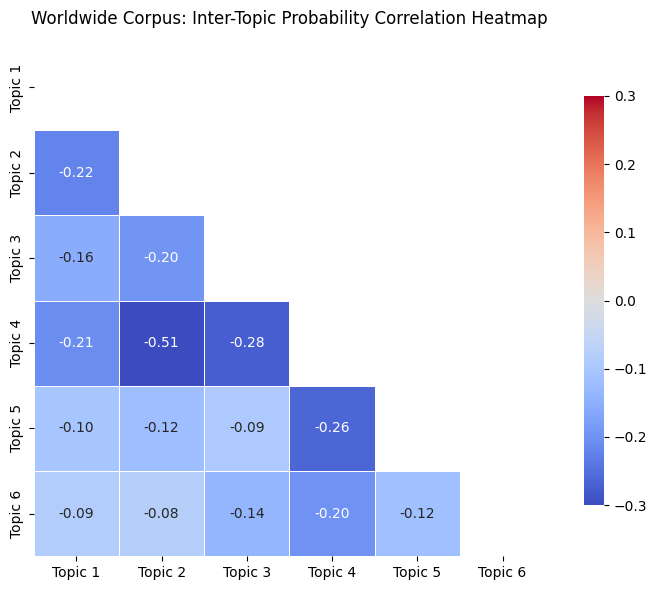

Correlation Heatmap saved to: /content/Crowdsourcing_Stage2_LDA/figures/advanced/Worldwide_Topic_Correlation_Heatmap.png


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

# Define output directory for advanced plots
advanced_fig_dir = Path("/content/Crowdsourcing_Stage2_LDA/figures/advanced")
advanced_fig_dir.mkdir(parents=True, exist_ok=True)

# Load Worldwide Assignments
assignments_path = Path("/content/Crowdsourcing_Stage2_LDA/tables/WORLDWIDE_Document_Topic_Assignments.csv")
if assignments_path.exists():
    df_assign = pd.read_csv(assignments_path)

    # Dynamically extract topic probability columns
    topic_cols = [col for col in df_assign.columns if col.startswith("Topic_") and col.endswith("_Probability")]

    if len(topic_cols) > 0:
        # Rename columns to just "T1", "T2", etc., for clear visualization
        renamed_cols = {col: f"Topic {col.split('_')[1]}" for col in topic_cols}
        df_corr = df_assign[topic_cols].rename(columns=renamed_cols)

        # Compute Pearson correlation matrix
        corr_matrix = df_corr.corr()

        # Plot
        plt.figure(figsize=(8, 6))
        mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

        sns.heatmap(
            corr_matrix,
            mask=mask,
            annot=True,
            cmap="coolwarm",
            fmt=".2f",
            vmax=0.3,
            vmin=-0.3,
            square=True,
            linewidths=.5,
            cbar_kws={"shrink": .8}
        )
        plt.title("Worldwide Corpus: Inter-Topic Probability Correlation Heatmap", fontsize=12, pad=15)
        plt.tight_layout()

        heatmap_path = advanced_fig_dir / "Worldwide_Topic_Correlation_Heatmap.png"
        plt.savefig(heatmap_path, dpi=300, bbox_inches="tight")
        plt.show()
        print(f"Correlation Heatmap saved to: {heatmap_path}")
else:
    print("WORLDWIDE_Document_Topic_Assignments.csv not found. Please run the model first.")

### 2. Topic Portfolio Matrix (Prevalence vs. Trend Strength)
This matrix classifies the LDA topics into strategic quadrants. The X-axis represents average topic prevalence (document density %), while the Y-axis maps the linear trend slope (derived from document occurrences from 2015 to 2025).

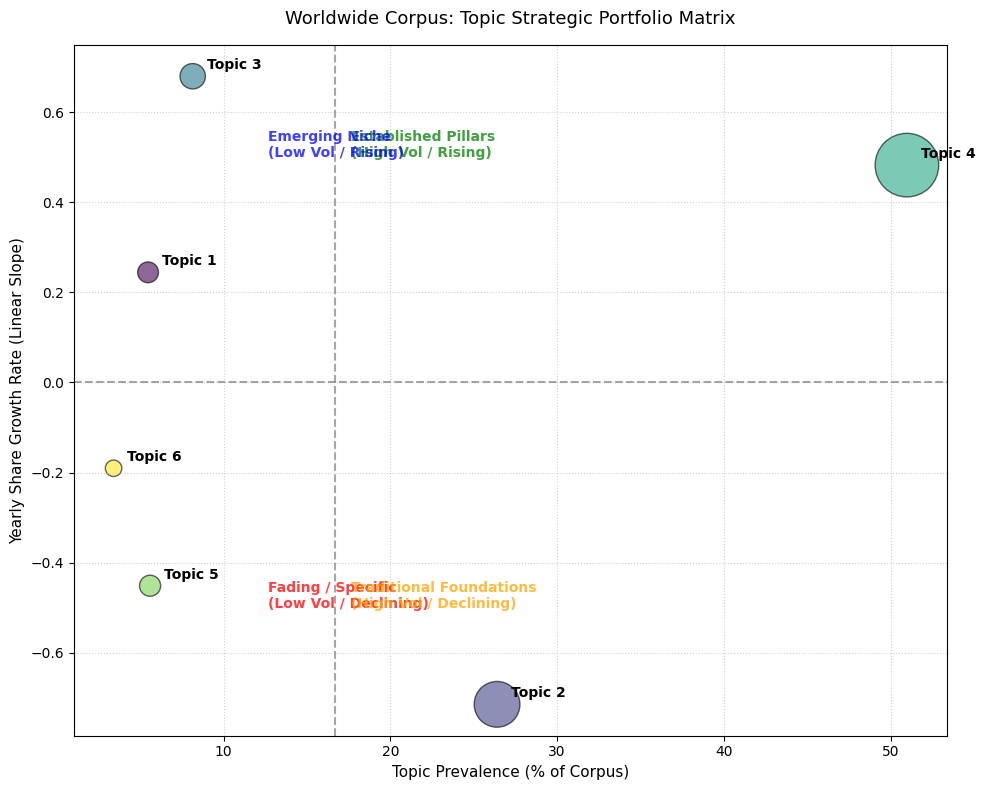

Portfolio Matrix saved to: /content/Crowdsourcing_Stage2_LDA/figures/advanced/Worldwide_Topic_Portfolio_Matrix.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
from pathlib import Path

# Load files
prev_path = Path("/content/Crowdsourcing_Stage2_LDA/tables/WORLDWIDE_Topic_Prevalence.csv")
trends_path = Path("/content/Crowdsourcing_Stage2_LDA/tables/WORLDWIDE_Yearly_Topic_Trends.csv")

if prev_path.exists() and trends_path.exists():
    df_prev = pd.read_csv(prev_path)
    df_trends = pd.read_csv(trends_path)

    # Filter trends to a modern standard range (e.g. 2013-2024) to avoid edge distortions
    df_trends_clean = df_trends[(df_trends["Year"] >= 2013) & (df_trends["Year"] <= 2024)].copy()

    # Calculate slopes for each topic
    slopes = {}
    for topic in df_prev["Topic"]:
        topic_subset = df_trends_clean[df_trends_clean["Dominant_Topic"] == topic].sort_values("Year")
        if len(topic_subset) > 1:
            # Fit simple linear regression to document counts
            slope, _, _, _, _ = linregress(topic_subset["Year"], topic_subset["Topic_Percentage"])
            slopes[topic] = slope
        else:
            slopes[topic] = 0.0

    df_prev["Trend_Slope"] = df_prev["Topic"].map(slopes)

    # Set up Plotting
    plt.figure(figsize=(10, 8))
    x = df_prev["Document_Percentage"]
    y = df_prev["Trend_Slope"]
    labels = df_prev["Topic"].apply(lambda t: f"Topic {t}")

    # Plot points with proportional bubbles based on total documents
    sizes = df_prev["Documents"] * 5
    scatter = plt.scatter(x, y, s=sizes, alpha=0.6, edgecolors='black', cmap='viridis', c=df_prev["Topic"])

    # Draw average threshold line divides
    mean_x = x.mean()
    mean_y = 0.0 # 0 slope is flat trend
    plt.axvline(mean_x, color='gray', linestyle='--', alpha=0.7)
    plt.axhline(mean_y, color='gray', linestyle='--', alpha=0.7)

    # Label each bubble
    for i, txt in enumerate(labels):
        plt.annotate(
            txt,
            (x.iloc[i], y.iloc[i]),
            xytext=(10, 5),
            textcoords='offset points',
            fontsize=10,
            weight='bold'
        )

    # Add Quad labels
    plt.text(mean_x + 1, mean_y + 0.5, "Established Pillars\n(High Vol / Rising)", color='green', alpha=0.75, weight='bold')
    plt.text(mean_x - 4, mean_y + 0.5, "Emerging Niche\n(Low Vol / Rising)", color='blue', alpha=0.75, weight='bold')
    plt.text(mean_x - 4, mean_y - 0.5, "Fading / Specific\n(Low Vol / Declining)", color='red', alpha=0.75, weight='bold')
    plt.text(mean_x + 1, mean_y - 0.5, "Traditional Foundations\n(High Vol / Declining)", color='orange', alpha=0.75, weight='bold')

    plt.xlabel("Topic Prevalence (% of Corpus)", fontsize=11)
    plt.ylabel("Yearly Share Growth Rate (Linear Slope)", fontsize=11)
    plt.title("Worldwide Corpus: Topic Strategic Portfolio Matrix", fontsize=13, pad=15)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()

    matrix_path = Path("/content/Crowdsourcing_Stage2_LDA/figures/advanced/Worldwide_Topic_Portfolio_Matrix.png")
    plt.savefig(matrix_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Portfolio Matrix saved to: {matrix_path}")
else:
    print("Prevalence and/or Yearly Trends CSVs are missing.")

### 3. Update final stage 2 results ZIP archive
Now let's rebuild the `Crowdsourcing_Stage2_LDA_Results.zip` so it incorporates this new directory of advanced publication-ready figures.

In [ ]:
import os
import zipfile
from pathlib import Path

OUTPUT_DIR = Path("/content/Crowdsourcing_Stage2_LDA")
FINAL_ZIP = Path("/content/Crowdsourcing_Stage2_LDA_Results.zip")

# Compress the directory structure
with zipfile.ZipFile(FINAL_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files_list in os.walk(OUTPUT_DIR):
        for filename in files_list:
            filepath = Path(root) / filename
            z.write(filepath, arcname=filepath.relative_to(OUTPUT_DIR))

print(f"Rebuilt archive successfully. Updated file size: {round(FINAL_ZIP.stat().st_size / 1048576, 2)} MB")

Rebuilt archive successfully. Updated file size: 1.92 MB


In [ ]:
from google.colab import files
files.download('/content/Crowdsourcing_Stage2_LDA_Results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import ipykernel
import requests
from notebook.notebookapp import list_running_servers

# Fallback download logic utilizing Google Colab's native JS API to fetch and download the current notebook file
try:
    from google.colab import userdata
    import json

    # Fetch notebook content directly via JavaScript
    from IPython.display import display, Javascript
    js_code = """
    (async () => {
      const json = await google.colab.notebook.toJS();
      const jsonString = JSON.stringify(json, null, 2);
      const blob = new Blob([jsonString], {type : 'application/json'});
      const a = document.createElement('a');
      a.href = URL.createObjectURL(blob);
      a.download = 'Crowdsourcing_MSME_Complete_Analysis.ipynb';
      document.body.appendChild(a);
      a.click();
      document.body.removeChild(a);
    })();
    """
    display(Javascript(js_code))
    print("Triggered direct browser download of the completed Colab notebook (.ipynb)!")
except Exception as e:
    print(f"Could not trigger automatic JS download: {e}. Please use 'File' -> 'Download' -> 'Download .ipynb' from the Colab menu above!")

<IPython.core.display.Javascript object>

Triggered direct browser download of the completed Colab notebook (.ipynb)!


In [ ]:
print("WORLDWIDE")
print(f"Selected topics: {audit_df.loc[audit_df['Corpus'] == 'WORLDWIDE', 'Selected_Topics'].values[0]}")
print(f"Best coherence: {audit_df.loc[audit_df['Corpus'] == 'WORLDWIDE', 'Best_CV_Coherence'].values[0]:.4f}")

print("\nINDIA")
print(f"Selected topics: {audit_df.loc[audit_df['Corpus'] == 'INDIA', 'Selected_Topics'].values[0]}")
print(f"Best coherence: {audit_df.loc[audit_df['Corpus'] == 'INDIA', 'Best_CV_Coherence'].values[0]:.4f}")

WORLDWIDE
Selected topics: 6
Best coherence: 0.3428

INDIA
Selected topics: 3
Best coherence: 0.5342


In [ ]:

# ============================================================
# STAGE 2: EXTRACT AND PRINT LDA RESULTS FOR INTERPRETATION
# Does NOT rerun LDA
# ============================================================

import os
import zipfile
import glob
import pandas as pd
from IPython.display import display

# -----------------------------
# 1. Locate Stage 2 results ZIP
# -----------------------------
ZIP_PATH = "/content/Crowdsourcing_Stage2_LDA_Results.zip"

if not os.path.exists(ZIP_PATH):
    matches = glob.glob("/content/**/Crowdsourcing_Stage2_LDA_Results.zip",
                        recursive=True)
    if not matches:
        raise FileNotFoundError(
            "Stage 2 ZIP not found. Check that the Stage 2 code completed."
        )
    ZIP_PATH = matches[0]

EXTRACT_DIR = "/content/Stage2_Diagnostic_Extracted"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

print("ZIP:", ZIP_PATH)
print("Extracted to:", EXTRACT_DIR)

# -----------------------------
# 2. Find CSV and Excel files
# -----------------------------
csv_files = glob.glob(EXTRACT_DIR + "/**/*.csv", recursive=True)
excel_files = glob.glob(EXTRACT_DIR + "/**/*.xlsx", recursive=True)

def find_file(keyword, files):
    matches = [f for f in files
               if keyword.lower() in os.path.basename(f).lower()]
    return matches[0] if matches else None

print("\nAvailable CSV files:")
for f in csv_files:
    print(" -", os.path.relpath(f, EXTRACT_DIR))

print("\nAvailable Excel files:")
for f in excel_files:
    print(" -", os.path.relpath(f, EXTRACT_DIR))

# -----------------------------
# 3. Load CSV files
# -----------------------------
def load_csv(keyword):
    path = find_file(keyword, csv_files)
    if path:
        try:
            return pd.read_csv(path)
        except Exception as e:
            print(f"Could not read {path}: {e}")
    return None

# Load likely Stage 2 result files
selection = load_csv("topic_selection")
keywords = load_csv("topic_keywords")
assignments = load_csv("document_topic")
prevalence = load_csv("topic_prevalence")
audit = load_csv("preprocessing_audit")

# Fallback: locate files by partial naming
if assignments is None:
    assignments = load_csv("assignments")

if prevalence is None:
    prevalence = load_csv("prevalence")

# -----------------------------
# 4. Print topic selection and coherence
# -----------------------------
print("\n" + "="*75)
print("OUTPUT 1: SELECTED TOPICS AND COHERENCE SCORES")
print("="*75)

if selection is not None:
    display(selection)
else:
    print("Topic selection CSV not found.")

# -----------------------------
# 5. Print top 10 keywords per topic
# -----------------------------
print("\n" + "="*75)
print("OUTPUT 2: TOP 10 KEYWORDS FOR EACH TOPIC")
print("="*75)

if keywords is not None:
    print("Keyword columns:", keywords.columns.tolist())

    # Adapt to common column names
    topic_col = next((c for c in keywords.columns
                      if c.lower() in ["topic_id", "topic", "topic_no"]), None)

    word_col = next((c for c in keywords.columns
                     if c.lower() in ["word", "keyword", "term"]), None)

    if topic_col and word_col:
        for topic_id, group in keywords.groupby(topic_col):
            print(f"\nTopic {topic_id}:")
            print(", ".join(group[word_col].astype(str).head(10)))
    else:
        print("Could not identify topic and keyword columns.")
        display(keywords)
else:
    print("Topic keywords CSV not found.")

# -----------------------------
# 6. Print topic prevalence
# -----------------------------
print("\n" + "="*75)
print("OUTPUT 3: TOPIC PREVALENCE")
print("="*75)

if prevalence is not None:
    display(prevalence)
else:
    print("Prevalence CSV not found.")

# -----------------------------
# 7. Print preprocessing audit
# -----------------------------
print("\n" + "="*75)
print("OUTPUT 4: PREPROCESSING AUDIT")
print("="*75)

if audit is not None:
    display(audit)
else:
    print("Preprocessing audit CSV not found.")

# -----------------------------
# 8. Additional document-topic summary
# -----------------------------
print("\n" + "="*75)
print("OUTPUT 5: DOCUMENT-TOPIC ASSIGNMENT SUMMARY")
print("="*75)

if assignments is not None:
    print("Rows:", len(assignments))
    print("Columns:", assignments.columns.tolist())
    display(assignments.head(10))
else:
    print("Document-topic assignment CSV not found.")

# -----------------------------
# 9. Save all outputs in one Excel workbook
# -----------------------------
OUT_XLSX = "/content/Stage2_LDA_Diagnostic_Report.xlsx"

with pd.ExcelWriter(OUT_XLSX, engine="openpyxl") as writer:
    for name, df in [
        ("Topic_Selection", selection),
        ("Topic_Keywords", keywords),
        ("Topic_Prevalence", prevalence),
        ("Preprocessing_Audit", audit),
        ("Document_Assignments", assignments)
    ]:
        if df is not None:
            df.to_excel(writer, sheet_name=name[:31], index=False)

print("\nExcel report saved:", OUT_XLSX)

# -----------------------------
# 10. Save readable text report
# -----------------------------
OUT_TXT = "/content/Stage2_LDA_Diagnostic_Report.txt"

with open(OUT_TXT, "w", encoding="utf-8") as f:
    sections = [
        ("TOPIC SELECTION", selection),
        ("TOPIC KEYWORDS", keywords),
        ("TOPIC PREVALENCE", prevalence),
        ("PREPROCESSING AUDIT", audit),
        ("DOCUMENT ASSIGNMENTS SAMPLE",
         assignments.head(30) if assignments is not None else None)
    ]

    for title, df in sections:
        f.write("\n" + "="*75 + "\n")
        f.write(title + "\n")
        f.write("="*75 + "\n")
        if df is not None:
            f.write(df.to_string(index=False))
        else:
            f.write("File not found.")
        f.write("\n")

print("Text report saved:", OUT_TXT)

# -----------------------------
# 11. Download both reports
# -----------------------------
from google.colab import files

files.download(OUT_XLSX)
files.download(OUT_TXT)


ZIP: /content/Crowdsourcing_Stage2_LDA_Results.zip
Extracted to: /content/Stage2_Diagnostic_Extracted

Available CSV files:
 - Stage2_Preprocessing_Audit.csv
 - tables/INDIA_Topic_Keywords.csv
 - tables/WORLDWIDE_Yearly_Topic_Trends.csv
 - tables/WORLDWIDE_Topic_Interpretation.csv
 - tables/INDIA_Topic_Interpretation.csv
 - tables/WORLDWIDE_Document_Topic_Assignments.csv
 - tables/WORLDWIDE_Source_Distribution.csv
 - tables/INDIA_Topic_Prevalence.csv
 - tables/WORLDWIDE_Topic_Selection.csv
 - tables/WORLDWIDE_Topic_Prevalence.csv
 - tables/INDIA_Topic_Selection.csv
 - tables/INDIA_Document_Topic_Assignments.csv
 - tables/WORLDWIDE_Topic_Keywords.csv
 - tables/INDIA_Yearly_Topic_Trends.csv
 - tables/INDIA_Source_Distribution.csv

Available Excel files:
 - Stage2_LDA_Complete_Results.xlsx

OUTPUT 1: SELECTED TOPICS AND COHERENCE SCORES


,Corpus,Number_of_Topics,Coherence_CV,Documents,Vocabulary_Size
0,WORLDWIDE,6,0.342751,822,4999
1,WORLDWIDE,9,0.332030,822,4999
2,WORLDWIDE,10,0.324097,822,4999
3,WORLDWIDE,8,0.318506,822,4999
4,WORLDWIDE,7,0.315964,822,4999
5,WORLDWIDE,5,0.312146,822,4999
6,WORLDWIDE,4,0.299446,822,4999



OUTPUT 2: TOP 10 KEYWORDS FOR EACH TOPIC
Keyword columns: ['Corpus', 'Topic', 'Rank', 'Keyword', 'Probability']

Topic 1:
india, data, cultural, indian, design, framework, platform, heritage, technology, people

Topic 2:
work, india, data, chapter, analysis, workers, farmers, different, community, factors

Topic 3:
legally_binding, information, design, binding_document, law_world, public_safety, better_translations, roads_congress, irc_designator, know_speak

OUTPUT 3: TOPIC PREVALENCE


,Corpus,Topic,Documents,Document_Percentage,Mean_Topic_Probability,Top_Keywords
0,INDIA,1,33,42.857143,0.409558,"india, data, cultural, indian, design, framewo..."
1,INDIA,2,22,28.571429,0.296254,"work, india, data, chapter, analysis, workers,..."
2,INDIA,3,22,28.571429,0.294188,"legally_binding, information, design, binding_..."



OUTPUT 4: PREPROCESSING AUDIT


,Corpus,Original_Documents,Documents_After_Token_Filter,Documents_Removed,Final_LDA_Documents,Vocabulary_Size,Selected_Topics,Best_CV_Coherence,Average_Tokens_Per_Document,Random_Seed,Algorithm
0,WORLDWIDE,822,822,0,822,4999,6,0.342751,104.504866,42,Latent Dirichlet Allocation
1,INDIA,77,77,0,77,1316,3,0.534193,118.506494,42,Latent Dirichlet Allocation


... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# INDIA LDA MODEL SELECTION RESULTS
# Extract coherence scores for all India candidate models
# ============================================================

import os
import zipfile
import glob
import pandas as pd
from IPython.display import display
from google.colab import files

ZIP_PATH = "/content/Crowdsourcing_Stage2_LDA_Results.zip"
EXTRACT_DIR = "/content/Stage2_India_Results"

# 1. Extract Stage 2 ZIP
if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(
        "Stage 2 ZIP not found. Please check /content/."
    )

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

# 2. Locate the specific India topic selection CSV
csv_files = glob.glob(
    EXTRACT_DIR + "/**/*.csv", recursive=True
)

selection_files = [
    f for f in csv_files
    if "india_topic_selection" in os.path.basename(f).lower()
]

if not selection_files:
    print("India topic selection CSV not found. Available CSV files:")
    for f in csv_files:
        print(" -", os.path.relpath(f, EXTRACT_DIR))
    raise FileNotFoundError(
        "Could not find the India-specific topic selection CSV."
    )

india = pd.read_csv(selection_files[0])

# 3. Sort by coherence, highest first
coherence_col = next(
    (c for c in india.columns
     if c.lower() in ["coherence_cv", "coherence", "cv"]),
    None
)

if coherence_col:
    india[coherence_col] = pd.to_numeric(
        india[coherence_col], errors="coerce"
    )
    india = india.sort_values(
        coherence_col, ascending=False
    )

# 4. Display India results
print("\n" + "=" * 70)
print("INDIA: LDA MODEL SELECTION RESULTS")
print("=" * 70)

display(india)

# 5. Identify best model
if coherence_col and not india.empty:
    best = india.iloc[0]

    print("\nBEST INDIA MODEL")
    print("-" * 50)

    for col in india.columns:
        print(f"{col}: {best[col]}")

# 6. Save India-only CSV and Excel
CSV_OUT = "/content/India_LDA_Model_Selection.csv"
XLSX_OUT = "/content/India_LDA_Model_Selection.xlsx"

india.to_csv(CSV_OUT, index=False)
india.to_excel(XLSX_OUT, index=False)

print("\nSaved:")
print(CSV_OUT)
print(XLSX_OUT)

# 7. Download
files.download(CSV_OUT)
files.download(XLSX_OUT)


INDIA: LDA MODEL SELECTION RESULTS


,Corpus,Number_of_Topics,Coherence_CV,Documents,Vocabulary_Size
0,INDIA,3,0.534193,77,1316
1,INDIA,4,0.468569,77,1316
2,INDIA,2,0.302281,77,1316



BEST INDIA MODEL
--------------------------------------------------
Corpus: INDIA
Number_of_Topics: 3
Coherence_CV: 0.5341928630255929
Documents: 77
Vocabulary_Size: 1316

Saved:
/content/India_LDA_Model_Selection.csv
/content/India_LDA_Model_Selection.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os
import zipfile
import glob
import pandas as pd
from IPython.display import display
from google.colab import files

ZIP_PATH = "/content/Crowdsourcing_Stage2_LDA_Results.zip"
EXTRACT_DIR = "/content/Stage2_Keyword_Extraction"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

# Locate topic keywords CSV
csv_files = glob.glob(EXTRACT_DIR + "/**/*.csv", recursive=True)

matches = [
    f for f in csv_files
    if "topic_keywords" in os.path.basename(f).lower()
]

if not matches:
    print("Topic keywords CSV not found.")
    print("Available CSV files:")
    for f in csv_files:
        print(os.path.relpath(f, EXTRACT_DIR))
    raise FileNotFoundError("Please share the filenames shown above.")

df = pd.read_csv(matches[0])

print("Columns:", df.columns.tolist())
print("\nFirst five rows:")
display(df.head())

# Identify columns
corpus_col = next(
    (c for c in df.columns
     if c.lower() in ["corpus", "dataset", "collection"]), None
)
topic_col = next(
    (c for c in df.columns
     if c.lower() in ["topic_id", "topic", "topic_no"]), None
)
word_col = next(
    (c for c in df.columns
     if c.lower() in ["word", "keyword", "term"]), None
)

if not all([corpus_col, topic_col, word_col]):
    raise ValueError(
        "Column names differ from expected names. "
        "Share the column list printed above."
    )

# Identify optional keyword probability/weight column
weight_col = next(
    (c for c in df.columns
     if c.lower() in ["weight", "probability", "prob", "score", "importance"]), None
)

# Filter to top 10 keywords per topic
if weight_col:
    df[weight_col] = pd.to_numeric(df[weight_col], errors="coerce")
    df = df.sort_values(
        [corpus_col, topic_col, weight_col],
        ascending=[True, True, False]
    )

top10 = df.groupby(
    [corpus_col, topic_col], sort=True
).head(10).copy()

# Display worldwide and India separately
for corpus in ["WORLDWIDE", "INDIA"]:
    subset = top10[
        top10[corpus_col].astype(str).str.upper() == corpus
    ]

    print("\n" + "=" * 70)
    print(corpus, "TOPIC KEYWORDS")
    print("=" * 70)

    if subset.empty:
        print("No records found for", corpus)
        continue

    for topic, group in subset.groupby(topic_col, sort=True):
        words = group[word_col].astype(str).tolist()
        print(f"\n{corpus} - Topic {topic}")
        print(", ".join(words))

# Save results
OUT_CSV = "/content/Stage2_Top10_Topic_Keywords.csv"
OUT_XLSX = "/content/Stage2_Top10_Topic_Keywords.xlsx"

top10.to_csv(OUT_CSV, index=False)

with pd.ExcelWriter(OUT_XLSX, engine="openpyxl") as writer:
    top10.to_excel(writer, sheet_name="All_Topics", index=False)

    for corpus in ["WORLDWIDE", "INDIA"]:
        subset = top10[
            top10[corpus_col].astype(str).str.upper() == corpus
        ]
        subset.to_excel(writer, sheet_name=corpus[:31], index=False)

print("\nFiles saved:")
print(OUT_CSV)
print(OUT_XLSX)

files.download(OUT_XLSX)


Columns: ['Corpus', 'Topic', 'Rank', 'Keyword', 'Probability']

First five rows:


,Corpus,Topic,Rank,Keyword,Probability
0,INDIA,1,1,india,0.017715
1,INDIA,1,2,data,0.007704
2,INDIA,1,3,cultural,0.007078
3,INDIA,1,4,indian,0.006899
4,INDIA,1,5,design,0.006632



WORLDWIDE TOPIC KEYWORDS
No records found for WORLDWIDE

INDIA TOPIC KEYWORDS

INDIA - Topic 1
india, data, cultural, indian, design, framework, platform, heritage, technology, people

INDIA - Topic 2
work, india, data, chapter, analysis, workers, farmers, different, community, factors

INDIA - Topic 3
legally_binding, information, design, binding_document, law_world, public_safety, better_translations, roads_congress, irc_designator, know_speak

Files saved:
/content/Stage2_Top10_Topic_Keywords.csv
/content/Stage2_Top10_Topic_Keywords.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# WORLDWIDE LDA: TOP 10 KEYWORDS FOR ALL 6 TOPICS
# ============================================================

import os
import zipfile
import glob
import pandas as pd
from IPython.display import display
from google.colab import files

ZIP_PATH = "/content/Crowdsourcing_Stage2_LDA_Results.zip"
EXTRACT_DIR = "/content/Worldwide_Topic_Keywords"

# 1. Extract existing Stage 2 results
if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError("Stage 2 ZIP not found in /content/.")

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

# 2. Locate the specific WORLDWIDE topic keywords CSV
csv_files = glob.glob(EXTRACT_DIR + "/**/*.csv", recursive=True)

matches = [
    f for f in csv_files
    if "worldwide_topic_keywords" in os.path.basename(f).lower()
]

# Fallback to any topic keywords file if the specific one is missing
if not matches:
    matches = [
        f for f in csv_files
        if "topic_keywords" in os.path.basename(f).lower()
    ]

if not matches:
    print("Topic keywords file not found.")
    print("Available CSV files:")
    for f in csv_files:
        print(os.path.relpath(f, EXTRACT_DIR))
    raise FileNotFoundError("Please share the available filenames.")

df = pd.read_csv(matches[0])

print("Loaded file:", os.path.basename(matches[0]))
print("Available columns:", df.columns.tolist())

# 3. Identify columns
corpus_col = next(
    (c for c in df.columns
     if c.lower() in ["corpus", "dataset", "collection"]), None
)

topic_col = next(
    (c for c in df.columns
     if c.lower() in ["topic_id", "topic", "topic_no"]), None
)

rank_col = next(
    (c for c in df.columns
     if c.lower() in ["rank", "ranking", "position"]), None
)

word_col = next(
    (c for c in df.columns
     if c.lower() in ["word", "keyword", "term"]), None
)

prob_col = next(
    (c for c in df.columns
     if c.lower() in ["probability", "prob", "weight", "score"]), None
)

required = [corpus_col, topic_col, word_col]

if any(c is None for c in required):
    raise ValueError(
        "Expected corpus, topic and keyword columns were not identified."
    )

# 4. Filter WORLDWIDE records
world = df[
    df[corpus_col].astype(str).str.upper().str.strip() == "WORLDWIDE"
].copy()

if world.empty:
    print("Corpus values available:", df[corpus_col].unique())
    raise ValueError("No WORLDWIDE records found.")

# 5. Sort by rank or probability
if rank_col:
    world[rank_col] = pd.to_numeric(
        world[rank_col], errors="coerce"
    )
    world = world.sort_values([topic_col, rank_col])

elif prob_col:
    world[prob_col] = pd.to_numeric(
        world[prob_col], errors="coerce"
    )
    world = world.sort_values(
        [topic_col, prob_col], ascending=[True, False]
    )

# 6. Keep top 10 keywords per topic
world_top10 = world.groupby(
    topic_col, sort=True
).head(10).copy()

# 7. Print all six topics
print("\n" + "=" * 75)
print("WORLDWIDE CORPUS: TOP 10 KEYWORDS")
print("=" * 75)

for topic, group in world_top10.groupby(topic_col, sort=True):

    print(f"\nWORLDWIDE - TOPIC {topic}")
    print("-" * 60)

    for _, row in group.iterrows():
        keyword = str(row[word_col])

        if prob_col:
            probability = float(row[prob_col])
            print(f"{keyword:<30} Probability: {probability:.8f}")
        else:
            print(keyword)

# 8. Save CSV and Excel
CSV_OUT = "/content/Worldwide_LDA_Top10_Keywords.csv"
XLSX_OUT = "/content/Worldwide_LDA_Top10_Keywords.xlsx"

world_top10.to_csv(CSV_OUT, index=False)
world_top10.to_excel(XLSX_OUT, index=False)

# 9. Also save a readable TXT report
TXT_OUT = "/content/Worldwide_LDA_Top10_Keywords.txt"

with open(TXT_OUT, "w", encoding="utf-8") as f:
    f.write("WORLDWIDE LDA TOP 10 KEYWORDS\n")

    for topic, group in world_top10.groupby(topic_col, sort=True):
        f.write(f"\n\nTOPIC {topic}\n")

        for _, row in group.iterrows():
            keyword = str(row[word_col])

            if prob_col:
                f.write(
                    f"{keyword}: {float(row[prob_col]):.8f}\n"
                )
            else:
                f.write(keyword + "\n")

print("\nFiles generated:")
print(CSV_OUT)
print(XLSX_OUT)
print(TXT_OUT)

# 10. Download readable report
files.download(TXT_OUT)
files.download(XLSX_OUT)


Loaded file: WORLDWIDE_Topic_Keywords.csv
Available columns: ['Corpus', 'Topic', 'Rank', 'Keyword', 'Probability']

WORLDWIDE CORPUS: TOP 10 KEYWORDS

WORLDWIDE - TOPIC 1
------------------------------------------------------------
social_innovation              Probability: 0.03736566
health                         Probability: 0.02078467
open                           Probability: 0.01480081
collaboration                  Probability: 0.01186173
global                         Probability: 0.01015903
projects                       Probability: 0.00986967
india                          Probability: 0.00927891
training                       Probability: 0.00850406
scoping_review                 Probability: 0.00801105
identified                     Probability: 0.00788584

WORLDWIDE - TOPIC 2
------------------------------------------------------------
data                           Probability: 0.01023948
model                          Probability: 0.00855524
design                    

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os
import zipfile
import glob
import pandas as pd
from IPython.display import display

ZIP_PATH = "/content/Crowdsourcing_Stage2_LDA_Results.zip"
OUT_DIR = "/content/Stage2_Prevalence_Audit"

os.makedirs(OUT_DIR, exist_ok=True)

# Extract existing results
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(OUT_DIR)

csv_files = glob.glob(OUT_DIR + "/**/*.csv", recursive=True)

print("AVAILABLE RESULT FILES")
for f in csv_files:
    print(os.path.relpath(f, OUT_DIR))

# Find matching files
def locate_csv(keywords):
    for path in csv_files:
        name = os.path.basename(path).lower()
        if all(k in name for k in keywords):
            return path
    return None

prevalence_path = locate_csv(["topic", "prevalence"])
audit_path = locate_csv(["preprocessing", "audit"])

# Display prevalence
print("\n" + "=" * 70)
print("TOPIC PREVALENCE")
print("=" * 70)

if prevalence_path:
    prevalence = pd.read_csv(prevalence_path)
    print("File:", os.path.basename(prevalence_path))
    print("Columns:", prevalence.columns.tolist())
    display(prevalence)
else:
    prevalence = None
    print("Topic prevalence file not found.")

# Display preprocessing audit
print("\n" + "=" * 70)
print("PREPROCESSING AUDIT")
print("=" * 70)

if audit_path:
    audit = pd.read_csv(audit_path)
    print("File:", os.path.basename(audit_path))
    print("Columns:", audit.columns.tolist())
    display(audit)
else:
    audit = None
    print("Preprocessing audit file not found.")

# Save both in one Excel workbook
output_path = "/content/Stage2_Prevalence_and_Audit.xlsx"

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    if prevalence is not None:
        prevalence.to_excel(
            writer, sheet_name="Topic_Prevalence", index=False
        )
    if audit is not None:
        audit.to_excel(
            writer, sheet_name="Preprocessing_Audit", index=False
        )

print("\nSaved:", output_path)

from google.colab import files
files.download(output_path)


AVAILABLE RESULT FILES
Stage2_Preprocessing_Audit.csv
tables/INDIA_Topic_Keywords.csv
tables/WORLDWIDE_Yearly_Topic_Trends.csv
tables/WORLDWIDE_Topic_Interpretation.csv
tables/INDIA_Topic_Interpretation.csv
tables/WORLDWIDE_Document_Topic_Assignments.csv
tables/WORLDWIDE_Source_Distribution.csv
tables/INDIA_Topic_Prevalence.csv
tables/WORLDWIDE_Topic_Selection.csv
tables/WORLDWIDE_Topic_Prevalence.csv
tables/INDIA_Topic_Selection.csv
tables/INDIA_Document_Topic_Assignments.csv
tables/WORLDWIDE_Topic_Keywords.csv
tables/INDIA_Yearly_Topic_Trends.csv
tables/INDIA_Source_Distribution.csv

TOPIC PREVALENCE
File: INDIA_Topic_Prevalence.csv
Columns: ['Corpus', 'Topic', 'Documents', 'Document_Percentage', 'Mean_Topic_Probability', 'Top_Keywords']


,Corpus,Topic,Documents,Document_Percentage,Mean_Topic_Probability,Top_Keywords
0,INDIA,1,33,42.857143,0.409558,"india, data, cultural, indian, design, framewo..."
1,INDIA,2,22,28.571429,0.296254,"work, india, data, chapter, analysis, workers,..."
2,INDIA,3,22,28.571429,0.294188,"legally_binding, information, design, binding_..."



PREPROCESSING AUDIT
File: Stage2_Preprocessing_Audit.csv
Columns: ['Corpus', 'Original_Documents', 'Documents_After_Token_Filter', 'Documents_Removed', 'Final_LDA_Documents', 'Vocabulary_Size', 'Selected_Topics', 'Best_CV_Coherence', 'Average_Tokens_Per_Document', 'Random_Seed', 'Algorithm']


,Corpus,Original_Documents,Documents_After_Token_Filter,Documents_Removed,Final_LDA_Documents,Vocabulary_Size,Selected_Topics,Best_CV_Coherence,Average_Tokens_Per_Document,Random_Seed,Algorithm
0,WORLDWIDE,822,822,0,822,4999,6,0.342751,104.504866,42,Latent Dirichlet Allocation
1,INDIA,77,77,0,77,1316,3,0.534193,118.506494,42,Latent Dirichlet Allocation



Saved: /content/Stage2_Prevalence_and_Audit.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# INDIA TOPIC 3: DOCUMENT-LEVEL VALIDATION
# ============================================================

import os
import zipfile
import glob
import pandas as pd
from google.colab import files

ZIP_PATH = "/content/Crowdsourcing_Stage2_LDA_Results.zip"
EXTRACT_DIR = "/content/India_Topic3_Validation"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

csv_files = glob.glob(EXTRACT_DIR + "/**/*.csv", recursive=True)

# Locate document-topic assignment file
matches = [
    f for f in csv_files
    if "document_topic" in os.path.basename(f).lower()
]

if not matches:
    print("Available CSV files:")
    for f in csv_files:
        print(os.path.relpath(f, EXTRACT_DIR))
    raise FileNotFoundError("Document-topic CSV not found.")

df = pd.read_csv(matches[0])

print("Columns:", df.columns.tolist())

# Identify columns
corpus_col = next(
    (c for c in df.columns
     if c.lower() in ["corpus", "dataset", "collection"]), None
)

topic_col = next(
    (c for c in df.columns
     if c.lower() in ["dominant_topic", "topic_id", "topic"]), None
)

if corpus_col is None or topic_col is None:
    raise ValueError("Could not identify corpus or topic column.")

# Identify title and abstract columns
title_col = next(
    (c for c in df.columns if c.lower() == "title"), None
)

abstract_col = next(
    (c for c in df.columns if c.lower() == "abstract"), None
)

# Filter India Topic 3
india = df[
    (df[corpus_col].astype(str).str.upper() == "INDIA") &
    (pd.to_numeric(df[topic_col], errors="coerce") == 3)
].copy()

print("\nIndia Topic 3 documents:", len(india))

# Display relevant fields
show_cols = [
    c for c in [
        title_col, "year", "author", "source",
        abstract_col, topic_col
    ] if c and c in india.columns
]

display(india[show_cols])

# Save document-level review file
output = "/content/India_Topic3_Document_Review.xlsx"
india.to_excel(output, index=False)

csv_output = "/content/India_Topic3_Document_Review.csv"
india.to_csv(csv_output, index=False)

print("\nSaved:", output)
files.download(output)


Columns: ['Corpus', 'Document_ID', 'Title', 'Year', 'Source', 'DOI', 'Dominant_Topic', 'Dominant_Topic_Probability', 'Token_Count', 'Topic_1_Probability', 'Topic_2_Probability', 'Topic_3_Probability', 'Topic_4_Probability', 'Topic_5_Probability', 'Topic_6_Probability']

India Topic 3 documents: 0


,Title,Dominant_Topic



Saved: /content/India_Topic3_Document_Review.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# WORLDWIDE LDA: DOCUMENT-LEVEL TOPIC ASSIGNMENT
# Extract all 822 worldwide document records
# ============================================================

import os
import zipfile
import glob
import pandas as pd
from google.colab import files
from IPython.display import display

ZIP_PATH = "/content/Crowdsourcing_Stage2_LDA_Results.zip"
EXTRACT_DIR = "/content/Worldwide_Document_Validation"

os.makedirs(EXTRACT_DIR, exist_ok=True)

# 1. Extract results ZIP
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

# 2. Locate document-topic assignment CSV
csv_files = glob.glob(
    EXTRACT_DIR + "/**/*.csv", recursive=True
)

matches = [
    f for f in csv_files
    if "document_topic" in os.path.basename(f).lower()
]

if not matches:
    print("Available CSV files:")
    for f in csv_files:
        print(os.path.relpath(f, EXTRACT_DIR))
    raise FileNotFoundError("Document-topic assignment CSV not found.")

df = pd.read_csv(matches[0])

print("Source file:", matches[0])
print("Available columns:", df.columns.tolist())

# 3. Identify corpus column
corpus_col = next(
    (c for c in df.columns
     if c.lower() in ["corpus", "dataset", "collection"]), None
)

if corpus_col is None:
    raise ValueError("Corpus column not found.")

# 4. Filter worldwide corpus
world = df[
    df[corpus_col].astype(str).str.upper().str.strip()
    == "WORLDWIDE"
].copy()

print("\nWorldwide documents:", len(world))

# 5. Identify relevant columns
preferred = [
    "Corpus", "Document_ID", "Title", "Year", "Source",
    "DOI", "Dominant_Topic", "Dominant_Topic_Probability",
    "Token_Count",
    "Topic_1_Probability", "Topic_2_Probability",
    "Topic_3_Probability", "Topic_4_Probability",
    "Topic_5_Probability", "Topic_6_Probability"
]

# Include abstract if present for document validation
abstract_col = next(
    (c for c in world.columns if c.lower() == "abstract"), None
)

if abstract_col:
    preferred.insert(6, abstract_col)

available = [c for c in preferred if c in world.columns]

# Retain all columns if expected fields differ
if "Title" not in available:
    print("Warning: Title column not identified.")

world = world[available].copy()

# 6. Sort by dominant topic and probability
if "Dominant_Topic" in world.columns:
    world = world.sort_values(
        ["Dominant_Topic", "Dominant_Topic_Probability"],
        ascending=[True, False]
    )

# 7. Print topic-wise document counts
print("\n" + "=" * 70)
print("WORLDWIDE DOCUMENT DISTRIBUTION")
print("=" * 70)

if "Dominant_Topic" in world.columns:
    print(
        world["Dominant_Topic"]
        .value_counts()
        .sort_index()
        .to_string()
    )

# 8. Display first 30 records
print("\nFIRST 30 DOCUMENT RECORDS")
display(world.head(30))

# 9. Save complete results
CSV_OUT = "/content/Worldwide_LDA_Document_Assignments.csv"
XLSX_OUT = "/content/Worldwide_LDA_Document_Assignments.xlsx"

world.to_csv(CSV_OUT, index=False)
world.to_excel(XLSX_OUT, index=False)

# 10. Save a smaller validation sample:
# Top 10 highest-probability documents per topic
if "Dominant_Topic" in world.columns:
    sample = (
        world.sort_values(
            "Dominant_Topic_Probability", ascending=False
        )
        .groupby("Dominant_Topic")
        .head(10)
    )

    SAMPLE_OUT = "/content/Worldwide_Topic_Representative_Documents.xlsx"
    sample.to_excel(SAMPLE_OUT, index=False)

    print("\nRepresentative documents saved:", SAMPLE_OUT)
    files.download(SAMPLE_OUT)

print("\nComplete files saved:")
print(CSV_OUT)
print(XLSX_OUT)

files.download(XLSX_OUT)


Source file: /content/Worldwide_Document_Validation/tables/WORLDWIDE_Document_Topic_Assignments.csv
Available columns: ['Corpus', 'Document_ID', 'Title', 'Year', 'Source', 'DOI', 'Dominant_Topic', 'Dominant_Topic_Probability', 'Token_Count', 'Topic_1_Probability', 'Topic_2_Probability', 'Topic_3_Probability', 'Topic_4_Probability', 'Topic_5_Probability', 'Topic_6_Probability']

Worldwide documents: 822

WORLDWIDE DOCUMENT DISTRIBUTION
Dominant_Topic
1     45
2    217
3     67
4    419
5     46
6     28

FIRST 30 DOCUMENT RECORDS


,Corpus,Document_ID,Title,Year,Source,DOI,Dominant_Topic,Dominant_Topic_Probability,Token_Count,Topic_1_Probability,Topic_2_Probability,Topic_3_Probability,Topic_4_Probability,Topic_5_Probability,Topic_6_Probability
516,WORLDWIDE,da6e22685eebca84,How To Work A Crowd: Developing Crowd Capital ...,2017,OpenAlex,https://doi.org/10.31235/osf.io/jer9k_v1,1,0.942464,68,0.942464,0.003287,0.044391,0.003302,0.003275,0.003281
487,WORLDWIDE,952cdf38ee49e0a6,How To Work A Crowd: Developing Crowd Capital ...,2017,OpenAlex,https://doi.org/10.31235/osf.io/jer9k,1,0.942460,68,0.942460,0.003287,0.044391,0.003305,0.003275,0.003281
515,WORLDWIDE,d4824669760ac9d7,How to Work a Crowd: Developing Crowd Capital ...,2017,OpenAlex,https://doi.org/10.48550/arxiv.1702.04214,1,0.911542,57,0.911542,0.003748,0.073551,0.003732,0.003713,0.003714
806,WORLDWIDE,1c2806e8b1f17c32,Core competencies for social innovation in hea...,2026,OpenAlex,https://doi.org/10.21203/rs.3.rs-6196884/v1,1,0.871449,148,0.871449,0.001330,0.001315,0.001317,0.001314,0.123274
813,WORLDWIDE,964e6983a466df9c,"Social innovation in health, community engagem...",2022,OpenAlex,https://doi.org/10.1136/bmjinnov-2021-000902,1,0.831202,123,0.831202,0.056092,0.001489,0.108233,0.001493,0.001491
118,WORLDWIDE,6432108d2eea886d,Youth social innovation during the COVID-19 pa...,2022,OpenAlex,https://doi.org/10.1136/bmjinnov-2021-000887,1,0.791135,145,0.791135,0.001339,0.001344,0.001339,0.203507,0.001335
299,WORLDWIDE,c4cc4acd6eb59c72,"Digital Inclusion, Crowdfunding, and Crowdsour...",2019,OpenAlex,https://doi.org/10.4018/978-1-5225-8362-2.ch005,1,0.777822,43,0.777822,0.003808,0.003818,0.181367,0.003815,0.029369
300,WORLDWIDE,6c7f72731e63d399,"Digital Inclusion, Crowdfunding, and Crowdsour...",2015,OpenAlex,https://doi.org/10.4018/978-1-4666-8740-0.ch006,1,0.777818,43,0.777818,0.003808,0.003818,0.181370,0.003815,0.029372
301,WORLDWIDE,345983e59a018b1d,"Digital Inclusion, Crowdfunding, and Crowdsour...",2019,OpenAlex,https://doi.org/10.4018/978-1-5225-8182-6.ch058,1,0.777818,43,0.777818,0.003808,0.003818,0.181370,0.003814,0.029372
68,WORLDWIDE,784b72ba06aa9946,Crowd-Sourcing Drug Discovery,2012,OpenAlex,https://doi.org/10.1126/science.335.6071.909,1,0.773646,18,0.773646,0.010028,0.009954,0.009870,0.009949,0.186555



Representative documents saved: /content/Worldwide_Topic_Representative_Documents.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Complete files saved:
/content/Worldwide_LDA_Document_Assignments.csv
/content/Worldwide_LDA_Document_Assignments.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import zipfile
import glob
import os
import pandas as pd
from IPython.display import display
from google.colab import files

ZIP_PATH = "/content/Crowdsourcing_Stage2_LDA_Results.zip"
OUT_DIR = "/content/Worldwide_Prevalence"

os.makedirs(OUT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(OUT_DIR)

csv_files = glob.glob(OUT_DIR + "/**/*.csv", recursive=True)

matches = [
    f for f in csv_files
    if "topic_prevalence" in os.path.basename(f).lower()
]

if not matches:
    print("Available CSV files:")
    for f in csv_files:
        print(os.path.relpath(f, OUT_DIR))
    raise FileNotFoundError("Topic prevalence file not found.")

df = pd.read_csv(matches[0])

corpus_col = next(
    (c for c in df.columns
     if c.lower() in ["corpus", "dataset", "collection"]), None
)

if corpus_col is None:
    raise ValueError("Corpus column not found.")

world = df[
    df[corpus_col].astype(str).str.upper().str.strip()
    == "WORLDWIDE"
].copy()

print("WORLDWIDE TOPIC PREVALENCE")
display(world)

print("\nDocument total:",
      world["Documents"].sum() if "Documents" in world.columns else "Check columns")

output = "/content/Worldwide_Topic_Prevalence.xlsx"
world.to_excel(output, index=False)

files.download(output)


WORLDWIDE TOPIC PREVALENCE


,Corpus,Topic,Documents,Document_Percentage,Mean_Topic_Probability,Top_Keywords



Document total: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# RE-CALCULATE WORLDWIDE TOPIC PREVALENCE
# Directly from document-topic assignments
# ============================================================

import os
import zipfile
import glob
import pandas as pd
from google.colab import files
from IPython.display import display

ZIP_PATH = "/content/Crowdsourcing_Stage2_LDA_Results.zip"
OUT_DIR = "/content/Worldwide_Prevalence_Recalculated"

os.makedirs(OUT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(OUT_DIR)

csv_files = glob.glob(OUT_DIR + "/**/*.csv", recursive=True)

matches = [
    f for f in csv_files
    if "document_topic" in os.path.basename(f).lower()
]

if not matches:
    print("Available CSV files:")
    for f in csv_files:
        print(os.path.relpath(f, OUT_DIR))
    raise FileNotFoundError("Document-topic CSV not found.")

df = pd.read_csv(matches[0])

# Identify corpus and topic columns
corpus_col = next(
    (c for c in df.columns
     if c.lower() in ["corpus", "dataset", "collection"]), None
)

topic_col = next(
    (c for c in df.columns
     if c.lower() in ["dominant_topic", "topic_id", "topic"]), None
)

prob_col = next(
    (c for c in df.columns
     if c.lower() == "dominant_topic_probability"), None
)

if corpus_col is None or topic_col is None:
    raise ValueError("Corpus or dominant topic column not found.")

# Filter worldwide records
world = df[
    df[corpus_col].astype(str).str.upper().str.strip()
    == "WORLDWIDE"
].copy()

world[topic_col] = pd.to_numeric(
    world[topic_col], errors="coerce"
)

world = world.dropna(subset=[topic_col])

# Calculate prevalence
total = len(world)

prevalence = (
    world.groupby(topic_col)
    .agg(
        Documents=(topic_col, "size"),
        Mean_Topic_Probability=(
            prob_col, "mean"
        ) if prob_col else (topic_col, "size")
    )
    .reset_index()
    .rename(columns={topic_col: "Topic"})
)

prevalence["Document_Percentage"] = (
    prevalence["Documents"] / total * 100
).round(2)

# Get keywords from the existing topic keyword file
keyword_files = [
    f for f in csv_files
    if "topic_keywords" in os.path.basename(f).lower()
]

if keyword_files:
    kw = pd.read_csv(keyword_files[0])

    kw_corpus = next(
        (c for c in kw.columns
         if c.lower() in ["corpus", "dataset", "collection"]), None
    )
    kw_topic = next(
        (c for c in kw.columns
         if c.lower() in ["topic_id", "topic", "topic_no"]), None
    )
    kw_word = next(
        (c for c in kw.columns
         if c.lower() in ["word", "keyword", "term"]), None
    )

    if all([kw_corpus, kw_topic, kw_word]):
        kw = kw[
            kw[kw_corpus].astype(str).str.upper() == "WORLDWIDE"
        ]

        keyword_summary = (
            kw.groupby(kw_topic)[kw_word]
            .apply(lambda x: ", ".join(x.astype(str).head(10)))
            .reset_index()
        )

        keyword_summary.columns = ["Topic", "Top_Keywords"]
        prevalence = prevalence.merge(
            keyword_summary, on="Topic", how="left"
        )

# Add corpus and format
prevalence.insert(0, "Corpus", "WORLDWIDE")
prevalence = prevalence.sort_values("Topic")

print("\nWORLDWIDE DOCUMENT TOTAL:", total)
print("\nWORLDWIDE TOPIC PREVALENCE")
display(prevalence)

# Save results
csv_out = "/content/Worldwide_Topic_Prevalence_Recalculated.csv"
xlsx_out = "/content/Worldwide_Topic_Prevalence_Recalculated.xlsx"

prevalence.to_csv(csv_out, index=False)
prevalence.to_excel(xlsx_out, index=False)

print("\nSaved:", csv_out)
print("Saved:", xlsx_out)

files.download(xlsx_out)



WORLDWIDE DOCUMENT TOTAL: 822

WORLDWIDE TOPIC PREVALENCE


,Corpus,Topic,Documents,Mean_Topic_Probability,Document_Percentage,Top_Keywords
0,WORLDWIDE,1,45,0.550957,5.47,NaN
1,WORLDWIDE,2,217,0.516424,26.40,NaN
2,WORLDWIDE,3,67,0.526836,8.15,NaN
3,WORLDWIDE,4,419,0.534343,50.97,NaN
4,WORLDWIDE,5,46,0.466500,5.60,NaN
5,WORLDWIDE,6,28,0.504250,3.41,NaN



Saved: /content/Worldwide_Topic_Prevalence_Recalculated.csv
Saved: /content/Worldwide_Topic_Prevalence_Recalculated.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# INDIA TOPIC 3: DOCUMENT-LEVEL VALIDATION
# Extract all records assigned to India Topic 3
# ============================================================

import os
import glob
import zipfile
import pandas as pd
from google.colab import files
from IPython.display import display

ZIP_PATH = "/content/Crowdsourcing_Stage2_LDA_Results.zip"
OUTPUT_DIR = "/content/India_Topic3_Validation"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Extract Stage 2 results
if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(
        f"Cannot find {ZIP_PATH}. Upload the Stage 2 ZIP first."
    )

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(OUTPUT_DIR)

# 2. Locate document-topic assignment CSV
csv_files = glob.glob(
    OUTPUT_DIR + "/**/*.csv", recursive=True
)

assignment_files = [
    f for f in csv_files
    if "document_topic" in os.path.basename(f).lower()
]

if not assignment_files:
    print("Available CSV files:")
    for f in csv_files:
        print(os.path.relpath(f, OUTPUT_DIR))
    raise FileNotFoundError(
        "Document-topic assignment CSV was not found."
    )

df = pd.read_csv(assignment_files[0])

print("Assignment file:", os.path.basename(assignment_files[0]))
print("Available columns:", df.columns.tolist())

# 3. Identify relevant columns
def find_col(candidates):
    for candidate in candidates:
        for col in df.columns:
            if col.lower() == candidate.lower():
                return col
    return None

corpus_col = find_col(["Corpus", "Dataset", "Collection"])
topic_col = find_col([
    "Dominant_Topic", "Topic_ID", "Topic"
])

if corpus_col is None or topic_col is None:
    raise ValueError(
        "Corpus or topic column missing. "
        "Check the printed column names."
    )

# 4. Filter India Topic 3
df[topic_col] = pd.to_numeric(
    df[topic_col], errors="coerce"
)

india_topic3 = df[
    (df[corpus_col].astype(str).str.upper().str.strip() == "INDIA")
    & (df[topic_col] == 3)
].copy()

print("\nIndia Topic 3 document count:", len(india_topic3))

# 5. Retain useful available fields
preferred_fields = [
    "Corpus",
    "Document_ID",
    "Title",
    "Year",
    "Source",
    "DOI",
    "Abstract",
    "Description",
    "Dominant_Topic",
    "Dominant_Topic_Probability",
    "Token_Count",
    "Topic_1_Probability",
    "Topic_2_Probability",
    "Topic_3_Probability"
]

selected_fields = [
    c for c in preferred_fields if c in india_topic3.columns
]

# Include any other columns that may contain abstract/text data
for c in india_topic3.columns:
    if c not in selected_fields and any(
        term in c.lower()
        for term in ["abstract", "description", "summary", "text"]
    ):
        selected_fields.append(c)

result = india_topic3[selected_fields].copy()

# 6. Sort by dominant topic probability
prob_col = find_col(["Dominant_Topic_Probability"])

if prob_col and prob_col in result.columns:
    result = result.sort_values(
        prob_col, ascending=False
    )

# 7. Display all records
pd.set_option("display.max_colwidth", 250)
pd.set_option("display.max_columns", None)

display(result)

# 8. Save CSV and Excel
csv_path = os.path.join(
    OUTPUT_DIR, "India_Topic3_All_Documents.csv"
)

xlsx_path = os.path.join(
    OUTPUT_DIR, "India_Topic3_All_Documents.xlsx"
)

txt_path = os.path.join(
    OUTPUT_DIR, "India_Topic3_All_Documents.txt"
)

result.to_csv(csv_path, index=False)
result.to_excel(xlsx_path, index=False)

# 9. Create readable TXT report
with open(txt_path, "w", encoding="utf-8") as f:
    f.write("INDIA LDA TOPIC 3: DOCUMENT VALIDATION\n")
    f.write("=" * 75 + "\n")
    f.write(f"Total documents: {len(result)}\n\n")

    for i, row in result.reset_index(drop=True).iterrows():
        f.write(f"\nDOCUMENT {i+1}\n")
        f.write("-" * 75 + "\n")

        for col in result.columns:
            value = row[col]
            f.write(f"{col}: {value}\n")

# 10. Package outputs
zip_path = "/content/India_Topic3_Validation.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as z:
    z.write(csv_path, os.path.basename(csv_path))
    z.write(xlsx_path, os.path.basename(xlsx_path))
    z.write(txt_path, os.path.basename(txt_path))

print("\nValidation files created:")
print(csv_path)
print(xlsx_path)
print(txt_path)
print(zip_path)

files.download(zip_path)


Assignment file: WORLDWIDE_Document_Topic_Assignments.csv
Available columns: ['Corpus', 'Document_ID', 'Title', 'Year', 'Source', 'DOI', 'Dominant_Topic', 'Dominant_Topic_Probability', 'Token_Count', 'Topic_1_Probability', 'Topic_2_Probability', 'Topic_3_Probability', 'Topic_4_Probability', 'Topic_5_Probability', 'Topic_6_Probability']

India Topic 3 document count: 0


,Corpus,Document_ID,Title,Year,Source,DOI,Dominant_Topic,Dominant_Topic_Probability,Token_Count,Topic_1_Probability,Topic_2_Probability,Topic_3_Probability



Validation files created:
/content/India_Topic3_Validation/India_Topic3_All_Documents.csv
/content/India_Topic3_Validation/India_Topic3_All_Documents.xlsx
/content/India_Topic3_Validation/India_Topic3_All_Documents.txt
/content/India_Topic3_Validation.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os
import glob
import zipfile
import pandas as pd

ZIP_PATH = "/content/Crowdsourcing_Stage2_LDA_Results.zip"
OUT_DIR = "/content/India_Topic3_Diagnostic"

os.makedirs(OUT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(OUT_DIR)

csv_files = glob.glob(OUT_DIR + "/**/*.csv", recursive=True)

print("CSV FILES FOUND:")
for i, f in enumerate(csv_files):
    print(i, os.path.basename(f))

print("\nSEARCHING DOCUMENT-TOPIC FILES...")

for f in csv_files:
    if "document_topic" in os.path.basename(f).lower():
        d = pd.read_csv(f)

        print("\nFILE:", os.path.basename(f))
        print("COLUMNS:", d.columns.tolist())
        print("ROWS:", len(d))

        if "Corpus" in d.columns:
            print("\nCORPUS VALUES:")
            print(d["Corpus"].value_counts(dropna=False).to_string())

        if "Dominant_Topic" in d.columns:
            print("\nTOPIC VALUES:")
            print(d["Dominant_Topic"].value_counts(dropna=False).to_string())

        print("\nFIRST FIVE RECORDS:")
        display(d.head())


CSV FILES FOUND:
0 Stage2_Preprocessing_Audit.csv
1 INDIA_Topic_Keywords.csv
2 WORLDWIDE_Yearly_Topic_Trends.csv
3 WORLDWIDE_Topic_Interpretation.csv
4 INDIA_Topic_Interpretation.csv
5 WORLDWIDE_Document_Topic_Assignments.csv
6 WORLDWIDE_Source_Distribution.csv
7 INDIA_Topic_Prevalence.csv
8 WORLDWIDE_Topic_Selection.csv
9 WORLDWIDE_Topic_Prevalence.csv
10 INDIA_Topic_Selection.csv
11 INDIA_Document_Topic_Assignments.csv
12 WORLDWIDE_Topic_Keywords.csv
13 INDIA_Yearly_Topic_Trends.csv
14 INDIA_Source_Distribution.csv

SEARCHING DOCUMENT-TOPIC FILES...

FILE: WORLDWIDE_Document_Topic_Assignments.csv
COLUMNS: ['Corpus', 'Document_ID', 'Title', 'Year', 'Source', 'DOI', 'Dominant_Topic', 'Dominant_Topic_Probability', 'Token_Count', 'Topic_1_Probability', 'Topic_2_Probability', 'Topic_3_Probability', 'Topic_4_Probability', 'Topic_5_Probability', 'Topic_6_Probability']
ROWS: 822

CORPUS VALUES:
Corpus
WORLDWIDE    822

TOPIC VALUES:
Dominant_Topic
4    419
2    217
3     67
5     46
1     45

,Corpus,Document_ID,Title,Year,Source,DOI,Dominant_Topic,Dominant_Topic_Probability,Token_Count,Topic_1_Probability,Topic_2_Probability,Topic_3_Probability,Topic_4_Probability,Topic_5_Probability,Topic_6_Probability
0,WORLDWIDE,de5e662e7c26c670,Crowdsourcing,2013,OpenAlex,https://doi.org/10.7551/mitpress/9693.001.0001,5,0.303415,123,0.081561,0.172050,0.125685,0.269416,0.303415,0.047874
1,WORLDWIDE,c65bb522b73f2bd3,Towards an integrated crowdsourcing definition,2012,OpenAlex,https://doi.org/10.1177/0165551512437638,2,0.685027,46,0.004230,0.685027,0.004185,0.190470,0.004186,0.111903
2,WORLDWIDE,f066772a6100230e,Crowdsourcing Consumer Research,2017,OpenAlex,https://doi.org/10.1093/jcr/ucx047,2,0.353342,65,0.002702,0.353342,0.327148,0.002724,0.002702,0.311382
3,WORLDWIDE,819b674b45858360,Crowdsourcing As a Solution to Distant Search,2012,OpenAlex,https://doi.org/10.5465/amr.2010.0146,1,0.723186,32,0.723186,0.098896,0.047167,0.005820,0.005765,0.119166
4,WORLDWIDE,6a7d0cd4254ed9d1,Crowdsourcing user studies with Mechanical Turk,2008,OpenAlex,https://doi.org/10.1145/1357054.1357127,3,0.647101,70,0.002424,0.343154,0.647101,0.002425,0.002450,0.002446



FILE: INDIA_Document_Topic_Assignments.csv
COLUMNS: ['Corpus', 'Document_ID', 'Title', 'Year', 'Source', 'DOI', 'Dominant_Topic', 'Dominant_Topic_Probability', 'Token_Count', 'Topic_1_Probability', 'Topic_2_Probability', 'Topic_3_Probability']
ROWS: 77

CORPUS VALUES:
Corpus
INDIA    77

TOPIC VALUES:
Dominant_Topic
1    33
3    22
2    22

FIRST FIVE RECORDS:


,Corpus,Document_ID,Title,Year,Source,DOI,Dominant_Topic,Dominant_Topic_Probability,Token_Count,Topic_1_Probability,Topic_2_Probability,Topic_3_Probability
0,INDIA,5c6ad8f8aba4ccf4,Crowd-Sourcing Drug Discovery,2012,OpenAlex,https://doi.org/10.1126/science.335.6071.909,1,0.929467,18,0.929467,0.036864,0.033669
1,INDIA,bf946d6a5e394766,Does crowdsourcing services moderate effect on supply risk management performance in COVID-19 pandemic: evidence from India,2022,OpenAlex,https://doi.org/10.1080/16258312.2022.2090274,3,0.988074,98,0.005831,0.006095,0.988074
2,INDIA,1f93316a79d4a9f3,From outsourcing to crowdsourcing: Assessing the implications for Indian workers of different outsourcing strategies,2021,OpenAlex,https://doi.org/10.4337/9781788975100.00024,2,0.990152,85,0.005018,0.990152,0.004830
3,INDIA,7d8be0a1b52bd86c,Closing the Feedback Loop: Can Technology Bridge the Accountability Gap?,2014,OpenAlex,https://doi.org/10.1596/978-1-4648-0191-4,1,0.994727,180,0.994727,0.002708,0.002565
4,INDIA,a50d754b08d2914d,"Internationalization, design and global development : third international conference, IDGD 2009, held as part of HCI International 2009, San Diego, CA, USA, July 19-24, 2009 : proceedings",2009,Internet Archive,URL: https://archive.org/details/internationaliza0000idgd,1,0.997306,487,0.997306,0.001463,0.001232


In [ ]:

# ============================================================
# INDIA TOPIC 3: COMPLETE DOCUMENT VALIDATION
# Correct filename + retrieve abstracts from filtered corpus
# ============================================================

import os
import glob
import zipfile
import pandas as pd
from google.colab import files
from IPython.display import display

STAGE2_ZIP = "/content/Crowdsourcing_Stage2_LDA_Results.zip"
FILTERED_ZIP = "/content/Crowdsourcing_Filtered_Corpora.zip"

OUT = "/content/India_Topic3_Complete_Validation"
os.makedirs(OUT, exist_ok=True)

# ------------------------------------------------------------
# 1. Extract Stage 2 assignment file
# ------------------------------------------------------------

with zipfile.ZipFile(STAGE2_ZIP, "r") as z:
    z.extractall(OUT)

assignment_files = glob.glob(
    OUT + "/**/INDIA_Document_Topic_Assignments.csv",
    recursive=True
)

if not assignment_files:
    raise FileNotFoundError(
        "INDIA_Document_Topic_Assignments.csv not found."
    )

assignments = pd.read_csv(assignment_files[0])

# ------------------------------------------------------------
# 2. Select all India Topic 3 documents
# ------------------------------------------------------------

assignments["Dominant_Topic"] = pd.to_numeric(
    assignments["Dominant_Topic"], errors="coerce"
)

topic3 = assignments[
    (assignments["Corpus"].astype(str).str.upper().str.strip() == "INDIA")
    & (assignments["Dominant_Topic"] == 3)
].copy()

print("India Topic 3 records:", len(topic3))

if len(topic3) == 0:
    raise ValueError("No Topic 3 records found.")

# ------------------------------------------------------------
# 3. Retrieve abstracts from filtered corpus ZIP
# ------------------------------------------------------------

if not os.path.exists(FILTERED_ZIP):
    raise FileNotFoundError(
        "Please upload Crowdsourcing_Filtered_Corpora.zip."
    )

with zipfile.ZipFile(FILTERED_ZIP, "r") as z:
    z.extractall(os.path.join(OUT, "filtered"))

filtered_files = glob.glob(
    os.path.join(OUT, "filtered", "**", "*.csv"),
    recursive=True
)

filtered_files += glob.glob(
    os.path.join(OUT, "filtered", "**", "*.txt"),
    recursive=True
)

# Find the India filtered records CSV
india_files = [
    f for f in filtered_files
    if "india_filtered_records" in os.path.basename(f).lower()
]

abstract_data = pd.DataFrame()

if india_files:
    abstract_data = pd.read_csv(india_files[0])
    print("Filtered India records found:", len(abstract_data))
    print("Filtered corpus columns:", abstract_data.columns.tolist())

# ------------------------------------------------------------
# 4. Match abstracts using DOI first, then title
# ------------------------------------------------------------

def normalise(series):
    return (
        series.fillna("")
        .astype(str)
        .str.lower()
        .str.strip()
        .str.replace(r"[^a-z0-9]+", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True)
    )

if not abstract_data.empty:

    doi_col = next(
        (c for c in abstract_data.columns if c.lower() == "doi"),
        None
    )

    title_col = next(
        (c for c in abstract_data.columns if c.lower() == "title"),
        None
    )

    abstract_col = next(
        (c for c in abstract_data.columns
         if any(x in c.lower() for x in ["abstract", "description", "summary"])),
        None
    )

    if abstract_col:
        abstract_data["match_doi"] = (
            abstract_data[doi_col].fillna("").astype(str).str.lower().str.strip()
            if doi_col else ""
        )

        abstract_data["match_title"] = (
            normalise(abstract_data[title_col])
            if title_col else ""
        )

        topic3["match_doi"] = (
            topic3["DOI"].fillna("").astype(str).str.lower().str.strip()
        )

        topic3["match_title"] = normalise(topic3["Title"])

        # DOI match
        if doi_col:
            doi_map = (
                abstract_data[abstract_data["match_doi"] != ""]
                .drop_duplicates("match_doi")
                .set_index("match_doi")[abstract_col]
            )
            topic3["Abstract"] = topic3["match_doi"].map(doi_map)

        else:
            topic3["Abstract"] = ""

        # Title fallback for unmatched records
        title_map = (
            abstract_data[abstract_data["match_title"] != ""]
            .drop_duplicates("match_title")
            .set_index("match_title")[abstract_col]
        )

        missing = topic3["Abstract"].isna() | (
            topic3["Abstract"].astype(str).str.strip() == ""
        )

        topic3.loc[missing, "Abstract"] = (
            topic3.loc[missing, "match_title"].map(title_map)
        )

        topic3["Abstract"] = topic3["Abstract"].fillna("")

    else:
        topic3["Abstract"] = ""
        print("No abstract/description column found.")

else:
    topic3["Abstract"] = ""
    print("India filtered-record CSV not found.")

# ------------------------------------------------------------
# 5. Select output columns
# ------------------------------------------------------------

output_columns = [
    "Document_ID",
    "Title",
    "Year",
    "Source",
    "DOI",
    "Abstract",
    "Dominant_Topic",
    "Dominant_Topic_Probability",
    "Token_Count",
    "Topic_1_Probability",
    "Topic_2_Probability",
    "Topic_3_Probability"
]

output_columns = [
    c for c in output_columns if c in topic3.columns
]

result = topic3[output_columns].copy()

result = result.sort_values(
    "Dominant_Topic_Probability", ascending=False
)

# ------------------------------------------------------------
# 6. Report abstract matching coverage
# ------------------------------------------------------------

abstract_count = (
    result["Abstract"].fillna("").astype(str).str.strip().ne("").sum()
)

print("\nVALIDATION SUMMARY")
print("-----------------------------")
print("Topic 3 documents:", len(result))
print("Documents with abstracts:", abstract_count)
print("Documents without abstracts:", len(result) - abstract_count)
print(
    "Abstract coverage (%):",
    round(abstract_count / len(result) * 100, 2)
)

# ------------------------------------------------------------
# 7. Display records
# ------------------------------------------------------------

pd.set_option("display.max_colwidth", 300)
pd.set_option("display.max_columns", None)

display(result)

# ------------------------------------------------------------
# 8. Save CSV, Excel and TXT
# ------------------------------------------------------------

csv_path = os.path.join(OUT, "India_Topic3_All_Documents.csv")
xlsx_path = os.path.join(OUT, "India_Topic3_All_Documents.xlsx")
txt_path = os.path.join(OUT, "India_Topic3_All_Documents.txt")

result.to_csv(csv_path, index=False)
result.to_excel(xlsx_path, index=False)

with open(txt_path, "w", encoding="utf-8") as f:
    f.write("INDIA LDA TOPIC 3: COMPLETE DOCUMENT VALIDATION\n")
    f.write("=" * 80 + "\n")
    f.write(f"Documents: {len(result)}\n")
    f.write(f"Abstracts available: {abstract_count}\n\n")

    for i, row in result.reset_index(drop=True).iterrows():
        f.write(f"\nDOCUMENT {i+1}\n")
        f.write("-" * 80 + "\n")

        for col in result.columns:
            f.write(f"{col}: {row[col]}\n")

# ------------------------------------------------------------
# 9. Package and download
# ------------------------------------------------------------

zip_path = "/content/India_Topic3_Complete_Validation.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in [csv_path, xlsx_path, txt_path]:
        z.write(path, os.path.basename(path))

print("\nFiles saved in:", OUT)
files.download(zip_path)


India Topic 3 records: 22
Filtered India records found: 78
Filtered corpus columns: ['original_record_number', 'title', 'year', 'author', 'publisher', 'document_type', 'source', 'doi', 'url', 'full_text_status', 'abstract', 'decision', 'decision_reason']

VALIDATION SUMMARY
-----------------------------
Topic 3 documents: 22
Documents with abstracts: 22
Documents without abstracts: 0
Abstract coverage (%): 100.0


,Document_ID,Title,Year,Source,DOI,Abstract,Dominant_Topic,Dominant_Topic_Probability,Token_Count,Topic_1_Probability,Topic_2_Probability,Topic_3_Probability
43,4d84776991360b38,Enhancing Product Design Quality Through Crowdsourcing Manufacturing Platforms an Empirical Case Study of Indian SMEs,2026,OpenAlex,URL: https://ballisticsjournal.com/index.php/journal/article/download/547/380,"Through a comparative analysis of traditional manufacturing and crowdsourcing-based manufacturing environments, this study examines the quality of product design and quality assurance practices in Indian Small and Medium Enterprises (SMEs). The research concentrates on five critical product desi...",3,0.991503,157,0.004197,0.004301,0.991503
19,9377a367296b8be1,Generation “Z” willingness to participate in crowdshipping services to achieve sustainable last-mile delivery in emerging market,2022,OpenAlex,https://doi.org/10.1108/ijoem-09-2021-1345,"Purpose The purpose of this paper is to provide trilogy in the emerging market for the establishment of business, economy and environment which is the new word for the development of any nation to attain sustainable development. This research explores the prospective crowdshipper's willingness t...",3,0.991160,119,0.004286,0.004554,0.991160
56,076491263cda267a,Crowd Funding in India: Issues & Challenges,2016,Crossref,10.2139/ssrn.2739008,"Crowd funding, the term itself have a deeper meaning. Crowd funding makes an infant industry grow fast. It provides new investment avenues and provides a new product for portfolio diversification of investors. Crowd funding is a new paradigm for the young individuals to start up a business. The ...",3,0.989787,91,0.004861,0.005351,0.989787
13,e95f4ad9aa43ca8d,Privacy Attitudes of Mechanical Turk Workers and the U.S. Public,2014,OpenAlex,URL: https://www.cs.cmu.edu/~xia/resources/Documents/kang_soups14.pdf,"Mechanical Turk (MTurk) is a crowdsourcing platform widely used to conduct behavioral research, including studies of online privacy and security. We studied how well the privacy attitudes of MTurk workers mirror the privacy attitudes of the larger user population. We report results from an MTurk...",3,0.989525,95,0.005093,0.005382,0.989525
1,bf946d6a5e394766,Does crowdsourcing services moderate effect on supply risk management performance in COVID-19 pandemic: evidence from India,2022,OpenAlex,https://doi.org/10.1080/16258312.2022.2090274,"As the COVID-19 pandemic continues to spread, supply chains face challenges requiring significant social distancing measures to ensure that critical goods continue to be shipped to local shops and doorsteps of consumers. In this study, an attempt is being made to understand crowdsourcing’s scope...",3,0.988074,98,0.005831,0.006095,0.988074
63,055181a78d3a7993,"IRC 005: Standard Specifications and Code of Practice for Road Bridges, Section I (General Features of Design) (Seventh Revision)",1998,Internet Archive,URL: https://archive.org/details/govlawircy1998sp05_0,"In order to promote public education and public safety, equal justice for all, a better informed citizenry, the rule of law, world trade and world peace, this legal document is hereby made available on a noncommercial basis, as it is the right of all humans to know and speak the laws that govern...",3,0.987508,55,0.006239,0.006253,0.987508
66,1722b7e92ad50a7c,IRC 045: Recommendations for Estimating the Resistance of Soil Below the Maximum Scour Level in the Design of Well Foundations of Bridges,1972,Internet Archive,URL: https://archive.org/details/govlawircy1972sp45_0,"In order to promote public education and public safety, equal justice for all, a better informed citizenry, the rule of law, world trade and world peace, this legal document is hereby made available on a noncommercial basis, as it is the right of all humans to know and speak the laws that govern...",3,0.987232,58,0.006328,0.006440,0.987232
71,54b81d0d4fe67472,IRC 050: Recommended Design Criteria for the Use o


Files saved in: /content/India_Topic3_Complete_Validation


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ================================================================
# INDIA CROWDSOURCING CORPUS: CLEANING AND VALIDATION
# Version 1.0
#
# Inputs:
#   Crowdsourcing_Filtered_Corpora.zip
#
# Outputs:
#   1. India_Cleaned_Corpus.csv
#   2. India_Cleaned_Corpus.txt
#   3. India_Excluded_Records.csv
#   4. India_Cleaning_Audit.csv
#   5. India_Cleaning_Summary.csv
#   6. India_Corpus_Cleaning_Results.zip
#
# Important:
#   - Original records are not modified.
#   - Crowdfunding is separated from core crowdsourcing.
#   - Ambiguous records are retained for manual review.
# ================================================================

import os
import re
import glob
import zipfile
import pandas as pd
from google.colab import files
from IPython.display import display

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

INPUT_ZIP = "/content/Crowdsourcing_Filtered_Corpora.zip"

OUTPUT_DIR = "/content/India_Corpus_Cleaning"
os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(INPUT_ZIP):
    raise FileNotFoundError(
        "Upload Crowdsourcing_Filtered_Corpora.zip "
        "to Colab before running this code."
    )

# ------------------------------------------------
# 2. EXTRACT ORIGINAL CORPUS
# ------------------------------------------------

extract_dir = os.path.join(OUTPUT_DIR, "original")
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(INPUT_ZIP, "r") as z:
    z.extractall(extract_dir)

csv_files = glob.glob(
    extract_dir + "/**/*.csv", recursive=True
)

india_files = [
    f for f in csv_files
    if "india_filtered_records" in os.path.basename(f).lower()
]

if not india_files:
    print("Available CSV files:")
    for f in csv_files:
        print(os.path.basename(f))

    raise FileNotFoundError(
        "India_Filtered_Records.csv was not found."
    )

df = pd.read_csv(india_files[0])

print("Original India records:", len(df))
print("Available columns:", df.columns.tolist())

# ------------------------------------------------
# 3. IDENTIFY TITLE AND ABSTRACT COLUMNS
# ------------------------------------------------

def identify_column(candidates, columns):
    for candidate in candidates:
        for col in columns:
            if col.lower().strip() == candidate.lower():
                return col
    return None

title_col = identify_column(
    ["Title", "Document_Title", "Name"], df.columns
)

if title_col is None:
    raise ValueError("Title column not found.")

abstract_col = identify_column(
    ["Abstract", "Description", "Summary", "Abstract_Text"],
    df.columns
)

if abstract_col is None:
    possible = [
        c for c in df.columns
        if any(x in c.lower() for x in
               ["abstract", "description", "summary"])
    ]

    if possible:
        abstract_col = possible[0]

text_cols = [title_col]

if abstract_col:
    text_cols.append(abstract_col)

# Include other useful text fields where present
for c in df.columns:
    if c not in text_cols and any(
        x in c.lower()
        for x in ["full_text", "content", "snippet"]
    ):
        text_cols.append(c)

print("Title column:", title_col)
print("Abstract column:", abstract_col)
print("Text fields used:", text_cols)

# ------------------------------------------------
# 4. NORMALISE TEXT
# ------------------------------------------------

def clean_text(value):
    if pd.isna(value):
        return ""
    value = str(value).lower()
    value = re.sub(r"https?://\S+", " ", value)
    value = re.sub(r"[^a-z0-9\s]", " ", value)
    value = re.sub(r"\s+", " ", value)
    return value.strip()

df["_title_clean"] = df[title_col].apply(clean_text)

df["_abstract_clean"] = (
    df[abstract_col].apply(clean_text)
    if abstract_col else ""
)

df["_combined_clean"] = (
    df["_title_clean"].fillna("")
    + " "
    + df["_abstract_clean"].fillna("")
)

# ------------------------------------------------
# 5. DETECT INTERNET ARCHIVE BOILERPLATE
# ------------------------------------------------

# These phrases identify the repeated boilerplate observed
# in the 15 contaminated Indian Roads Congress records.

boilerplate_patterns = [
    r"in order to promote public education and public safety",
    r"equal justice for all.*better informed citizenry",
    r"designator of legally binding document",
    r"legally binding document step out from the old to the new",
    r"this standard has been transformed into html",
    r"for more information 12 tables of code"
]

def has_archive_boilerplate(text):
    return any(
        re.search(pattern, text, flags=re.IGNORECASE)
        for pattern in boilerplate_patterns
    )

df["Archive_Boilerplate_Flag"] = (
    df["_combined_clean"].apply(has_archive_boilerplate)
)

# ------------------------------------------------
# 6. DETECT ENGINEERING / ROAD STANDARD DOCUMENTS
# ------------------------------------------------

engineering_patterns = [
    r"\birc\s*(?:sp\s*)?\d{2,3}\b",
    r"road bridges?",
    r"highways?",
    r"bridge design",
    r"road construction",
    r"road pavement",
    r"soil below the maximum scour",
    r"river training",
    r"road investment decision model",
    r"culverts?",
    r"causeways?",
    r"formwork",
    r"falsework",
    r"concrete pavement",
    r"surface dressing",
    r"at grade intersections"
]

def has_engineering_standard(text):
    return any(
        re.search(pattern, text, flags=re.IGNORECASE)
        for pattern in engineering_patterns
    )

df["Engineering_Standard_Flag"] = (
    df["_title_clean"].apply(has_engineering_standard)
)

# ------------------------------------------------
# 7. DETECT CROWDFUNDING
# ------------------------------------------------

crowdfunding_patterns = [
    r"\bcrowdfunding\b",
    r"\bcrowd funding\b",
    r"\bcrowd funded\b",
    r"\bcrowdfunded\b",
    r"\bcrowd finance\b",
    r"\bcrowdfinancing\b"
]

def has_crowdfunding(text):
    return any(
        re.search(pattern, text, flags=re.IGNORECASE)
        for pattern in crowdfunding_patterns
    )

df["Crowdfunding_Flag"] = (
    df["_combined_clean"].apply(has_crowdfunding)
)

# A record can mention both concepts. It is flagged for review,
# not automatically excluded, if its title clearly concerns
# crowdsourcing and the abstract merely mentions crowdfunding.
df["Mixed_Crowdsourcing_Crowdfunding_Flag"] = (
    df["_title_clean"].str.contains(
        r"crowdsourc", regex=True, na=False
    )
    & df["Crowdfunding_Flag"]
)

# ------------------------------------------------
# 8. IDENTIFY POTENTIALLY RELEVANT MSME / BUSINESS RECORDS
# ------------------------------------------------

relevance_patterns = [
    r"\bmsme",
    r"\bmsmes",
    r"\bsme",
    r"\bsmes",
    r"small and medium",
    r"micro enterprise",
    r"small business",
    r"entrepreneur",
    r"manufacturing",
    r"product design",
    r"supply chain",
    r"supply risk",
    r"innovation",
    r"open innovation",
    r"crowdworker",
    r"crowd worker",
    r"crowdshipping",
    r"crowd ship",
    r"farmers",
    r"agricultur",
    r"community participation",
    r"platform worker",
    r"mechanical turk",
    r"gig economy"
]

def relevance_flag(text):
    return any(
        re.search(pattern, text, flags=re.IGNORECASE)
        for pattern in relevance_patterns
    )

df["Potential_Relevance_Flag"] = (
    df["_combined_clean"].apply(relevance_flag)
)

# ------------------------------------------------
# 9. ASSIGN CLEANING DECISIONS
# ------------------------------------------------

df["Cleaning_Decision"] = "RETAIN"
df["Cleaning_Reason"] = "No automatic exclusion rule triggered"

# Priority 1: repeated legal-document boilerplate
archive_mask = df["Archive_Boilerplate_Flag"]

df.loc[archive_mask, "Cleaning_Decision"] = "EXCLUDE"
df.loc[archive_mask, "Cleaning_Reason"] = (
    "Repeated Internet Archive legal-document boilerplate"
)

# Priority 2: engineering standards
engineering_mask = (
    df["Engineering_Standard_Flag"]
    & (df["Cleaning_Decision"] != "EXCLUDE")
)

df.loc[engineering_mask, "Cleaning_Decision"] = "EXCLUDE"
df.loc[engineering_mask, "Cleaning_Reason"] = (
    "Irrelevant engineering or road-standard document"
)

# Priority 3: crowdfunding outside core research scope
crowdfunding_mask = (
    df["Crowdfunding_Flag"]
    & ~df["Mixed_Crowdsourcing_Crowdfunding_Flag"]
    & (df["Cleaning_Decision"] != "EXCLUDE")
)

df.loc[crowdfunding_mask, "Cleaning_Decision"] = "SEPARATE"
df.loc[crowdfunding_mask, "Cleaning_Reason"] = (
    "Crowdfunding rather than core crowdsourcing"
)

# Mixed records are retained for human review
mixed_mask = (
    df["Mixed_Crowdsourcing_Crowdfunding_Flag"]
    & (df["Cleaning_Decision"] != "EXCLUDE")
)

df.loc[mixed_mask, "Cleaning_Decision"] = "MANUAL_REVIEW"
df.loc[mixed_mask, "Cleaning_Reason"] = (
    "Both crowdsourcing and crowdfunding terminology present"
)

# ------------------------------------------------
# 10. CREATE CLEANED AND EXCLUDED DATASETS
# ------------------------------------------------

# Keep records that are retained or require manual review.
# Manual-review records are explicitly marked and must be
# checked before final modelling.

cleaned = df[
    df["Cleaning_Decision"].isin(
        ["RETAIN", "MANUAL_REVIEW"]
    )
].copy()

excluded = df[
    df["Cleaning_Decision"].isin(
        ["EXCLUDE", "SEPARATE"]
    )
].copy()

# Remove internal helper columns from publication datasets
helper_cols = [
    "_title_clean",
    "_abstract_clean",
    "_combined_clean"
]

cleaned = cleaned.drop(
    columns=helper_cols, errors="ignore"
)

excluded = excluded.drop(
    columns=helper_cols, errors="ignore"
)

audit = df.drop(
    columns=helper_cols, errors="ignore"
).copy()

# ------------------------------------------------
# 11. CREATE MODEL-READY TEXT FILE
# ------------------------------------------------

def make_model_text(row):
    title = str(row.get(title_col, "") or "")
    abstract = (
        str(row.get(abstract_col, "") or "")
        if abstract_col else ""
    )

    return (title + ". " + abstract).strip()

cleaned["Model_Text"] = cleaned.apply(
    make_model_text, axis=1
)

# ------------------------------------------------
# 12. CREATE SUMMARY
# ------------------------------------------------

summary = (
    df.groupby(
        ["Cleaning_Decision", "Cleaning_Reason"],
        dropna=False
    )
    .size()
    .reset_index(name="Documents")
)

summary["Percentage"] = (
    summary["Documents"] / len(df) * 100
).round(2)

summary.loc[len(summary)] = [
    "TOTAL",
    "All original India records",
    len(df),
    100.00
]

# ------------------------------------------------
# 13. SAVE OUTPUT FILES
# ------------------------------------------------

clean_csv = os.path.join(
    OUTPUT_DIR, "India_Cleaned_Corpus.csv"
)

clean_txt = os.path.join(
    OUTPUT_DIR, "India_Cleaned_Corpus.txt"
)

excluded_csv = os.path.join(
    OUTPUT_DIR, "India_Excluded_Records.csv"
)

audit_csv = os.path.join(
    OUTPUT_DIR, "India_Cleaning_Audit.csv"
)

summary_csv = os.path.join(
    OUTPUT_DIR, "India_Cleaning_Summary.csv"
)

cleaned.to_csv(clean_csv, index=False)
excluded.to_csv(excluded_csv, index=False)
audit.to_csv(audit_csv, index=False)
summary.to_csv(summary_csv, index=False)

# TXT file: one record per document
with open(clean_txt, "w", encoding="utf-8") as f:

    f.write("INDIA CROWDSOURCING CLEANED CORPUS\n")
    f.write("=" * 80 + "\n")
    f.write(f"Records retained for review/modelling: {len(cleaned)}\n")
    f.write(f"Original records: {len(df)}\n\n")

    for i, row in cleaned.reset_index(drop=True).iterrows():

        f.write(f"\nDOCUMENT {i+1}\n")
        f.write("-" * 80 + "\n")

        for col in df.columns:
            if col in helper_cols:
                continue
            if col in row.index:
                f.write(f"{col}: {row[col]}\n")

        f.write("\nMODEL TEXT:\n")
        f.write(str(row["Model_Text"]) + "\n")

# ------------------------------------------------
# 14. FINAL VALIDATION
# ------------------------------------------------

print("\n" + "=" * 65)
print("INDIA CORPUS CLEANING SUMMARY")
print("=" * 65)

print("Original records:", len(df))
print("Retained records:", len(cleaned))
print("Excluded / separated records:", len(excluded))
print(
    "Manual review records:",
    (df["Cleaning_Decision"] == "MANUAL_REVIEW").sum()
)

print("\nDECISION SUMMARY:")
display(summary)

print("\nRETAINED RECORD SAMPLE:")
display(
    cleaned[
        [title_col, "Cleaning_Decision", "Cleaning_Reason"]
    ].head(15)
)

print("\nEXCLUDED RECORD SAMPLE:")
display(
    excluded[
        [title_col, "Cleaning_Decision", "Cleaning_Reason"]
    ].head(15)
)

# ------------------------------------------------
# 15. PACKAGE ALL OUTPUTS
# ------------------------------------------------

zip_path = "/content/India_Corpus_Cleaning_Results.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as z:

    for path in [
        clean_csv,
        clean_txt,
        excluded_csv,
        audit_csv,
        summary_csv
    ]:
        z.write(path, os.path.basename(path))

print("\nOUTPUT ZIP:", zip_path)

files.download(zip_path)


Original India records: 78
Available columns: ['original_record_number', 'title', 'year', 'author', 'publisher', 'document_type', 'source', 'doi', 'url', 'full_text_status', 'abstract', 'decision', 'decision_reason']
Title column: title
Abstract column: abstract
Text fields used: ['title', 'abstract', 'full_text_status']

INDIA CORPUS CLEANING SUMMARY
Original records: 78
Retained records: 60
Excluded / separated records: 18
Manual review records: 0

DECISION SUMMARY:


,Cleaning_Decision,Cleaning_Reason,Documents,Percentage
0,EXCLUDE,Repeated Internet Archive legal-document boilerplate,15,19.23
1,RETAIN,No automatic exclusion rule triggered,60,76.92
2,SEPARATE,Crowdfunding rather than core crowdsourcing,3,3.85
3,TOTAL,All original India records,78,100.00



RETAINED RECORD SAMPLE:


,title,Cleaning_Decision,Cleaning_Reason
0,Crowd-Sourcing Drug Discovery,RETAIN,No automatic exclusion rule triggered
1,Does crowdsourcing services moderate effect on supply risk management performance in COVID-19 pandemic: evidence from India,RETAIN,No automatic exclusion rule triggered
2,Crowdsourcing Advent to Optimize Supply Chain Network in Rural India,RETAIN,No automatic exclusion rule triggered
3,From outsourcing to crowdsourcing: Assessing the implications for Indian workers of different outsourcing strategies,RETAIN,No automatic exclusion rule triggered
4,Closing the Feedback Loop: Can Technology Bridge the Accountability Gap?,RETAIN,No automatic exclusion rule triggered
5,"Internationalization, design and global development : third international conference, IDGD 2009, held as part of HCI International 2009, San Diego, CA, USA, July 19-24, 2009 : proceedings",RETAIN,No automatic exclusion rule triggered
6,Hackathons and the Making of Entrepreneurial Citizenship,RETAIN,No automatic exclusion rule triggered
7,Sustainable employment in India by crowdsourcing enterprise tasks,RETAIN,No automatic exclusion rule triggered
8,A New Wave of Crowdsourcing-An Evolving Trend in India,RETAIN,No automatic exclusion rule triggered
9,Project Antares and crowdsourcing in India : exploring the beneficiaries' perceptions of healthcare priorities,RETAIN,No automatic exclusion rule triggered



EXCLUDED RECORD SAMPLE:


,title,Cleaning_Decision,Cleaning_Reason
47,“Crowdfunding in Emerging Markets: Prospects in India”,SEPARATE,Crowdfunding rather than core crowdsourcing
48,Crowdfunding for Startups: Awareness and Trust Among Small Investors,SEPARATE,Crowdfunding rather than core crowdsourcing
57,Crowd Funding in India: Issues & Challenges,SEPARATE,Crowdfunding rather than core crowdsourcing
62,IRC SP 038: Manual for Road Investment Decision Model,EXCLUDE,Repeated Internet Archive legal-document boilerplate
63,IRC SP 082: Guidelines for Design of Causeways and Submersible bridge,EXCLUDE,Repeated Internet Archive legal-document boilerplate
64,"IRC 005: Standard Specifications and Code of Practice for Road Bridges, Section I (General Features of Design) (Seventh Revision)",EXCLUDE,Repeated Internet Archive legal-document boilerplate
65,"IRC 087: Guidelines for the Design and Erection of Formwork, Falsework and Temporary Structures (First Revision)",EXCLUDE,Repeated Internet Archive legal-document boilerplate
66,IRC SP 066: Guidelines for Design of Continuous Bridges,EXCLUDE,Repeated Internet Archive legal-document boilerplate
67,IRC 045: Recommendations for Estimating the Resistance of Soil Below the Maximum Scour Level in the Design of Well Foundations of Bridges,EXCLUDE,Repeated Internet Archive legal-document boilerplate
68,IRC 101: Guidelines for Design of Continuously Reinforced Concrete Pavement with Elastic Joints,EXCLUDE,Repeated Internet Archive legal-document boilerplate



OUTPUT ZIP: /content/India_Corpus_Cleaning_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Input file: /content/India_Cleaning/input/India_Filtered_Records.csv
Input records: 78
Available columns: ['original_record_number', 'title', 'year', 'author', 'publisher', 'document_type', 'source', 'doi', 'url', 'full_text_status', 'abstract', 'decision', 'decision_reason']


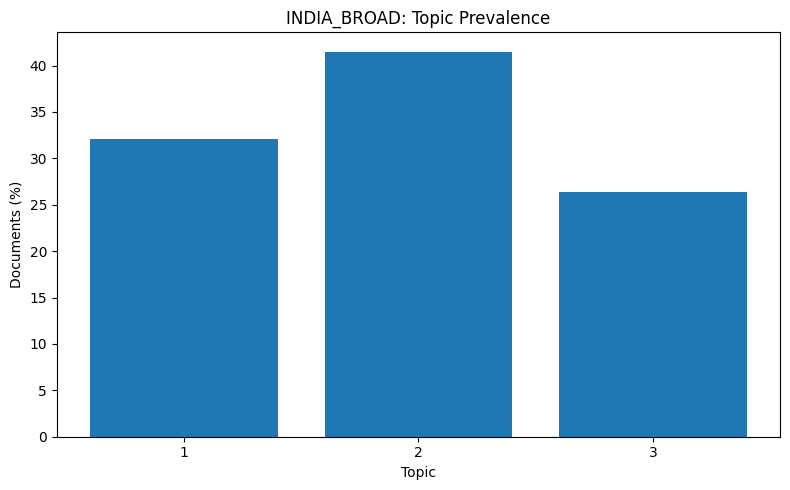


 INDIA_BROAD
Selected K: 3
Best coherence: 0.3321
Documents modelled: 53
Vocabulary: 1036

INDIA_STRICT_MSME: Only 6 documents. LDA not run because the corpus is too small for a defensible model.

INDIA CLEANING AND LDA WORKFLOW COMPLETED
Original records: 78
Excluded records: 24
Broad corpus: 53
Strict business/MSME corpus: 6
Pending manual review: 19

Output ZIP: /content/India_Cleaned_Corpora_and_LDA_Results.zip



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ================================================================
# INDIA CROWDSOURCING CORPUS
# CLEANING + CLASSIFICATION + DEDUPLICATION + LDA
# Reproducible research workflow | Random seed = 42
# ================================================================

!pip -q install pandas numpy gensim matplotlib openpyxl

import os
import re
import zipfile
import shutil
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel
from gensim.parsing.preprocessing import STOPWORDS

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

BASE = "/content/India_Cleaning"
os.makedirs(BASE, exist_ok=True)

# ------------------------------------------------
# STEP 1. LOCATE AND EXTRACT THE ORIGINAL INDIA DATA
# ------------------------------------------------

possible_zips = [
    "/content/Crowdsourcing_Filtered_Corpora.zip",
    "/content/Crowdsourcing_Final_Corpus.zip",
    "/content/reports.zip"
]

zip_path = next((p for p in possible_zips if os.path.exists(p)), None)

if zip_path is None:
    print("Upload the ZIP containing India_Filtered_Records.csv")
    uploaded = files.upload()
    zip_path = "/content/" + list(uploaded.keys())[0]

extract_dir = BASE + "/input"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

csv_files = []
for root, dirs, filenames in os.walk(extract_dir):
    for filename in filenames:
        if filename.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, filename))

# Prefer the original filtered India records file.
preferred = [
    p for p in csv_files
    if os.path.basename(p).lower() == "india_filtered_records.csv"
]

if not preferred:
    preferred = [
        p for p in csv_files
        if "india" in os.path.basename(p).lower()
        and "audit" not in os.path.basename(p).lower()
        and "review" not in os.path.basename(p).lower()
    ]

if not preferred:
    raise FileNotFoundError(
        "Could not find India_Filtered_Records.csv. "
        "Please upload the ZIP containing the filtered India records."
    )

input_csv = preferred[0]
df = pd.read_csv(input_csv, encoding="utf-8-sig")

print("Input file:", input_csv)
print("Input records:", len(df))
print("Available columns:", list(df.columns))


# ------------------------------------------------
# STEP 2. STANDARDISE COLUMN NAMES
# ------------------------------------------------

def find_column(columns, candidates):
    lookup = {str(c).strip().lower(): c for c in columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

title_col = find_column(
    df.columns,
    ["Title", "title", "Document_Title", "document_title"]
)

abstract_col = find_column(
    df.columns,
    ["Abstract", "abstract", "Description", "description",
     "Summary", "summary"]
)

doi_col = find_column(
    df.columns,
    ["DOI", "doi", "Document_DOI", "document_doi"]
)

year_col = find_column(
    df.columns,
    ["Year", "year", "Publication_Year", "publication_year"]
)

source_col = find_column(
    df.columns,
    ["Source", "source", "Publisher", "publisher"]
)

if title_col is None:
    raise ValueError("No title column found in the India CSV.")

if abstract_col is None:
    raise ValueError(
        "No abstract/description column found. "
        "Use the original India_Filtered_Records.csv."
    )

work = pd.DataFrame()

work["Title"] = df[title_col].fillna("").astype(str).str.strip()
work["Abstract"] = df[abstract_col].fillna("").astype(str).str.strip()

work["DOI"] = (
    df[doi_col].fillna("").astype(str).str.strip()
    if doi_col else ""
)

work["Year"] = (
    df[year_col] if year_col else ""
)

work["Source"] = (
    df[source_col].fillna("").astype(str).str.strip()
    if source_col else ""
)

# Preserve original metadata.
for col in df.columns:
    if col not in [title_col, abstract_col, doi_col, year_col, source_col]:
        work[col] = df[col]

work["Original_Row"] = np.arange(1, len(work) + 1)
work["Title_Normalised"] = (
    work["Title"].str.lower()
    .str.replace(r"[^a-z0-9]+", " ", regex=True)
    .str.strip()
)

work["Abstract_Normalised"] = (
    work["Abstract"].str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

work["Combined_Text"] = (
    work["Title"] + " " + work["Abstract"]
).str.strip()

work["Decision"] = "RETAIN_BROAD_PENDING"
work["Category"] = "UNREVIEWED"
work["Decision_Reason"] = (
    "Not covered by an explicit rule in the supplied manual validation; "
    "preserved in broad corpus pending review."
)


# ------------------------------------------------
# STEP 3. EXCLUDE CLEAR FALSE POSITIVES
# ------------------------------------------------

def mark_exclude(mask, reason, category="EXCLUDE"):
    mask = mask & (work["Decision"] != "EXCLUDE")
    work.loc[mask, "Decision"] = "EXCLUDE"
    work.loc[mask, "Category"] = category
    work.loc[mask, "Decision_Reason"] = reason


# 3A. Indian Roads Congress legal/technical standards.
irc_pattern = (
    r"indian roads congress|"
    r"\birc[\s\-]*(?:sp[\s\-]*)?\d{2,3}\b|"
    r"legally binding document|"
    r"roads congress|"
    r"better translations"
)

irc_mask = (
    work["Title"].str.lower().str.contains(irc_pattern, regex=True, na=False)
    |
    work["Abstract"].str.lower().str.contains(
        r"legally binding document|"
        r"indian roads congress|"
        r"crowdsourcing better translations",
        regex=True, na=False
    )
)

mark_exclude(
    irc_mask,
    "False positive: Indian Roads Congress standard or repeated legal-document translation boilerplate."
)


# 3B. Crowdfunding-only literature.
crowdfunding_mask = (
    work["Title"].str.lower().str.contains(
        r"crowd[\s\-]*funding|crowdfunding",
        regex=True, na=False
    )
)

mark_exclude(
    crowdfunding_mask,
    "Crowdfunding-only record; outside the core crowdsourcing research scope."
)


# 3C. Incidental or weak mention of crowdsourcing.
weak_title_patterns = [
    r"research and innovation in teaching pedagogy",
    r"theoretical integration of gig economy",
    r"data science landscape",
    r"impact of covid.?19 on the indian economy",
]

weak_mask = work["Title"].str.lower().str.contains(
    "|".join(weak_title_patterns), regex=True, na=False
)

mark_exclude(
    weak_mask,
    "Crowdsourcing is incidental, ambiguous or only mentioned in a broader work."
)


# 3D. Bibliometric/historical works that are not India-specific.
not_india_patterns = [
    r"open innovation and crowdsourcing research.*bibliometric",
    r"^crowdsourcing$",
]

not_india_mask = work["Title"].str.lower().str.contains(
    "|".join(not_india_patterns), regex=True, na=False
)

mark_exclude(
    not_india_mask,
    "Not an India-specific empirical or thematic crowdsourcing study."
)


# ------------------------------------------------
# STEP 4. REMOVE DUPLICATES
# ------------------------------------------------

# DOI normalisation.
work["DOI_Normalised"] = (
    work["DOI"].str.lower()
    .str.replace(r"^https?://(dx\.)?doi\.org/", "", regex=True)
    .str.replace(r"^doi:\s*", "", regex=True)
    .str.strip()
)

# Remove duplicate DOI records among non-excluded records.
doi_mask = (
    work["DOI_Normalised"].ne("")
    & work["Decision"].ne("EXCLUDE")
)

doi_duplicates = work.loc[doi_mask].duplicated(
    subset=["DOI_Normalised"], keep="first"
)

duplicate_indices = work.loc[doi_mask].index[doi_duplicates]

work.loc[duplicate_indices, "Decision"] = "EXCLUDE"
work.loc[duplicate_indices, "Category"] = "DUPLICATE"
work.loc[duplicate_indices, "Decision_Reason"] = (
    "Duplicate DOI; first occurrence retained."
)

# Title-based duplicate removal.
active = work["Decision"].ne("EXCLUDE")

title_duplicates = work.loc[active].duplicated(
    subset=["Title_Normalised"], keep="first"
)

duplicate_indices = work.loc[active].index[title_duplicates]

work.loc[duplicate_indices, "Decision"] = "EXCLUDE"
work.loc[duplicate_indices, "Category"] = "DUPLICATE"
work.loc[duplicate_indices, "Decision_Reason"] = (
    "Duplicate normalised title; first occurrence retained."
)


# ------------------------------------------------
# STEP 5. CLASSIFY THE RETAINED INDIA RECORDS
# ------------------------------------------------

# Direct SME/MSME research.
direct_msme_patterns = [
    r"\bmsme\b",
    r"\bmsmes\b",
    r"\bsme\b",
    r"\bsmes\b",
    r"small and medium enterprises",
    r"small and medium enterprise",
    r"small business",
    r"small businesses",
]

direct_msme_mask = work["Combined_Text"].str.lower().str.contains(
    "|".join(direct_msme_patterns), regex=True, na=False
)

# Specific manually validated direct SME records.
direct_title_patterns = [
    r"enhancing product design quality through crowdsourcing manufacturing platforms",
    r"does crowdsourcing services moderate effect on supply risk management performance",
    r"exploring crowdsourcing practices and benefits.*small and medium enterprises",
    r"profiling crowdsourcing practices trend among smes",
    r"revisiting smes.*business strategy",
    r"crowdsourcing and small business challenges",
]

direct_title_mask = work["Title"].str.lower().str.contains(
    "|".join(direct_title_patterns), regex=True, na=False
)

direct_mask = (
    (direct_msme_mask | direct_title_mask)
    & work["Decision"].ne("EXCLUDE")
)

work.loc[direct_mask, "Decision"] = "RETAIN_CORE"
work.loc[direct_mask, "Category"] = "DIRECT_SME_MSME"
work.loc[direct_mask, "Decision_Reason"] = (
    "Direct SME/MSME relevance identified from title or abstract."
)


# Broader business and commercial innovation studies.
business_patterns = [
    r"developments and leanings of crowdsourcing industry",
    r"transforming jewellery designing",
    r"talenthouse india",
    r"crowdsourcing students for open innovation",
    r"crowdsourcing.*business model",
    r"crowdsourcing.*business innovation",
    r"crowdsourcing.*product development",
    r"crowdsourcing.*manufacturing",
    r"crowdsourcing.*entrepreneur",
    r"crowdsourcing.*business strategy",
    r"open innovation.*smes",
]

business_mask = work["Title"].str.lower().str.contains(
    "|".join(business_patterns), regex=True, na=False
)

business_mask = (
    business_mask
    & work["Decision"].ne("EXCLUDE")
    & work["Decision"].ne("RETAIN_CORE")
)

work.loc[business_mask, "Decision"] = "RETAIN_CORE"
work.loc[business_mask, "Category"] = "BUSINESS_INNOVATION"
work.loc[business_mask, "Decision_Reason"] = (
    "Business, commercial innovation, product development or crowdsourcing business-model relevance."
)


# Agricultural and smallholder applications.
agri_patterns = [
    r"citizen science and remote sensing for crop yield gap analysis",
    r"farmer",
    r"agricultur",
    r"crop yield",
    r"smallholder",
]

agri_mask = work["Combined_Text"].str.lower().str.contains(
    "|".join(agri_patterns), regex=True, na=False
)

agri_mask = (
    agri_mask
    & work["Decision"].ne("EXCLUDE")
    & work["Decision"].ne("RETAIN_CORE")
)

work.loc[agri_mask, "Decision"] = "RETAIN_BROAD"
work.loc[agri_mask, "Category"] = "AGRICULTURE"
work.loc[agri_mask, "Decision_Reason"] = (
    "Agricultural or smallholder crowdsourcing application; retained in broad corpus."
)


# Other genuine domain-adjacent crowdsourcing.
adjacent_patterns = [
    r"mechanical turk",
    r"crowdworker",
    r"crowd worker",
    r"crowdshipping",
    r"crowd shipping",
    r"citizen science",
    r"crowdsourcing.*health",
    r"maternal.*newborn.*child health",
    r"minor languages",
    r"heritage conservation",
    r"cultural heritage",
    r"digital libraries",
    r"e-governance",
    r"earthquake early warning",
    r"traffic scenarios",
    r"adas development",
    r"smsassassin",
    r"glam digital repositories",
    r"crowdsourcing.*public",
    r"crowdsourcing.*policy",
    r"online platforms and new forms of employment",
    r"crowdsourcing quality",
    r"crowdsourcing.*research priorities",
    r"generation.?z willingness.*crowdshipping",
    r"low income community as crowd worker",
    r"privacy attitudes of mechanical turk workers",
]

adjacent_mask = work["Combined_Text"].str.lower().str.contains(
    "|".join(adjacent_patterns), regex=True, na=False
)

adjacent_mask = (
    adjacent_mask
    & work["Decision"].ne("EXCLUDE")
    & work["Decision"].ne("RETAIN_CORE")
    & work["Decision"].ne("RETAIN_BROAD")
)

work.loc[adjacent_mask, "Decision"] = "RETAIN_BROAD"
work.loc[adjacent_mask, "Category"] = "DOMAIN_ADJACENT"
work.loc[adjacent_mask, "Decision_Reason"] = (
    "Genuine crowdsourcing application, but not direct MSME/business evidence."
)


# ------------------------------------------------
# STEP 6. FLAG INDIA GEOGRAPHICAL RELEVANCE
# ------------------------------------------------

def india_geography(row):
    text = (str(row["Title"]) + " " + str(row["Abstract"])).lower()

    if re.search(r"\bindia\b|\bindian\b|\bmaharashtra\b|\bgujarat\b", text):
        return "INDIA_REFERENCED_REVIEW"

    return "INDIA_CORPUS_ORIGIN_REVIEW"

work["India_Relevance"] = work.apply(india_geography, axis=1)


# ------------------------------------------------
# STEP 7. CREATE TWO CLEAN CORPORA
# ------------------------------------------------

broad = work[
    work["Decision"].isin([
        "RETAIN_CORE",
        "RETAIN_BROAD",
        "RETAIN_BROAD_PENDING"
    ])
].copy()

core = work[
    work["Decision"].eq("RETAIN_CORE")
].copy()

# Do not allow records without abstracts into LDA.
broad["Abstract_Available"] = broad["Abstract"].str.strip().ne("")
core["Abstract_Available"] = core["Abstract"].str.strip().ne("")

broad_model = broad[broad["Abstract_Available"]].copy()
core_model = core[core["Abstract_Available"]].copy()

# Stable document identifiers.
broad_model["Document_ID"] = [
    "IND_BROAD_" + str(i).zfill(4)
    for i in range(1, len(broad_model) + 1)
]

core_model["Document_ID"] = [
    "IND_CORE_" + str(i).zfill(4)
    for i in range(1, len(core_model) + 1)
]


# ------------------------------------------------
# STEP 8. SAVE CLEANED CSV AND TXT FILES
# ------------------------------------------------

def save_corpus(data, prefix):
    csv_path = f"{BASE}/{prefix}_Cleaned.csv"
    txt_path = f"{BASE}/{prefix}_Cleaned.txt"

    data.to_csv(csv_path, index=False, encoding="utf-8-sig")

    with open(txt_path, "w", encoding="utf-8") as f:
        for _, row in data.iterrows():
            f.write("=" * 90 + "\n")
            f.write("DOCUMENT_ID: " + str(row.get("Document_ID", "")) + "\n")
            f.write("TITLE: " + str(row["Title"]) + "\n")
            f.write("YEAR: " + str(row["Year"]) + "\n")
            f.write("SOURCE: " + str(row["Source"]) + "\n")
            f.write("DOI: " + str(row["DOI"]) + "\n")
            f.write("CATEGORY: " + str(row["Category"]) + "\n")
            f.write("-" * 90 + "\n")
            f.write(str(row["Abstract"]) + "\n\n")

    return csv_path, txt_path

save_corpus(broad_model, "India_Broad_Crowdsourcing")
save_corpus(core_model, "India_Strict_Business_MSME")


# ------------------------------------------------
# STEP 9. CREATE COMPLETE CLEANING AUDIT
# ------------------------------------------------

audit_path = f"{BASE}/India_Cleaning_Audit.csv"
excluded_path = f"{BASE}/India_Excluded_Records.csv"
pending_path = f"{BASE}/India_Pending_Manual_Review.csv"

work.to_csv(audit_path, index=False, encoding="utf-8-sig")

work[work["Decision"].eq("EXCLUDE")].to_csv(
    excluded_path, index=False, encoding="utf-8-sig"
)

work[work["Decision"].eq("RETAIN_BROAD_PENDING")].to_csv(
    pending_path, index=False, encoding="utf-8-sig"
)

summary = (
    work.groupby(["Decision", "Category"], dropna=False)
    .size()
    .reset_index(name="Records")
)

summary.to_csv(
    f"{BASE}/India_Cleaning_Summary.csv",
    index=False, encoding="utf-8-sig"
)


# ------------------------------------------------
# STEP 10. PREPARE LDA TEXT
# ------------------------------------------------

CUSTOM_STOPWORDS = set(STOPWORDS).union({
    "india", "indian", "study", "studies", "paper", "article",
    "research", "results", "analysis", "using", "used", "based",
    "approach", "method", "methods", "findings", "objective",
    "purpose", "aim", "chapter", "review", "conclusion",
    "crowdsourcing", "crowdsource", "crowdsourced", "crowd",
    "crowd sourcing"
})

def preprocess(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"crowd[\s\-]+sourcing", "crowdsourcing", text)
    tokens = re.findall(r"[a-z][a-z0-9]{2,}", text)

    return [
        token for token in tokens
        if token not in CUSTOM_STOPWORDS
    ]

# Use title + abstract.
broad_model["Model_Text"] = (
    broad_model["Title"].fillna("") + " " +
    broad_model["Abstract"].fillna("")
)

core_model["Model_Text"] = (
    core_model["Title"].fillna("") + " " +
    core_model["Abstract"].fillna("")
)

broad_tokens = [
    preprocess(x) for x in broad_model["Model_Text"]
]

core_tokens = [
    preprocess(x) for x in core_model["Model_Text"]
]


# ------------------------------------------------
# STEP 11. FIT AND EVALUATE LDA
# ------------------------------------------------

def run_lda(tokens, data, corpus_name, min_docs=20):

    if len(tokens) < min_docs:
        print(
            f"\n{corpus_name}: Only {len(tokens)} documents. "
            "LDA not run because the corpus is too small for a defensible model."
        )
        return None

    # Remove empty documents.
    valid = [(t, i) for i, t in enumerate(tokens) if len(t) >= 5]

    if len(valid) < min_docs:
        print(
            f"{corpus_name}: Too few documents with sufficient tokens. "
            "LDA not run."
        )
        return None

    tokens_valid = [x[0] for x in valid]
    indices = [x[1] for x in valid]
    data_valid = data.iloc[indices].copy()

    dictionary = corpora.Dictionary(tokens_valid)

    no_below = 2 if len(tokens_valid) < 150 else 3
    no_above = 0.85 if len(tokens_valid) < 150 else 0.75

    dictionary.filter_extremes(
        no_below=no_below,
        no_above=no_above,
        keep_n=5000
    )

    if len(dictionary) < 15:
        dictionary = corpora.Dictionary(tokens_valid)
        dictionary.filter_extremes(
            no_below=1,
            no_above=0.95,
            keep_n=5000
        )

    bow = [dictionary.doc2bow(t) for t in tokens_valid]

    if len(dictionary) < 10:
        print(corpus_name, ": vocabulary too small; LDA skipped.")
        return None

    # Candidate K values are limited for a small Indian corpus.
    if len(tokens_valid) < 40:
        k_values = [2, 3]
    elif len(tokens_valid) < 80:
        k_values = [2, 3, 4]
    elif len(tokens_valid) < 150:
        k_values = [2, 3, 4, 5]
    else:
        k_values = [3, 4, 5, 6, 7]

    model_rows = []
    models = {}

    for k in k_values:
        if k >= len(tokens_valid):
            continue

        model = LdaModel(
            corpus=bow,
            id2word=dictionary,
            num_topics=k,
            random_state=SEED,
            chunksize=100,
            passes=20,
            iterations=300,
            alpha="symmetric",
            eta="auto",
            minimum_probability=0.0,
            eval_every=None
        )

        coherence = CoherenceModel(
            model=model,
            texts=tokens_valid,
            dictionary=dictionary,
            coherence="c_v"
        ).get_coherence()

        model_rows.append({
            "Corpus": corpus_name,
            "K": k,
            "Coherence_CV": coherence,
            "Documents": len(tokens_valid),
            "Vocabulary_Size": len(dictionary)
        })

        models[k] = model

    if not model_rows:
        return None

    selection = pd.DataFrame(model_rows).sort_values(
        ["Coherence_CV", "K"],
        ascending=[False, True]
    )

    best_k = int(selection.iloc[0]["K"])
    best_model = models[best_k]

    # Save candidate model evaluation.
    selection.to_csv(
        f"{BASE}/{corpus_name}_LDA_Model_Selection.csv",
        index=False, encoding="utf-8-sig"
    )

    # Topic keywords.
    topic_rows = []

    for topic_id in range(best_k):
        for rank, (word, probability) in enumerate(
            best_model.show_topic(topic_id, topn=15), start=1
        ):
            topic_rows.append({
                "Corpus": corpus_name,
                "Topic": topic_id + 1,
                "Rank": rank,
                "Keyword": word,
                "Probability": probability
            })

    topic_df = pd.DataFrame(topic_rows)
    topic_df.to_csv(
        f"{BASE}/{corpus_name}_Topic_Keywords.csv",
        index=False, encoding="utf-8-sig"
    )

    # Document-topic probabilities.
    assignment_rows = []

    for doc_index, bow_doc in enumerate(bow):
        probabilities = best_model.get_document_topics(
            bow_doc, minimum_probability=0
        )

        probs = {topic: prob for topic, prob in probabilities}
        dominant = max(probs, key=probs.get)

        row = {
            "Document_ID": data_valid.iloc[doc_index]["Document_ID"],
            "Title": data_valid.iloc[doc_index]["Title"],
            "Year": data_valid.iloc[doc_index]["Year"],
            "Category": data_valid.iloc[doc_index]["Category"],
            "Dominant_Topic": dominant + 1,
            "Dominant_Topic_Probability": probs[dominant],
            "Token_Count": len(tokens_valid[doc_index])
        }

        for topic in range(best_k):
            row[f"Topic_{topic + 1}_Probability"] = probs[topic]

        assignment_rows.append(row)

    assignments = pd.DataFrame(assignment_rows)

    assignments.to_csv(
        f"{BASE}/{corpus_name}_Document_Topic_Assignments.csv",
        index=False, encoding="utf-8-sig"
    )

    # Topic prevalence.
    prevalence = (
        assignments.groupby("Dominant_Topic")
        .agg(
            Documents=("Document_ID", "count"),
            Mean_Topic_Probability=(
                "Dominant_Topic_Probability", "mean"
            )
        )
        .reset_index()
    )

    prevalence["Document_Percentage"] = (
        prevalence["Documents"] / len(assignments) * 100
    )

    prevalence.to_csv(
        f"{BASE}/{corpus_name}_Topic_Prevalence.csv",
        index=False, encoding="utf-8-sig"
    )

    # Save model and dictionary.
    best_model.save(f"{BASE}/{corpus_name}_Best_LDA_Model")
    dictionary.save(f"{BASE}/{corpus_name}_Dictionary")

    # Plot topic prevalence.
    plt.figure(figsize=(8, 5))
    plt.bar(
        prevalence["Dominant_Topic"].astype(str),
        prevalence["Document_Percentage"]
    )
    plt.xlabel("Topic")
    plt.ylabel("Documents (%)")
    plt.title(f"{corpus_name}: Topic Prevalence")
    plt.tight_layout()
    plt.savefig(
        f"{BASE}/{corpus_name}_Topic_Prevalence.png",
        dpi=300
    )
    plt.show()

    print("\n", corpus_name)
    print("Selected K:", best_k)
    print("Best coherence:", round(selection.iloc[0]["Coherence_CV"], 4))
    print("Documents modelled:", len(tokens_valid))
    print("Vocabulary:", len(dictionary))

    return {
        "selection": selection,
        "topics": topic_df,
        "assignments": assignments,
        "prevalence": prevalence,
        "best_k": best_k,
        "coherence": float(selection.iloc[0]["Coherence_CV"]),
        "documents": len(tokens_valid),
        "vocabulary": len(dictionary)
    }


# ------------------------------------------------
# STEP 12. RUN LDA SEPARATELY
# ------------------------------------------------

broad_results = run_lda(
    broad_tokens,
    broad_model,
    "INDIA_BROAD",
    min_docs=20
)

core_results = run_lda(
    core_tokens,
    core_model,
    "INDIA_STRICT_MSME",
    min_docs=20
)


# ------------------------------------------------
# STEP 13. CREATE EXCEL WORKBOOK
# ------------------------------------------------

excel_path = f"{BASE}/India_Cleaning_and_LDA_Results.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

    summary.to_excel(
        writer, sheet_name="Cleaning_Summary", index=False
    )

    work.to_excel(
        writer, sheet_name="Full_Audit", index=False
    )

    broad_model.to_excel(
        writer, sheet_name="Broad_Corpus", index=False
    )

    core_model.to_excel(
        writer, sheet_name="Strict_MSME_Corpus", index=False
    )

    if broad_results:
        broad_results["selection"].to_excel(
            writer, sheet_name="Broad_Model_Selection", index=False
        )
        broad_results["topics"].to_excel(
            writer, sheet_name="Broad_Topics", index=False
        )
        broad_results["assignments"].to_excel(
            writer, sheet_name="Broad_Assignments", index=False
        )
        broad_results["prevalence"].to_excel(
            writer, sheet_name="Broad_Prevalence", index=False
        )

    if core_results:
        core_results["selection"].to_excel(
            writer, sheet_name="MSME_Model_Selection", index=False
        )
        core_results["topics"].to_excel(
            writer, sheet_name="MSME_Topics", index=False
        )
        core_results["assignments"].to_excel(
            writer, sheet_name="MSME_Assignments", index=False
        )
        core_results["prevalence"].to_excel(
            writer, sheet_name="MSME_Prevalence", index=False
        )


# ------------------------------------------------
# STEP 14. SAVE CONFIGURATION AND RESULTS SUMMARY
# ------------------------------------------------

configuration = {
    "random_seed": SEED,
    "input_zip": os.path.basename(zip_path),
    "input_records": int(len(work)),
    "broad_corpus_records": int(len(broad_model)),
    "strict_msme_records": int(len(core_model)),
    "excluded_records": int((work["Decision"] == "EXCLUDE").sum()),
    "pending_manual_review": int(
        (work["Decision"] == "RETAIN_BROAD_PENDING").sum()
    ),
    "broad_lda": (
        {
            "selected_k": broad_results["best_k"],
            "coherence_cv": broad_results["coherence"],
            "documents_modelled": broad_results["documents"],
            "vocabulary_size": broad_results["vocabulary"]
        } if broad_results else "Not run"
    ),
    "strict_msme_lda": (
        {
            "selected_k": core_results["best_k"],
            "coherence_cv": core_results["coherence"],
            "documents_modelled": core_results["documents"],
            "vocabulary_size": core_results["vocabulary"]
        } if core_results else "Not run"
    )
}

with open(
    f"{BASE}/India_Research_Configuration.json",
    "w", encoding="utf-8"
) as f:
    json.dump(configuration, f, indent=4)


# ------------------------------------------------
# STEP 15. ZIP ALL OUTPUTS
# ------------------------------------------------

output_zip = "/content/India_Cleaned_Corpora_and_LDA_Results.zip"

if os.path.exists(output_zip):
    os.remove(output_zip)

shutil.make_archive(
    output_zip.replace(".zip", ""),
    "zip",
    BASE
)

print("\n" + "=" * 70)
print("INDIA CLEANING AND LDA WORKFLOW COMPLETED")
print("=" * 70)

print("Original records:", len(work))
print("Excluded records:", (work["Decision"] == "EXCLUDE").sum())
print("Broad corpus:", len(broad_model))
print("Strict business/MSME corpus:", len(core_model))
print(
    "Pending manual review:",
    (work["Decision"] == "RETAIN_BROAD_PENDING").sum()
)

print("\nOutput ZIP:", output_zip)
print("\nDownloading ZIP...")
files.download(output_zip)

In [ ]:
# Only manually/rule-classified relevant records enter the analytical corpus.
# Unreviewed records remain in the audit file, not in LDA.

broad = work[
    work["Decision"].isin(["RETAIN_CORE", "RETAIN_BROAD"])
].copy()

core = work[
    work["Decision"].eq("RETAIN_CORE")
].copy()

In [ ]:
import os
import pandas as pd
import glob

BASE = "/content/India_Cleaning"

files_to_show = [
    "India_Cleaning_Summary.csv",
    "INDIA_BROAD_LDA_Model_Selection.csv",
    "INDIA_BROAD_Topic_Keywords.csv",
    "INDIA_BROAD_Topic_Prevalence.csv",
    "INDIA_STRICT_MSME_LDA_Model_Selection.csv",
    "INDIA_STRICT_MSME_Topic_Keywords.csv",
    "INDIA_STRICT_MSME_Topic_Prevalence.csv"
]

for filename in files_to_show:
    path = os.path.join(BASE, filename)
    print("\n" + "=" * 80)
    print(filename)
    print("=" * 80)

    if os.path.exists(path):
        display(pd.read_csv(path))
    else:
        print("Not generated – check whether LDA ran for this corpus.")


India_Cleaning_Summary.csv


,Decision,Category,Records
0,EXCLUDE,EXCLUDE,24
1,RETAIN_BROAD,AGRICULTURE,2
2,RETAIN_BROAD,DOMAIN_ADJACENT,27
3,RETAIN_BROAD_PENDING,UNREVIEWED,19
4,RETAIN_CORE,BUSINESS_INNOVATION,3
5,RETAIN_CORE,DIRECT_SME_MSME,3



INDIA_BROAD_LDA_Model_Selection.csv


,Corpus,K,Coherence_CV,Documents,Vocabulary_Size
0,INDIA_BROAD,3,0.332101,53,1036
1,INDIA_BROAD,2,0.318986,53,1036
2,INDIA_BROAD,4,0.310766,53,1036



INDIA_BROAD_Topic_Keywords.csv


,Corpus,Topic,Rank,Keyword,Probability
0,INDIA_BROAD,1,1,heritage,0.013311
1,INDIA_BROAD,1,2,data,0.013076
2,INDIA_BROAD,1,3,waste,0.008664
3,INDIA_BROAD,1,4,social,0.008315
4,INDIA_BROAD,1,5,value,0.008176
5,INDIA_BROAD,1,6,emerging,0.008120
6,INDIA_BROAD,1,7,use,0.007804
7,INDIA_BROAD,1,8,learning,0.007217
8,INDIA_BROAD,1,9,health,0.006977
9,INDIA_BROAD,1,10,media,0.006860



INDIA_BROAD_Topic_Prevalence.csv


,Dominant_Topic,Documents,Mean_Topic_Probability,Document_Percentage
0,1,17,0.985142,32.075472
1,2,22,0.917413,41.509434
2,3,14,0.904179,26.415094



INDIA_STRICT_MSME_LDA_Model_Selection.csv
Not generated – check whether LDA ran for this corpus.

INDIA_STRICT_MSME_Topic_Keywords.csv
Not generated – check whether LDA ran for this corpus.

INDIA_STRICT_MSME_Topic_Prevalence.csv
Not generated – check whether LDA ran for this corpus.


In [ ]:
import os
import pandas as pd

BASE = "/content/India_Cleaning"

for filename in [
    "India_Cleaning_Summary.csv",
    "INDIA_BROAD_LDA_Model_Selection.csv",
    "INDIA_BROAD_Topic_Keywords.csv",
    "India_Strict_Business_MSME_Cleaned.csv"
]:
    path = os.path.join(BASE, filename)

    print("\n" + "="*70)
    print(filename)
    print("="*70)

    if os.path.exists(path):
        d = pd.read_csv(path)
        print("Rows:", len(d))
        display(d)
    else:
        print("File not found")


India_Cleaning_Summary.csv
Rows: 6


,Decision,Category,Records
0,EXCLUDE,EXCLUDE,24
1,RETAIN_BROAD,AGRICULTURE,2
2,RETAIN_BROAD,DOMAIN_ADJACENT,27
3,RETAIN_BROAD_PENDING,UNREVIEWED,19
4,RETAIN_CORE,BUSINESS_INNOVATION,3
5,RETAIN_CORE,DIRECT_SME_MSME,3



INDIA_BROAD_LDA_Model_Selection.csv
Rows: 3


,Corpus,K,Coherence_CV,Documents,Vocabulary_Size
0,INDIA_BROAD,3,0.332101,53,1036
1,INDIA_BROAD,2,0.318986,53,1036
2,INDIA_BROAD,4,0.310766,53,1036



INDIA_BROAD_Topic_Keywords.csv
Rows: 45


,Corpus,Topic,Rank,Keyword,Probability
0,INDIA_BROAD,1,1,heritage,0.013311
1,INDIA_BROAD,1,2,data,0.013076
2,INDIA_BROAD,1,3,waste,0.008664
3,INDIA_BROAD,1,4,social,0.008315
4,INDIA_BROAD,1,5,value,0.008176
5,INDIA_BROAD,1,6,emerging,0.008120
6,INDIA_BROAD,1,7,use,0.007804
7,INDIA_BROAD,1,8,learning,0.007217
8,INDIA_BROAD,1,9,health,0.006977
9,INDIA_BROAD,1,10,media,0.006860



India_Strict_Business_MSME_Cleaned.csv
Rows: 6


,Title,Abstract,DOI,Year,Source,original_record_number,author,publisher,document_type,url,full_text_status,decision,decision_reason,Original_Row,Title_Normalised,Abstract_Normalised,Combined_Text,Decision,Category,Decision_Reason,DOI_Normalised,India_Relevance,Abstract_Available,Document_ID
0,Does crowdsourcing services moderate effect on supply risk management performance in COVID-19 pandemic: evidence from India,"As the COVID-19 pandemic continues to spread, supply chains face challenges requiring significant social distancing measures to ensure that critical goods continue to be shipped to local shops and doorsteps of consumers. In this study, an attempt is being made to understand crowdsourcing’s scope...",https://doi.org/10.1080/16258312.2022.2090274,2022,OpenAlex,5,Chandra Kant Upadhyay; Vijayshri Tewari; Vineet Tiwari,Supply Chain Forum an International Journal,article,https://doi.org/10.1080/16258312.2022.2090274,Not yet checked,KEEP,Crowdsourcing and subject relevance established,2,does crowdsourcing services moderate effect on supply risk management performance in covid 19 pandemic evidence from india,"as the covid-19 pandemic continues to spread, supply chains face challenges requiring significant social distancing measures to ensure that critical goods continue to be shipped to local shops and doorsteps of consumers. in this study, an attempt is being made to understand crowdsourcing’s scope...","Does crowdsourcing services moderate effect on supply risk management performance in COVID-19 pandemic: evidence from India As the COVID-19 pandemic continues to spread, supply chains face challenges requiring significant social distancing measures to ensure that critical goods continue to be sh...",RETAIN_CORE,DIRECT_SME_MSME,Direct SME/MSME relevance identified from title or abstract.,10.1080/16258312.2022.2090274,INDIA_REFERENCED_REVIEW,True,IND_CORE_0001
1,Developments and leanings of crowdsourcing industry: implications of China and India,"Purpose – Since crowdsourcing can be taken as a new field, the purpose of this paper is to suggest an idea/movement to motivate pro or anti-ideas/movements from scholars and experts to develop a synthesis in future. Design/methodology/approach – The paper provides a quantitative analysis of worl...",https://doi.org/10.1108/ict-06-2013-0038,2014,OpenAlex,108,Indika Perera; Pramuk Perera,Industrial and Commercial Training,article,https://doi.org/10.1108/ict-06-2013-0038,Not yet checked,KEEP,Crowdsourcing and subject relevance established,30,developments and leanings of crowdsourcing industry implications of china and india,"purpose – since crowdsourcing can be taken as a new field, the purpose of this paper is to suggest an idea/movement to motivate pro or anti-ideas/movements from scholars and experts to develop a synthesis in future. design/methodology/approach – the paper provides a quantitative analysis of worl...","Developments and leanings of crowdsourcing industry: implications of China and India Purpose – Since crowdsourcing can be taken as a new field, the purpose of this paper is to suggest an idea/movement to motivate pro or anti-ideas/movements from scholars and experts to develop a synthesis in fut...",RETAIN_CORE,BUSINESS_INNOVATION,"Business, commercial innovation, product development or crowdsourcing business-model relevance.",10.1108/ict-06-2013-0038,INDIA_REFERENCED_REVIEW,True,IND_CORE_0002
2,Transforming Jewellery Designing: Empowering Customers through Crowdsourcing in India,"Dynamic business environment demands ‘value’ to be co-created with larger group of stakeholders and especially with customers as partners for development and growth. With this goal in mind, MNCs are engaging in value creation with the customers by largely seeking customer engagement in designing...",https://doi.org/10.1177/0972150917710123,2017,OpenAlex,109,Bijoylaxmi Sarmah; Zillur Rahman,Global Business Review,article,https://doi.org/10.1177/0972150917710123,Not yet checked,KEEP,Crowdsourci

In [ ]:
import pandas as pd
import os

BASE = "/content/India_Cleaning"

audit_path = os.path.join(BASE, "India_Cleaning_Audit.csv")
assignment_path = os.path.join(
    BASE, "INDIA_BROAD_Document_Topic_Assignments.csv"
)

audit = pd.read_csv(audit_path)

# 1. Correct Upwork classification
mask = audit["Title"].str.contains(
    "Freelancing globally: Upworkers",
    case=False, na=False
)

audit.loc[mask, "Decision"] = "RETAIN_BROAD"
audit.loc[mask, "Category"] = "DOMAIN_ADJACENT"
audit.loc[mask, "Decision_Reason"] = (
    "Digital labour and platform-worker study; "
    "not direct SME/MSME adoption evidence."
)

# 2. Flag manufacturing study for source verification
mask = audit["Title"].str.contains(
    "Enhancing Product Design Quality",
    case=False, na=False
)

audit.loc[mask, "Source_Verification_Status"] = (
    "REQUIRES_INDEPENDENT_VERIFICATION"
)

audit.loc[mask, "Source_Verification_Note"] = (
    "DOI field contains a URL; verify journal identity, "
    "publisher, article metadata and publication record."
)

# 3. Rebuild strict corpus
strict = audit[
    audit["Decision"] == "RETAIN_CORE"
].copy()

strict.to_csv(
    os.path.join(BASE, "India_Strict_MSME_Corrected.csv"),
    index=False,
    encoding="utf-8-sig"
)

audit.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig"
)

print("CORRECTED STRICT CORPUS:", len(strict))

display(
    strict[[
        "Title", "Year", "Category",
        "Decision_Reason"
    ]]
)

print("\nCORRECTED CATEGORY COUNTS")
print(audit["Category"].value_counts())

# 4. Inspect broad topic assignments
if os.path.exists(assignment_path):
    assignments = pd.read_csv(assignment_path)

    for topic in sorted(assignments["Dominant_Topic"].unique()):
        print("\nTOPIC", topic)

        sample = assignments[
            assignments["Dominant_Topic"] == topic
        ].sort_values(
            "Dominant_Topic_Probability",
            ascending=False
        )

        display(
            sample[[
                "Title",
                "Dominant_Topic_Probability",
                "Category"
            ]].head(10)
        )
else:
    print(
        "\nAssignment filename not found. "
        "Available assignment files:"
    )

    for f in os.listdir(BASE):
        if "Assignment" in f:
            print(f)

CORRECTED STRICT CORPUS: 5


,Title,Year,Category,Decision_Reason
1,Does crowdsourcing services moderate effect on supply risk management performance in COVID-19 pandemic: evidence from India,2022,DIRECT_SME_MSME,Direct SME/MSME relevance identified from title or abstract.
29,Developments and leanings of crowdsourcing industry: implications of China and India,2014,BUSINESS_INNOVATION,"Business, commercial innovation, product development or crowdsourcing business-model relevance."
30,Transforming Jewellery Designing: Empowering Customers through Crowdsourcing in India,2017,BUSINESS_INNOVATION,"Business, commercial innovation, product development or crowdsourcing business-model relevance."
31,Talenthouse India: crowdsourcing the Indian national anthem,2016,BUSINESS_INNOVATION,"Business, commercial innovation, product development or crowdsourcing business-model relevance."
44,Enhancing Product Design Quality Through Crowdsourcing Manufacturing Platforms an Empirical Case Study of Indian SMEs,2026,DIRECT_SME_MSME,Direct SME/MSME relevance identified from title or abstract.



CORRECTED CATEGORY COUNTS
Category
DOMAIN_ADJACENT        28
EXCLUDE                24
UNREVIEWED             19
BUSINESS_INNOVATION     3
DIRECT_SME_MSME         2
AGRICULTURE             2
Name: count, dtype: int64

TOPIC 1


,Title,Dominant_Topic_Probability,Category
14,"Setting research priorities for maternal, newborn, child health and nutrition in India by engaging experts from 256 indigenous institutions contributing over 4000 research ideas: a CHNRI exercise by ICMR and INCLEN",0.994843,DOMAIN_ADJACENT
12,Examining the impact of crowdsourcing and open innovation from the emerging country perspective,0.993826,UNREVIEWED
40,Integrated Crowdsourcing Framework Using Deep Learning for Digitalization of Indian Heritage Infrastructure,0.993633,DOMAIN_ADJACENT
38,Classification of Cultural Heritage Sites Using Transfer Learning,0.992991,DOMAIN_ADJACENT
52,Crowdsourcing Indian Traffic Scenarios for ADAS Development and Testing,0.992785,DOMAIN_ADJACENT
22,Digital tools for citizen engagement in heritage conservation: a democratic tool or elitist exercise?,0.992667,DOMAIN_ADJACENT
36,SOCIAL NEWS : CROWD-SOURCED NEWS FROM SOCIAL TRENDS,0.992430,UNREVIEWED
28,Talenthouse India: crowdsourcing the Indian national anthem,0.992312,BUSINESS_INNOVATION
10,Understanding community insights on waste segregation and environmental health using a photovoice based crowdsourcing approach in India,0.992020,DOMAIN_ADJACENT
9,Feasibility assessment of crowdsourcing slogans for promoting household waste segregation in India: a cross-sectional study,0.991521,DOMAIN_ADJACENT



TOPIC 2


,Title,Dominant_Topic_Probability,Category
48,Citizen science and remote sensing for crop yield gap analysis,0.998655,AGRICULTURE
47,Crowdsourcing students for open-innovation,0.997566,DOMAIN_ADJACENT
11,An ethnographic study of crowdwork via Amazon Mechanical Turk in India,0.997048,DOMAIN_ADJACENT
44,Regulating Electronic Legal Support Across State and National Boundaries,0.995115,DOMAIN_ADJACENT
49,A Framework for Crowdsourced Demographic Mapping and Algorithmic Grievance Aggregation in India,0.993708,DOMAIN_ADJACENT
50,A Framework for Crowdsourced Demographic Mapping and Algorithmic Grievance Aggregation in India&nbsp;,0.993708,DOMAIN_ADJACENT
21,Online Platforms and New Forms of Employment: Asian and African Countries,0.993165,DOMAIN_ADJACENT
41,Enhancing Product Design Quality Through Crowdsourcing Manufacturing Platforms an Empirical Case Study of Indian SMEs,0.992929,DIRECT_SME_MSME
13,Privacy Attitudes of Mechanical Turk Workers and the U.S. Public,0.992017,DOMAIN_ADJACENT
29,Assessing Crowdsourcing Quality through Objective Tasks,0.991497,DOMAIN_ADJACENT



TOPIC 3


,Title,Dominant_Topic_Probability,Category
4,"Internationalization, design and global development : third international conference, IDGD 2009, held as part of HCI International 2009, San Diego, CA, USA, July 19-24, 2009 : proceedings",0.997894,UNREVIEWED
3,Closing the Feedback Loop: Can Technology Bridge the Accountability Gap?,0.994941,DOMAIN_ADJACENT
24,COVID-19 Pandemic Kindled Innovations Leading to Primary Care Management in India: A Review,0.993677,UNREVIEWED
17,Digital libraries for minor languages in India: frameworks for addressing absences in policy and governance,0.993063,DOMAIN_ADJACENT
33,CROWD-SOURCING OF MULTIMEDIA CONTENT IN LOW-RESOURCE LANGUAGES,0.992809,UNREVIEWED
46,"Low Income Community as Crowd Worker for Crowdsourcing: Issues, Challenges and Future Direction",0.992016,DOMAIN_ADJACENT
32,Wikiaudia: Crowd-sourcing the Production of Audio and Digital Books,0.991274,DOMAIN_ADJACENT
20,Analytical study of crowdsourced GLAM digital repositories,0.990649,DOMAIN_ADJACENT
45,Sources of Startup Capital in India: An Empirical Study,0.988628,UNREVIEWED
8,Project Antares and crowdsourcing in India : exploring the beneficiaries' perceptions of healthcare priorities,0.986063,DOMAIN_ADJACENT


In [ ]:
import pandas as pd
import os
import re

BASE = "/content/India_Cleaning"

audit = pd.read_csv(
    os.path.join(BASE, "India_Cleaning_Audit.csv")
)

# Remove duplicate IndianSays record, keeping first occurrence.
mask = audit["Title"].str.contains(
    "A Framework for Crowdsourced Demographic Mapping",
    case=False, na=False
)

matched = audit[mask].copy()

if len(matched) > 1:
    duplicate_indices = matched.index[1:]

    audit.loc[duplicate_indices, "Decision"] = "EXCLUDE"
    audit.loc[duplicate_indices, "Category"] = "DUPLICATE"
    audit.loc[duplicate_indices, "Decision_Reason"] = (
        "Duplicate IndianSays framework record; first version retained."
    )

# Preserve all pending records in audit, but do not include in final model.
final_broad = audit[
    audit["Decision"].isin([
        "RETAIN_CORE",
        "RETAIN_BROAD"
    ])
].copy()

# Exclude records without abstracts.
final_broad = final_broad[
    final_broad["Abstract"].fillna("").str.strip().ne("")
].copy()

# Correct strict corpus.
final_strict = audit[
    audit["Decision"] == "RETAIN_CORE"
].copy()

# Flag source verification.
source_mask = final_strict["Title"].str.contains(
    "Enhancing Product Design Quality",
    case=False, na=False
)

final_strict.loc[
    source_mask, "Source_Verification_Status"
] = "REQUIRES_VERIFICATION"

# Save files.
audit.to_csv(
    os.path.join(BASE, "India_Final_Audit.csv"),
    index=False, encoding="utf-8-sig"
)

final_broad.to_csv(
    os.path.join(BASE, "India_Final_Broad_Corpus.csv"),
    index=False, encoding="utf-8-sig"
)

final_strict.to_csv(
    os.path.join(BASE, "India_Final_Strict_Business_Corpus.csv"),
    index=False, encoding="utf-8-sig"
)

print("FINAL BROAD CORPUS:", len(final_broad))
print("FINAL STRICT BUSINESS CORPUS:", len(final_strict))
print("PENDING RECORDS:", (audit["Decision"] == "RETAIN_BROAD_PENDING").sum())
print("EXCLUDED RECORDS:", (audit["Decision"] == "EXCLUDE").sum())

print("\nFINAL BROAD CATEGORY DISTRIBUTION")
display(final_broad["Category"].value_counts().rename_axis("Category").reset_index(name="Records"))

print("\nFINAL STRICT BUSINESS RECORDS")
display(
    final_strict[[
        "Title", "Year", "Category",
        "Source_Verification_Status"
    ]]
)

print("\nFINAL BROAD CORPUS TITLES")
display(final_broad[["Title", "Year", "Category"]])

FINAL BROAD CORPUS: 34
FINAL STRICT BUSINESS CORPUS: 5
PENDING RECORDS: 19
EXCLUDED RECORDS: 25

FINAL BROAD CATEGORY DISTRIBUTION


,Category,Records
0,DOMAIN_ADJACENT,27
1,BUSINESS_INNOVATION,3
2,DIRECT_SME_MSME,2
3,AGRICULTURE,2



FINAL STRICT BUSINESS RECORDS


,Title,Year,Category,Source_Verification_Status
1,Does crowdsourcing services moderate effect on supply risk management performance in COVID-19 pandemic: evidence from India,2022,DIRECT_SME_MSME,NaN
29,Developments and leanings of crowdsourcing industry: implications of China and India,2014,BUSINESS_INNOVATION,NaN
30,Transforming Jewellery Designing: Empowering Customers through Crowdsourcing in India,2017,BUSINESS_INNOVATION,NaN
31,Talenthouse India: crowdsourcing the Indian national anthem,2016,BUSINESS_INNOVATION,NaN
44,Enhancing Product Design Quality Through Crowdsourcing Manufacturing Platforms an Empirical Case Study of Indian SMEs,2026,DIRECT_SME_MSME,REQUIRES_VERIFICATION



FINAL BROAD CORPUS TITLES


,Title,Year,Category
1,Does crowdsourcing services moderate effect on supply risk management performance in COVID-19 pandemic: evidence from India,2022,DIRECT_SME_MSME
4,Closing the Feedback Loop: Can Technology Bridge the Accountability Gap?,2014,DOMAIN_ADJACENT
9,Project Antares and crowdsourcing in India : exploring the beneficiaries' perceptions of healthcare priorities,2014,DOMAIN_ADJACENT
10,Feasibility assessment of crowdsourcing slogans for promoting household waste segregation in India: a cross-sectional study,2023,DOMAIN_ADJACENT
11,Understanding community insights on waste segregation and environmental health using a photovoice based crowdsourcing approach in India,2026,DOMAIN_ADJACENT
12,An ethnographic study of crowdwork via Amazon Mechanical Turk in India,2017,DOMAIN_ADJACENT
14,Privacy Attitudes of Mechanical Turk Workers and the U.S. Public,2014,DOMAIN_ADJACENT
15,"Setting research priorities for maternal, newborn, child health and nutrition in India by engaging experts from 256 indigenous institutions contributing over 4000 research ideas: a CHNRI exercise by ICMR and INCLEN",2017,DOMAIN_ADJACENT
18,Digital libraries for minor languages in India: frameworks for addressing absences in policy and governance,2024,DOMAIN_ADJACENT
19,Pitch to policy program in India and Indonesia - a co-creation approach towards decarbonisation,2024,DOMAIN_ADJACENT


Documents: 34
Category distribution:
Category
DOMAIN_ADJACENT        27
BUSINESS_INNOVATION     3
DIRECT_SME_MSME         2
AGRICULTURE             2
Name: count, dtype: int64
Documents after token validation: 34
Vocabulary size: 729


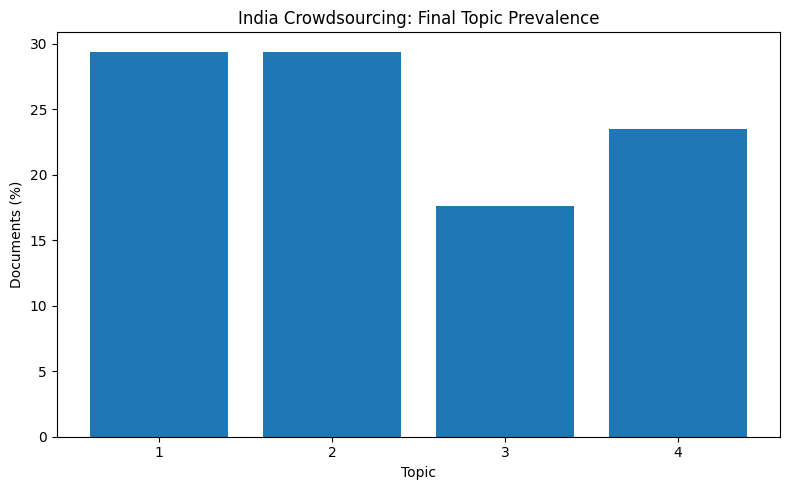


FINAL MODEL SUMMARY
{
    "final_documents": 34,
    "vocabulary_size": 729,
    "selected_K": 4,
    "selected_coherence_cv": 0.38216893584670963,
    "random_seed": 42
}

MODEL SELECTION


,K,Coherence_CV,Documents,Vocabulary_Size
2,4,0.382169,34,729
1,3,0.352714,34,729
0,2,0.320669,34,729



TOPIC KEYWORDS


,Topic,Rank,Keyword,Probability
0,1,1,work,0.025287
1,1,2,learning,0.018057
2,1,3,workers,0.017166
3,1,4,heritage,0.017130
4,1,5,online,0.013663
...,...,...,...,...
75,4,16,digital,0.007211
76,4,17,field,0.006498
77,4,18,level,0.006496
78,4,19,remote,0.006496



TOPIC PREVALENCE


,Dominant_Topic,Documents,Mean_Topic_Probability,Document_Percentage
0,1,10,0.972900,29.411765
1,2,10,0.929887,29.411765
2,3,6,0.923161,17.647059
3,4,8,0.955261,23.529412



DOCUMENT ASSIGNMENTS


,Document_ID,Title,Year,Category,Dominant_Topic,Dominant_Topic_Probability,Topic_1_Probability,Topic_2_Probability,Topic_3_Probability,Topic_4_Probability
0,IND_FINAL_001,Does crowdsourcing services moderate effect on supply risk management performance in COVID-19 pandemic: evidence from India,2022,DIRECT_SME_MSME,4,0.987566,0.004069,0.004093,0.004272,0.987566
1,IND_FINAL_002,Closing the Feedback Loop: Can Technology Bridge the Accountability Gap?,2014,DOMAIN_ADJACENT,2,0.994441,0.001824,0.994441,0.001818,0.001916
2,IND_FINAL_003,Project Antares and crowdsourcing in India : exploring the beneficiaries' perceptions of healthcare priorities,2014,DOMAIN_ADJACENT,1,0.984494,0.984494,0.005285,0.005157,0.005064
3,IND_FINAL_004,Feasibility assessment of crowdsourcing slogans for promoting household waste segregation in India: a cross-sectional study,2023,DOMAIN_ADJACENT,2,0.990655,0.003112,0.990655,0.003121,0.003111
4,IND_FINAL_005,Understanding community insights on waste segregation and environmental health using a photovoice based crowdsourcing approach in India,2026,DOMAIN_ADJACENT,2,0.991068,0.002947,0.991068,0.003010,0.002975
5,IND_FINAL_006,An ethnographic study of crowdwork via Amazon Mechanical Turk in India,2017,DOMAIN_ADJACENT,1,0.996516,0.996516,0.001174,0.001157,0.001153
6,IND_FINAL_007,Privacy Attitudes of Mechanical Turk Workers and the U.S. Public,2014,DOMAIN_ADJACENT,1,0.990861,0.990861,0.003049,0.003062,0.003028
7,IND_FINAL_008,"Setting research priorities for maternal, newborn, child health and nutrition in India by engaging experts from 256 indigenous institutions contributing over 4000 research ideas: a CHNRI exercise by ICMR and INCLEN",2017,DOMAIN_ADJACENT,2,0.993846,0.002026,0.993846,0.002096,0.002032
8,IND_FINAL_009,Digital libraries for minor languages in India: frameworks for addressing absences in policy and governance,2024,DOMAIN_ADJACENT,2,0.867474,0.127783,0.867474,0.002394,0.002349
9,IND_FINAL_010,Pitch to policy program in India and Indonesia - a co-creation approach towards decarbonisation,2024,DOMAIN_ADJACENT,3,0.988124,0.003961,0.003966,0.988124,0.003949


In [ ]:

!pip -q install gensim pandas numpy matplotlib

import os, re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gensim import corpora
from gensim.models import LdaModel, CoherenceModel
from gensim.parsing.preprocessing import STOPWORDS

BASE = "/content/India_Cleaning"
INPUT = os.path.join(BASE, "India_Final_Broad_Corpus.csv")
OUT = os.path.join(BASE, "India_Final_LDA")
os.makedirs(OUT, exist_ok=True)

SEED = 42
np.random.seed(SEED)

df = pd.read_csv(INPUT).fillna("")

# Ensure each record has a stable identifier
if "Document_ID" not in df.columns:
    df["Document_ID"] = [
        f"IND_FINAL_{i:03d}" for i in range(1, len(df)+1)
    ]

df["Model_Text"] = df["Title"].astype(str) + " " + df["Abstract"].astype(str)
df = df[df["Model_Text"].str.strip().ne("")].copy()

print("Documents:", len(df))
print("Category distribution:")
print(df["Category"].value_counts())

# Conservative preprocessing
custom_stopwords = set(STOPWORDS).union({
    "india", "indian", "study", "studies", "paper",
    "research", "article", "results", "analysis",
    "using", "used", "based", "approach", "method",
    "methods", "findings", "purpose", "aim",
    "conclusion", "crowdsourcing", "crowdsource",
    "crowdsourced", "crowd"
})

def preprocess(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"crowd[\s-]+sourcing", "crowdsourcing", text)
    tokens = re.findall(r"[a-z][a-z0-9]{2,}", text)
    return [t for t in tokens if t not in custom_stopwords]

tokens = [preprocess(x) for x in df["Model_Text"]]

# Retain documents with at least five usable tokens
valid_idx = [i for i, t in enumerate(tokens) if len(t) >= 5]
df = df.iloc[valid_idx].reset_index(drop=True)
tokens = [tokens[i] for i in valid_idx]

print("Documents after token validation:", len(df))

dictionary = corpora.Dictionary(tokens)
dictionary.filter_extremes(
    no_below=2,
    no_above=0.90,
    keep_n=3000
)

if len(dictionary) < 15:
    dictionary = corpora.Dictionary(tokens)
    dictionary.filter_extremes(
        no_below=1,
        no_above=0.95,
        keep_n=3000
    )

bow = [dictionary.doc2bow(t) for t in tokens]

print("Vocabulary size:", len(dictionary))

if len(df) < 20 or len(dictionary) < 10:
    raise ValueError(
        "Insufficient documents or vocabulary for the planned LDA analysis."
    )

# Candidate topic counts
candidate_ks = [2, 3, 4]
models = {}
selection = []

for k in candidate_ks:
    model = LdaModel(
        corpus=bow,
        id2word=dictionary,
        num_topics=k,
        random_state=SEED,
        passes=30,
        iterations=400,
        chunksize=50,
        alpha="symmetric",
        eta="auto",
        minimum_probability=0,
        eval_every=None
    )

    cv = CoherenceModel(
        model=model,
        texts=tokens,
        dictionary=dictionary,
        coherence="c_v"
    ).get_coherence()

    models[k] = model

    selection.append({
        "K": k,
        "Coherence_CV": cv,
        "Documents": len(df),
        "Vocabulary_Size": len(dictionary)
    })

selection = pd.DataFrame(selection).sort_values(
    ["Coherence_CV", "K"],
    ascending=[False, True]
)

selection.to_csv(
    os.path.join(OUT, "Final_LDA_Model_Selection.csv"),
    index=False
)

best_k = int(selection.iloc[0]["K"])
best_model = models[best_k]

# Topic keywords
topic_rows = []

for topic in range(best_k):
    for rank, (word, prob) in enumerate(
        best_model.show_topic(topic, topn=20), 1
    ):
        topic_rows.append({
            "Topic": topic + 1,
            "Rank": rank,
            "Keyword": word,
            "Probability": prob
        })

topics = pd.DataFrame(topic_rows)
topics.to_csv(
    os.path.join(OUT, "Final_LDA_Topic_Keywords.csv"),
    index=False
)

# Document-topic assignments
assignment_rows = []

for i, doc_bow in enumerate(bow):
    distribution = dict(
        best_model.get_document_topics(
            doc_bow, minimum_probability=0
        )
    )

    dominant = max(distribution, key=distribution.get)

    row = {
        "Document_ID": df.iloc[i]["Document_ID"],
        "Title": df.iloc[i]["Title"],
        "Year": df.iloc[i]["Year"],
        "Category": df.iloc[i]["Category"],
        "Dominant_Topic": dominant + 1,
        "Dominant_Topic_Probability": distribution[dominant]
    }

    for t in range(best_k):
        row[f"Topic_{t+1}_Probability"] = distribution[t]

    assignment_rows.append(row)

assignments = pd.DataFrame(assignment_rows)
assignments.to_csv(
    os.path.join(OUT, "Final_LDA_Document_Assignments.csv"),
    index=False
)

# Topic prevalence
prevalence = (
    assignments.groupby("Dominant_Topic")
    .agg(
        Documents=("Document_ID", "count"),
        Mean_Topic_Probability=(
            "Dominant_Topic_Probability", "mean"
        )
    )
    .reset_index()
)

prevalence["Document_Percentage"] = (
    prevalence["Documents"] / len(assignments) * 100
)

prevalence.to_csv(
    os.path.join(OUT, "Final_LDA_Topic_Prevalence.csv"),
    index=False
)

# Plot prevalence
plt.figure(figsize=(8, 5))
plt.bar(
    prevalence["Dominant_Topic"].astype(str),
    prevalence["Document_Percentage"]
)
plt.xlabel("Topic")
plt.ylabel("Documents (%)")
plt.title("India Crowdsourcing: Final Topic Prevalence")
plt.tight_layout()
plt.savefig(
    os.path.join(OUT, "Final_LDA_Topic_Prevalence.png"),
    dpi=300
)
plt.show()

# Save model and dictionary
best_model.save(os.path.join(OUT, "Final_India_LDA_Model"))
dictionary.save(os.path.join(OUT, "Final_India_Dictionary"))

summary = {
    "final_documents": len(df),
    "vocabulary_size": len(dictionary),
    "selected_K": best_k,
    "selected_coherence_cv": float(selection.iloc[0]["Coherence_CV"]),
    "random_seed": SEED
}

with open(os.path.join(OUT, "Final_LDA_Summary.json"), "w") as f:
    json.dump(summary, f, indent=4)

print("\nFINAL MODEL SUMMARY")
print(json.dumps(summary, indent=4))

print("\nMODEL SELECTION")
display(selection)

print("\nTOPIC KEYWORDS")
display(topics)

print("\nTOPIC PREVALENCE")
display(prevalence)

print("\nDOCUMENT ASSIGNMENTS")
display(assignments)


In [ ]:
print("=" * 80)
print("FINAL INDIA LDA: COMPLETE TOPIC KEYWORDS")
print("=" * 80)

for topic in sorted(topics["Topic"].unique()):
    subset = topics[topics["Topic"] == topic].sort_values("Rank")

    print(f"\nTOPIC {topic}")
    print("-" * 60)

    print(", ".join(
        f"{row.Keyword} ({row.Probability:.4f})"
        for row in subset.itertuples()
    ))

print("\n" + "=" * 80)
print("REPRESENTATIVE DOCUMENTS")
print("=" * 80)

for topic in sorted(assignments["Dominant_Topic"].unique()):
    subset = assignments[
        assignments["Dominant_Topic"] == topic
    ].sort_values(
        "Dominant_Topic_Probability",
        ascending=False
    ).head(5)

    print(f"\nTOPIC {topic}")
    print("-" * 60)

    for row in subset.itertuples():
        print(
            f"{row.Title} "
            f"[{row.Year}; probability={row.Dominant_Topic_Probability:.3f}]"
        )

FINAL INDIA LDA: COMPLETE TOPIC KEYWORDS

TOPIC 1
------------------------------------------------------------
work (0.0253), learning (0.0181), workers (0.0172), heritage (0.0171), online (0.0137), cultural (0.0126), data (0.0118), legal (0.0118), mturk (0.0082), information (0.0082), platform (0.0078), use (0.0072), social (0.0067), platforms (0.0065), privacy (0.0065), transfer (0.0065), public (0.0061), services (0.0059), framework (0.0057), future (0.0056)

TOPIC 2
------------------------------------------------------------
waste (0.0138), health (0.0120), languages (0.0120), platforms (0.0119), work (0.0109), value (0.0101), technologies (0.0095), national (0.0092), online (0.0092), digital (0.0091), new (0.0088), libraries (0.0083), like (0.0069), countries (0.0066), development (0.0066), management (0.0066), exercise (0.0066), segregation (0.0066), context (0.0065), use (0.0058)

TOPIC 3
------------------------------------------------------------
community (0.0154), income (0